# NFL Big Data Bowl 2027 — `arda_main.ipynb`
## Cross-Context Kinetic Decay & Cognitive Load: Measuring the "Pad-Speed Drop-off" (KTR), Centripetal Bend ($v \cdot \omega$), and Torso-Motion Dissociation ($\Delta \theta$) from Combine Drills to Live NFL Regular-Season Games

### Mimari Özeti ve Kritik Metodolojik Yaklaşımlar (9 Modüllü Uçtan Uca Pipeline)
1. **Modül 1 — Veri Hijyeni & Fiziksel/Kinematik Fonksiyonlar**
2. **Modül 2 — DuckDB & Parquet Pozisyon Bazlı Parçalama Motoru (`season_type == 'REG'` Filtresi)**
3. **Modül 3 — Elma-Elma (Apples-to-Apples) 3 Aşamalı Kinetik Erime Hunisi (`KTR_Track` & `KTR_Skill`)**
4. **Modül 4 — 5 Pozisyon Grubu Sinyal Keşfi**
5. **Modül 5 — Genel Görselleştirme Laboratuvarı**
6. **Modül 6 — Doğrulama (Validation), Kararlılık (Split-Half Reliability) ve Benchmark Lift Laboratuvarı**
7. **Modül 7 (WR Odaklı Adım 1) — Pre-Draft WR KTR & DEI Tahmincisi**
8. **Modül 8 (WR Odaklı Adım 2) — 10 Hz Frame-by-Frame Vaka Analizi (Marvin Mims `4.38s` vs. Xavier Legette `4.39s`)**
9. **Modül 9 — Klasik Model vs. Bizim Modelimiz: Doğruluk Oranı (Accuracy %, ROC-AUC %, $R^2$ % ve Top-10 İsabet %) Değerli Karşılaştırma Paneli**

In [ ]:
import plt
import sns

# ==============================================================================
# MODÜL 5: GÖRSELLEŞTİRME LABORATUVARI (FUNNEL, QUADRANT & TORSO DISSOCIATION)
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

stage_plot_df = (
    reg_active.groupby('combine_position')[['forty_vmax', 's2_v95', 'nfl_v95', 'nfl_vmax']]
    .mean()
    .loc[['WR', 'DB', 'TE', 'DL', 'OL']]
)
stage_plot_df.columns = ['1. Combine 40-Yd (Max)', '2. Combine Skill (P95)', '3. NFL REG (P95)', '4. NFL REG (Max)']
stage_plot_df.T.plot(kind='line', marker='o', linewidth=2.5, markersize=8, ax=axes[0])
axes[0].set_title('A) 3-Stage Kinetic Decay Funnel (REG Season)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Speed (yards / second)', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(title='Combine Position', frameon=True)

skill_40 = reg_active[
    reg_active['combine_position'].isin(['WR', 'DB', 'TE']) &
    reg_active['forty_vmax'].notna() &
    (reg_active['total_career_snaps'] >= 150)
].copy()
x_med = skill_40['forty_vmax'].median()
y_med = skill_40['nfl_v95'].median()

sns.scatterplot(
    data=skill_40,
    x='forty_vmax',
    y='nfl_v95',
    hue='combine_position',
    size='total_career_snaps',
    sizes=(40, 240),
    alpha=0.85,
    ax=axes[1]
)
axes[1].axvline(x_med, color='red', linestyle='--', alpha=0.6)
axes[1].axhline(y_med, color='red', linestyle='--', alpha=0.6)
axes[1].set_title('B) Workout Warriors vs. True Gamers (40-Yd Runners)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Combine 40-Yard Peak Speed in Shorts (yds/s)', fontsize=11)
axes[1].set_ylabel('NFL Regular-Season P95 Speed in Pads (yds/s)', fontsize=11)

top_gems = skill_40.sort_values('KTR_Track_Speed', ascending=False).head(4)
top_warriors = skill_40.sort_values('KTR_Track_Speed', ascending=True).head(4)
for _, row in pd.concat([top_gems, top_warriors]).iterrows():
    axes[1].annotate(
        row['display_name'],
        (row['forty_vmax'], row['nfl_v95']),
        xytext=(4, 4), textcoords='offset points', fontsize=8
    )

wr_sub = reg_active[(reg_active['combine_position'] == 'WR') & reg_active['Torso_Dissoc_Efficiency'].notna() & reg_active['p90_separation'].notna()].copy()
sns.regplot(
    data=wr_sub,
    x='Torso_Dissoc_Efficiency',
    y='p90_separation',
    scatter_kws={'alpha': 0.75, 's': 65, 'color': '#1f77b4'},
    line_kws={'color': 'darkred', 'linewidth': 2},
    ax=axes[2]
)
r_val, p_val = stats.pearsonr(wr_sub['Torso_Dissoc_Efficiency'], wr_sub['p90_separation'])
axes[2].set_title(f'C) WR Torso Dissociation vs. P90 Separation\n(r = +{r_val:.2f}, p = {p_val:.4f}, N = {len(wr_sub)})', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Torso-Motion Dissociation Efficiency (Speed at |o - dir| >= 45° / < 25°)', fontsize=10.5)
axes[2].set_ylabel('NFL Regular-Season 90th Pct Separation (yards)', fontsize=11)

for _, row in wr_sub.sort_values('p90_separation', ascending=False).head(5).iterrows():
    axes[2].annotate(row['display_name'], (row['Torso_Dissoc_Efficiency'], row['p90_separation']), xytext=(4, 4), textcoords='offset points', fontsize=8)

plt.tight_layout()
plt.savefig(CACHE_DIR / 'figures' / 'ktr_funnel_and_quadrant.png', dpi=150)
plt.show()

cols_show = ['display_name', 'combine_position', 'draft_year', 'draft_round', 'forty', 'forty_vmax', 's2_v95', 'nfl_v95', 'KTR_Track_Speed', 'KTR_Skill_Speed', 'Torso_Dissoc_Efficiency', 'total_career_snaps']
print('\n=== EN YÜKSEK KTR_TRACK_SPEED (TRUE GAMERS / HIDDEN GEMS - 40-YD RUNNERS, >=150 SNAPS) ===')
display(skill_40.sort_values('KTR_Track_Speed', ascending=False)[cols_show].head(10))

print('\n=== EN DÜŞÜK KTR_TRACK_SPEED (WORKOUT WARRIORS / PAD-SPEED DROP-OFF - 40-YD RUNNERS, >=150 SNAPS) ===')
display(skill_40.sort_values('KTR_Track_Speed', ascending=True)[cols_show].head(10))

In [1]:
# ==============================================================================
# MODÜL 1: ORTAM KURULUMU, VERİ HİJYENİ VE KİNEMATİK YARDIMCI FONKSİYONLAR
# ==============================================================================
import os
import time
import warnings
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import polars as pl
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
sns.set_theme(style='whitegrid', palette='deep')

# Klasör Yolları
DATA_DIR = Path('nfl-big-data-bowl-2027/nfl-big-data-bowl-2027')
CACHE_DIR = Path('data_cache')
CACHE_DIR.mkdir(exist_ok=True)
(CACHE_DIR / 'by_position').mkdir(exist_ok=True)
(CACHE_DIR / 'figures').mkdir(exist_ok=True)

# Yıllar arası farklı yazılmış Combine drill isimlerini standartlaştırma sözlüğü
DRILL_NAME_CLEAN_MAP = {
    'PASS_PRO-MIRROR_DRILL': 'PASS_PRO_MIRROR_DRILL',
    'OVER_THE_SHOULDER_ADJUST': 'OVER_SHOULDER_ADJUST',
    'SPEED_OUT_LEFT': 'SPEED_OUT_ROUTE_LEFT',
    'LINE': 'LINE_DRILL',
}

# Saf Atletik Testler (Stage 1) vs Pozisyon/Bilişsel Driller (Stage 2)
ATHLETIC_DRILL_TYPES = {'FORTY_YARD_DASH', 'THREE_CONE_DRILL', 'SHORT_SHUTTLE'}

print(f'Veri Klasörü: {DATA_DIR.resolve()}')
print(f'Önbellek Klasörü: {CACHE_DIR.resolve()}')

Veri Klasörü: C:\Users\arda2\Documents\GitHub\NFL_Big_Data_Bowl\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027
Önbellek Klasörü: C:\Users\arda2\Documents\GitHub\NFL_Big_Data_Bowl\data_cache


In [2]:
# ==============================================================================
# MODÜL 2: DUCKDB & PARQUET TABANLI POZİSYON PARÇALAMA MOTORU
# ==============================================================================
t0 = time.time()
con = duckdb.connect(database=':memory:')

# 1. Temel Oyuncu, Combine Sonuçları ve Kariyer Başarı Tablolarını Yükle & Birleştir
players_df = pd.read_csv(DATA_DIR / 'players.csv')
combine_res_df = pd.read_csv(DATA_DIR / 'combine_results.csv')
career_df = pd.read_csv(DATA_DIR / 'player_career_successes.csv')

master_players = (
    players_df
    .merge(combine_res_df, on=['nfl_id', 'draft_year'], how='left')
    .merge(career_df, on='nfl_id', how='left')
)
master_players['total_career_snaps'] = (
    master_players['career_offensive_snaps'].fillna(0)
    + master_players['career_defensive_snaps'].fillna(0)
)
master_players['starter_ratio'] = np.where(
    master_players['career_games_active'] > 0,
    master_players['career_games_started'] / master_players['career_games_active'],
    0.0
)
master_players.to_parquet(CACHE_DIR / 'master_players.parquet', index=False)

print('=== 5 ANA COMBINE POZİSYON GRUBU DAĞILIMI ===')
pos_summary = master_players.groupby('combine_position').agg(
    player_count=('nfl_id', 'count'),
    nfl_positions=('nfl_position', lambda x: ', '.join([f'{k}:{v}' for k, v in x.value_counts().items()])),
    avg_forty=('forty', 'mean'),
    avg_weight=('combine_weight', 'mean'),
    avg_snaps=('total_career_snaps', 'mean')
).reset_index()
display(pos_summary)

# 2. Combine Tracking Verisini Temizle, Fiziksel Türevleri (omega, a_c, Power) Ekle ve Pozisyonlara Böl
print('\n[1/3] combine_tracking.csv işleniyor ve pozisyonlara göre parçalanıyor...')
comb_raw = pd.read_csv(DATA_DIR / 'combine_tracking.csv')
comb_raw['drill_name'] = comb_raw['drill_name'].replace(DRILL_NAME_CLEAN_MAP)
comb_raw['stage_type'] = np.where(
    comb_raw['drill_type'].isin(ATHLETIC_DRILL_TYPES),
    'STAGE1_ATHLETIC_TRACK',
    'STAGE2_POSITION_SKILL'
)

# Oyuncu ve Top (BALL) satırlarını ayır
comb_balls = comb_raw[comb_raw['entity_type'] == 'BALL'][[
    'event_id', 'time', 'x', 'y', 's', 'a'
]].rename(columns={'x': 'ball_x', 'y': 'ball_y', 's': 'ball_s', 'a': 'ball_a'})
comb_balls.to_parquet(CACHE_DIR / 'combine_ball_tracking.parquet', index=False)

comb_players = comb_raw[comb_raw['entity_type'] == 'PLAYER'].copy()
comb_players['nfl_id'] = comb_players['nfl_id'].astype(int)
comb_players = comb_players.merge(
    master_players[['nfl_id', 'display_name', 'combine_position', 'nfl_position', 'combine_weight']],
    on='nfl_id',
    how='left'
)

# Top (BALL) koordinatlarını aynı event_id ve time üzerinden oyuncuya bağla
comb_players = comb_players.merge(comb_balls, on=['event_id', 'time'], how='left')
comb_players['ball_dist'] = np.sqrt(
    (comb_players['x'] - comb_players['ball_x'])**2 +
    (comb_players['y'] - comb_players['ball_y'])**2
)
comb_players['ball_in_play'] = comb_players['ball_dist'].notna()

# Sıralama ve Frame-to-Frame Kinematik Türevler (10 Hz -> dt = 0.1s)
comb_players = comb_players.sort_values(['nfl_id', 'event_id', 'attempt', 'time']).reset_index(drop=True)
grp = comb_players.groupby(['nfl_id', 'event_id', 'attempt'])

prev_dir = grp['dir'].shift(1)
prev_s = grp['s'].shift(1)
raw_ddir = (comb_players['dir'] - prev_dir).abs()
comb_players['delta_dir'] = np.minimum(raw_ddir, 360.0 - raw_ddir)

# Açısal Hız (Angular Velocity omega - derece/saniye ve radyan/saniye, 10 Hz)
comb_players['omega_deg_s'] = comb_players['delta_dir'] * 10.0
comb_players['omega_rad_s'] = np.deg2rad(comb_players['omega_deg_s'])

# İmzalı Teğetsel İvme (Signed Acceleration: + İvmelenme, - Frenleme/Deceleration)
comb_players['signed_accel'] = (comb_players['s'] - prev_s) * 10.0

# Merkezcil İvme (Centripetal Accel / Bend Force: a_c = v * omega) ve Mekanik Güç (P = v * a)
comb_players['centripetal_accel'] = comb_players['s'] * comb_players['omega_rad_s']
comb_players['mechanical_power_proxy'] = comb_players['s'] * comb_players['a']

# Pozisyon bazlı Parquet dosyalarına kaydet
for pos, df_pos in comb_players.groupby('combine_position'):
    df_pos.to_parquet(CACHE_DIR / 'by_position' / f'combine_tracking_{pos}.parquet', index=False)

print(f'Combine Tracking parçalandı ({len(comb_players):,} oyuncu satırı, {len(comb_balls):,} top satırı). Süre: {time.time()-t0:.1f}s')

=== 5 ANA COMBINE POZİSYON GRUBU DAĞILIMI ===


,combine_position,player_count,nfl_positions,avg_forty,avg_weight,avg_snaps
0,DB,122,"CB:60, SS:28, FS:25, DB:5, ILB:2, RB:1, MLB:1",4.492115,195.270492,548.491803
1,DL,118,"DT:47, DE:36, OLB:30, NT:5",4.857553,281.593220,445.838983
2,OL,121,"G:51, T:50, C:20",5.153053,314.471074,715.553719
3,TE,42,"TE:41, FB:1",4.702353,249.404762,464.595238
4,WR,107,"WR:106, TE:1",4.472165,197.168224,568.775701



[1/3] combine_tracking.csv işleniyor ve pozisyonlara göre parçalanıyor...
Combine Tracking parçalandı (431,094 oyuncu satırı, 32,095 top satırı). Süre: 12.3s


In [3]:
# ==============================================================================
# MODÜL 2B: 2 GB NFL GAME TRACKING (2023-2025) & REGULAR SEASON (REG) FİLTRESİ
# ==============================================================================
t1 = time.time()
print('[2/3] DuckDB ile game_tracking_2023/2024/2025.csv (2.0 GB), games.csv ve player_play.csv taranıyor...')

nfl_play_summary_path = CACHE_DIR / 'nfl_play_level_kinematics.parquet'

if not nfl_play_summary_path.exists():
    query = f"""
    COPY (
        WITH raw_gt AS (
            SELECT
                TRY_CAST(game_id AS BIGINT) AS game_id,
                TRY_CAST(play_id AS INTEGER) AS play_id,
                TRY_CAST(nfl_id AS INTEGER) AS nfl_id,
                time,
                TRY_CAST(x AS DOUBLE) AS x,
                TRY_CAST(y AS DOUBLE) AS y,
                TRY_CAST(s AS DOUBLE) AS s,
                TRY_CAST(a AS DOUBLE) AS a,
                TRY_CAST(dis AS DOUBLE) AS dis,
                TRY_CAST(o AS DOUBLE) AS o,
                TRY_CAST(dir AS DOUBLE) AS dir,
                event
            FROM read_csv_auto('{DATA_DIR.as_posix()}/game_tracking_*.csv', union_by_name=true)
            WHERE s IS NOT NULL
        ),
        kinematics AS (
            SELECT
                *,
                -- Torso-Motion Dissociation: Delta Theta = min(|o - dir|, 360 - |o - dir|)
                LEAST(ABS(o - dir), 360.0 - ABS(o - dir)) AS torso_dissociation_deg,
                -- Frame-to-frame yön değişimi (Angular velocity için)
                LEAST(
                    ABS(dir - LAG(dir) OVER (PARTITION BY game_id, play_id, nfl_id ORDER BY time)),
                    360.0 - ABS(dir - LAG(dir) OVER (PARTITION BY game_id, play_id, nfl_id ORDER BY time))
                ) * 10.0 AS omega_deg_s,
                -- Frame-to-frame imzalı ivme (frenleme tespiti için)
                (s - LAG(s) OVER (PARTITION BY game_id, play_id, nfl_id ORDER BY time)) * 10.0 AS signed_accel
            FROM raw_gt
        )
        SELECT
            game_id,
            play_id,
            nfl_id,
            COUNT(*) AS n_frames,
            MAX(s) AS play_max_speed,
            QUANTILE_CONT(s, 0.90) AS play_p90_speed,
            MAX(a) AS play_max_accel,
            MIN(signed_accel) AS play_max_decel,
            MAX(CASE WHEN s >= 2.5 THEN omega_deg_s ELSE NULL END) AS play_max_omega_moving,
            AVG(CASE WHEN s >= 3.0 THEN torso_dissociation_deg ELSE NULL END) AS avg_torso_dissoc_moving,
            MAX(CASE WHEN torso_dissociation_deg >= 45.0 THEN s ELSE NULL END) AS max_speed_high_dissoc,
            MAX(CASE WHEN torso_dissociation_deg < 25.0 THEN s ELSE NULL END) AS max_speed_low_dissoc,
            MAX(CASE WHEN torso_dissociation_deg >= 45.0 THEN a ELSE NULL END) AS max_accel_high_dissoc
        FROM kinematics
        GROUP BY game_id, play_id, nfl_id
    ) TO '{nfl_play_summary_path.as_posix()}' (FORMAT PARQUET, COMPRESSION ZSTD);
    """
    con.execute(query)
    print(f'Play-level NFL kinematik özet tablosu oluşturuldu! Süre: {time.time()-t1:.1f}s')
else:
    print('Önbellekteki nfl_play_level_kinematics.parquet bulundu, doğrudan yükleniyor...')

# 3. games.csv (season_type) ve player_play.csv ile birleştirip Regular Season (REG) ayrımını yap
t2 = time.time()
join_query = f"""
    SELECT
        k.*,
        g.season,
        g.season_type,
        g.week,
        mp.display_name,
        mp.combine_position,
        mp.nfl_position,
        mp.draft_year,
        mp.draft_round,
        mp.draft_overall_pick,
        pp.team_abbr,
        pp.lined_up_position,
        TRY_CAST(pp.quarter AS INTEGER) AS quarter,
        TRY_CAST(pp.down AS INTEGER) AS down,
        TRY_CAST(pp.yards_to_go AS DOUBLE) AS yards_to_go,
        TRY_CAST(pp.expected_points_added AS DOUBLE) AS epa,
        pp.team_coverage_man_zone,
        pp.team_coverage_type,
        pp.route_ran,
        TRY_CAST(pp.target AS BOOLEAN) AS is_target,
        TRY_CAST(pp.rec_yards AS DOUBLE) AS rec_yards,
        TRY_CAST(pp.yards_after_catch AS DOUBLE) AS yac,
        TRY_CAST(pp.expected_yards_after_catch AS DOUBLE) AS xyac,
        TRY_CAST(pp.separation_at_pass_forward AS DOUBLE) AS separation,
        TRY_CAST(pp.cushion AS DOUBLE) AS cushion,
        TRY_CAST(pp.player_get_off AS DOUBLE) AS player_get_off,
        TRY_CAST(pp.time_to_pressure AS DOUBLE) AS time_to_pressure,
        TRY_CAST(pp.time_to_qb_hurry AS DOUBLE) AS time_to_qb_hurry,
        TRY_CAST(pp.sack AS DOUBLE) AS sack,
        TRY_CAST(pp.tackle AS DOUBLE) AS tackle,
        TRY_CAST(pp.assist AS DOUBLE) AS assist,
        TRY_CAST(pp.tackle_for_loss AS DOUBLE) AS tfl,
        TRY_CAST(pp.pressure_allowed AS BOOLEAN) AS pressure_allowed,
        TRY_CAST(pp.peak_pressure_probability_allowed AS DOUBLE) AS peak_pressure_prob_allowed,
        TRY_CAST(pp.sack_allowed AS DOUBLE) AS sack_allowed,
        TRY_CAST(pp.quick_pressure AS BOOLEAN) AS quick_pressure,
        pp.coverage_assignment
    FROM '{nfl_play_summary_path.as_posix()}' k
    JOIN read_csv_auto('{ (DATA_DIR / 'games.csv').as_posix() }') g
        ON k.game_id = TRY_CAST(g.game_id AS BIGINT)
    LEFT JOIN '{ (CACHE_DIR / 'master_players.parquet').as_posix() }' mp
        ON k.nfl_id = mp.nfl_id
    LEFT JOIN read_csv_auto('{ (DATA_DIR / 'player_play.csv').as_posix() }', nullstr='NA') pp
        ON k.game_id = TRY_CAST(pp.game_id AS BIGINT)
       AND k.play_id = TRY_CAST(pp.play_id AS INTEGER)
       AND k.nfl_id = TRY_CAST(pp.nfl_id AS INTEGER)
"""
nfl_all_plays_df = con.execute(join_query).df()

print('=== MAÇ TİPİNE (SEASON_TYPE) GÖRE OYUN VE OYUNCU DAĞILIMI ===')
st_summary = nfl_all_plays_df.groupby('season_type').agg(
    play_count=('play_id', 'count'),
    unique_players=('nfl_id', 'nunique'),
    avg_max_speed=('play_max_speed', 'mean')
).reset_index()
display(st_summary)

# Yarışma kuralı gereği Regular Season (REG) oyunlarını filtrele ve 5 pozisyona göre kaydet
nfl_reg_plays_df = nfl_all_plays_df[nfl_all_plays_df['season_type'] == 'REG'].copy()
nfl_reg_plays_df.to_parquet(CACHE_DIR / 'nfl_reg_enriched_plays_all.parquet', index=False)

for pos, df_pos in nfl_reg_plays_df.groupby('combine_position'):
    df_pos.to_parquet(CACHE_DIR / 'by_position' / f'nfl_reg_plays_{pos}.parquet', index=False)

print(f'Regular Season (REG) {len(nfl_reg_plays_df):,} oyuncu-oyun kaydı 5 pozisyona ayrıldı! Süre: {time.time()-t2:.1f}s')

[2/3] DuckDB ile game_tracking_2023/2024/2025.csv (2.0 GB), games.csv ve player_play.csv taranıyor...
Önbellekteki nfl_play_level_kinematics.parquet bulundu, doğrudan yükleniyor...
=== MAÇ TİPİNE (SEASON_TYPE) GÖRE OYUN VE OYUNCU DAĞILIMI ===


,season_type,play_count,unique_players,avg_max_speed
0,POST,13045,159,4.733384
1,PRE,50792,487,4.718863
2,REG,251107,401,4.733982


Regular Season (REG) 251,107 oyuncu-oyun kaydı 5 pozisyona ayrıldı! Süre: 12.2s


In [4]:
# ==============================================================================
# MODÜL 3: ELMA-ELMA (APPLES-TO-APPLES) 3-STAGE KINETIC DECAY & KTR ENGINEERING
# ==============================================================================
forty_df = comb_players[comb_players['drill_type'] == 'FORTY_YARD_DASH'].groupby('nfl_id').agg(
    forty_vmax=('s', 'max'),
    forty_amax=('a', 'max'),
    forty_a95=('a', lambda x: np.nanpercentile(x, 95)),
).reset_index()

s1_df = comb_players[comb_players['stage_type'] == 'STAGE1_ATHLETIC_TRACK']
stage1_agg = s1_df.groupby('nfl_id').agg(
    s1_vmax=('s', 'max'),
    s1_v95=('s', lambda x: np.nanpercentile(x, 95)),
    s1_amax=('a', 'max'),
    s1_a95=('a', lambda x: np.nanpercentile(x, 95)),
).reset_index()

s2_df = comb_players[comb_players['stage_type'] == 'STAGE2_POSITION_SKILL']
stage2_agg = s2_df.groupby('nfl_id').agg(
    s2_vmax=('s', 'max'),
    s2_v95=('s', lambda x: np.nanpercentile(x, 95)),
    s2_amax=('a', 'max'),
    s2_a95=('a', lambda x: np.nanpercentile(x, 95)),
    s2_decel5=('signed_accel', lambda x: np.nanpercentile(x.dropna(), 5) if len(x.dropna()) > 0 else np.nan),
    s2_omega95=('omega_deg_s', lambda x: np.nanpercentile(x[s2_df.loc[x.index, 's'] >= 2.5], 95) if (s2_df.loc[x.index, 's'] >= 2.5).any() else np.nan),
    s2_centripetal95=('centripetal_accel', lambda x: np.nanpercentile(x.dropna(), 95) if len(x.dropna()) > 0 else np.nan),
    s2_power95=('mechanical_power_proxy', lambda x: np.nanpercentile(x.dropna(), 95) if len(x.dropna()) > 0 else np.nan),
    s2_v95_ball_active=('s', lambda x: np.nanpercentile(x[s2_df.loc[x.index, 'ball_in_play']], 95) if s2_df.loc[x.index, 'ball_in_play'].any() else np.nan),
    s2_v95_no_ball=('s', lambda x: np.nanpercentile(x[~s2_df.loc[x.index, 'ball_in_play']], 95) if (~s2_df.loc[x.index, 'ball_in_play']).any() else np.nan),
).reset_index()

def compute_stage3_reg_profile(df):
    q13 = df[df['quarter'].isin([1, 2, 3])]
    q4 = df[df['quarter'] == 4]

    g_all = df.groupby('nfl_id').agg(
        reg_plays_tracked=('play_id', 'count'),
        nfl_vmax=('play_max_speed', 'max'),
        nfl_v95=('play_max_speed', lambda x: np.nanpercentile(x, 95)),
        nfl_amax=('play_max_accel', 'max'),
        nfl_a95=('play_max_accel', lambda x: np.nanpercentile(x, 95)),
        nfl_decel5=('play_max_decel', lambda x: np.nanpercentile(x.dropna(), 5) if len(x.dropna()) > 0 else np.nan),
        nfl_omega95=('play_max_omega_moving', lambda x: np.nanpercentile(x.dropna(), 95) if len(x.dropna()) > 0 else np.nan),
        nfl_avg_torso_dissoc=('avg_torso_dissoc_moving', 'mean'),
        nfl_v95_high_dissoc=('max_speed_high_dissoc', lambda x: np.nanpercentile(x.dropna(), 95) if len(x.dropna()) >= 5 else np.nan),
        nfl_v95_low_dissoc=('max_speed_low_dissoc', lambda x: np.nanpercentile(x.dropna(), 95) if len(x.dropna()) >= 5 else np.nan),
        avg_epa=('epa', 'mean'),
        avg_separation=('separation', 'mean'),
        p90_separation=('separation', lambda x: np.nanpercentile(x.dropna(), 90) if len(x.dropna()) >= 5 else np.nan),
        avg_cushion=('cushion', 'mean'),
        avg_yac=('yac', 'mean'),
        yac_over_expected=('yac', lambda x: (x - df.loc[x.index, 'xyac']).mean()),
        target_rate=('is_target', lambda x: x.fillna(False).mean()),
        avg_get_off=('player_get_off', 'mean'),
        p10_get_off=('player_get_off', lambda x: np.nanpercentile(x.dropna(), 10) if len(x.dropna()) >= 5 else np.nan),
        avg_time_to_pressure=('time_to_pressure', 'mean'),
        quick_pressure_rate=('quick_pressure', lambda x: x.dropna().mean() if len(x.dropna()) >= 10 else np.nan),
        total_sacks=('sack', 'sum'),
        total_tackles=('tackle', lambda x: x.fillna(0).sum() + df.loc[x.index, 'assist'].fillna(0).sum()),
        total_tfl=('tfl', 'sum'),
        pressure_allowed_rate=('pressure_allowed', lambda x: x.dropna().mean() if len(x.dropna()) >= 10 else np.nan),
        avg_peak_pressure_prob_allowed=('peak_pressure_prob_allowed', 'mean'),
    ).reset_index()

    g_q13 = q13.groupby('nfl_id').agg(
        nfl_v95_q13=('play_max_speed', lambda x: np.nanpercentile(x, 95) if len(x) >= 10 else np.nan),
        nfl_a95_q13=('play_max_accel', lambda x: np.nanpercentile(x, 95) if len(x) >= 10 else np.nan),
    ).reset_index()
    g_q4 = q4.groupby('nfl_id').agg(
        nfl_v95_q4=('play_max_speed', lambda x: np.nanpercentile(x, 95) if len(x) >= 5 else np.nan),
        nfl_a95_q4=('play_max_accel', lambda x: np.nanpercentile(x, 95) if len(x) >= 5 else np.nan),
    ).reset_index()

    return g_all.merge(g_q13, on='nfl_id', how='left').merge(g_q4, on='nfl_id', how='left')

stage3_reg_agg = compute_stage3_reg_profile(nfl_reg_plays_df)

ktr_df = (
    master_players
    .merge(forty_df, on='nfl_id', how='left')
    .merge(stage1_agg, on='nfl_id', how='left')
    .merge(stage2_agg, on='nfl_id', how='left')
    .merge(stage3_reg_agg, on='nfl_id', how='left')
)

ktr_df['KTR_Track_Speed'] = ktr_df['nfl_v95'] / ktr_df['forty_vmax']
ktr_df['KTR_Track_Peak'] = ktr_df['nfl_vmax'] / ktr_df['forty_vmax']
ktr_df['KTR_Track_Accel'] = ktr_df['nfl_a95'] / ktr_df['forty_amax']
ktr_df['KTR_Skill_Speed'] = ktr_df['nfl_v95'] / ktr_df['s2_v95']
ktr_df['KTR_Skill_Accel'] = ktr_df['nfl_a95'] / ktr_df['s2_a95']
ktr_df['Comb_Track_to_Skill_Retention'] = ktr_df['s2_v95'] / ktr_df['forty_vmax']
ktr_df['Comb_Ball_Speed_Retention'] = ktr_df['s2_v95_ball_active'] / ktr_df['s2_v95_no_ball']
ktr_df['Torso_Dissoc_Efficiency'] = ktr_df['nfl_v95_high_dissoc'] / ktr_df['nfl_v95_low_dissoc']
ktr_df['Q4_Speed_Retention'] = ktr_df['nfl_v95_q4'] / ktr_df['nfl_v95_q13']

ktr_df.to_parquet(CACHE_DIR / 'master_player_ktr.parquet', index=False)
ktr_df.to_csv(CACHE_DIR / 'master_player_ktr.csv', index=False)

reg_active = ktr_df[ktr_df['reg_plays_tracked'] >= 25].copy()
print(f'En az 25 Regular Season (REG) oyunu izlenmiş aktif oyuncu sayısı: {len(reg_active)} / {len(ktr_df)}')

print('\n=== NEDEN POZİSYON DRİLLERİ (STAGE 2) KRİTİK? TEST KATILIM ORANLARI ===')
part_rows = []
for pos in ['WR', 'DB', 'TE', 'DL', 'OL']:
    sub = reg_active[reg_active['combine_position'] == pos]
    n = len(sub)
    part_rows.append({
        'Position': pos,
        'Active_REG_Players': n,
        '40_Yard_Dash_%': round(sub['forty_vmax'].notna().mean() * 100, 1),
        '3_Cone_%': round(sub['three_cone'].notna().mean() * 100, 1),
        'Short_Shuttle_%': round(sub['short_shuttle'].notna().mean() * 100, 1),
        'Position_Skill_Drills_%': round(sub['s2_v95'].notna().mean() * 100, 1),
    })
display(pd.DataFrame(part_rows))

print('\n=== 3 AŞAMALI KİNETİK ERİME HUNİSİ (REGULAR SEASON ORTALAMALARI) ===')
funnel_cols = [
    'forty_vmax', 's2_v95', 'nfl_v95', 'nfl_vmax',
    'KTR_Track_Speed', 'KTR_Skill_Speed', 'KTR_Skill_Accel',
    'Torso_Dissoc_Efficiency', 'Q4_Speed_Retention'
]
display(reg_active.groupby('combine_position')[funnel_cols].mean().round(3))

En az 25 Regular Season (REG) oyunu izlenmiş aktif oyuncu sayısı: 372 / 510

=== NEDEN POZİSYON DRİLLERİ (STAGE 2) KRİTİK? TEST KATILIM ORANLARI ===


,Position,Active_REG_Players,40_Yard_Dash_%,3_Cone_%,Short_Shuttle_%,Position_Skill_Drills_%
0,WR,76,89.5,32.9,39.5,100.0
1,DB,89,85.4,19.1,24.7,100.0
2,TE,28,85.7,42.9,50.0,100.0
3,DL,94,79.8,37.2,38.3,100.0
4,OL,85,81.2,45.9,51.8,100.0



=== 3 AŞAMALI KİNETİK ERİME HUNİSİ (REGULAR SEASON ORTALAMALARI) ===


,forty_vmax,s2_v95,nfl_v95,nfl_vmax,KTR_Track_Speed,KTR_Skill_Speed,KTR_Skill_Accel,Torso_Dissoc_Efficiency,Q4_Speed_Retention
combine_position,,,,,,,,,
DB,11.067,8.604,8.296,10.011,0.751,0.965,1.059,0.853,0.971
DL,10.082,7.584,6.580,8.201,0.654,0.868,0.761,0.773,0.951
OL,9.504,7.020,5.128,7.173,0.538,0.731,0.720,0.846,0.958
TE,10.502,8.844,8.024,9.267,0.764,0.908,1.059,0.988,0.992
WR,11.132,9.167,9.042,10.148,0.813,0.988,1.011,0.968,0.979


In [5]:
# ==============================================================================
# MODÜL 4: 5 POZİSYON GRUBUNDA SİNYAL KEŞFİ (PRE-DRAFT COMBINE & IN-GAME KTR)
# ==============================================================================
position_targets = {
    'WR': ['nfl_v95', 'avg_separation', 'p90_separation', 'avg_yac', 'yac_over_expected', 'target_rate', 'total_career_snaps', 'starter_ratio'],
    'TE': ['nfl_v95', 'avg_separation', 'p90_separation', 'avg_yac', 'target_rate', 'total_career_snaps', 'starter_ratio'],
    'DB': ['nfl_v95', 'nfl_a95', 'total_tackles', 'avg_cushion', 'target_rate', 'total_career_snaps', 'starter_ratio'],
    'DL': ['nfl_v95', 'nfl_a95', 'avg_get_off', 'p10_get_off', 'quick_pressure_rate', 'total_sacks', 'total_career_snaps', 'starter_ratio'],
    'OL': ['nfl_v95', 'nfl_a95', 'pressure_allowed_rate', 'avg_peak_pressure_prob_allowed', 'total_career_snaps', 'starter_ratio'],
}

predictors = [
    'forty', 'three_cone', 'short_shuttle',
    'forty_vmax', 'forty_amax', 's2_v95', 's2_a95', 's2_centripetal95', 's2_power95', 's2_decel5',
    'Comb_Track_to_Skill_Retention',
    'KTR_Track_Speed', 'KTR_Skill_Speed', 'KTR_Skill_Accel', 'Torso_Dissoc_Efficiency', 'Q4_Speed_Retention'
]

signal_rows = []
for pos, targets in position_targets.items():
    sub = reg_active[reg_active['combine_position'] == pos]
    for pred in predictors:
        for targ in targets:
            valid = sub[[pred, targ]].dropna()
            if len(valid) >= 18 and valid[pred].nunique() > 3 and valid[targ].nunique() > 3:
                r, pval = stats.pearsonr(valid[pred], valid[targ])
                rho, _ = stats.spearmanr(valid[pred], valid[targ])
                if pval < 0.05:
                    signal_rows.append({
                        'Position': pos,
                        'Predictor': pred,
                        'NFL_REG_Target': targ,
                        'N': len(valid),
                        'Pearson_r': round(r, 3),
                        'Spearman_rho': round(rho, 3),
                        'p_value': round(pval, 4),
                        'abs_r': abs(r)
                    })

signals_df = pd.DataFrame(signal_rows).sort_values('abs_r', ascending=False)

for pos in ['WR', 'DB', 'DL', 'OL', 'TE']:
    print(f'\n================ {pos} POZİSYONU İSTATİSTİKSEL ANLAMLI SİNYALLER (p < 0.05) ================')
    display(signals_df[signals_df['Position'] == pos].drop(columns=['abs_r']).head(12))


================ WR POZİSYONU İSTATİSTİKSEL ANLAMLI SİNYALLER (p < 0.05) ================


,Position,Predictor,NFL_REG_Target,N,Pearson_r,Spearman_rho,p_value
14,WR,KTR_Track_Speed,nfl_v95,68,0.753,0.735,0.0000
16,WR,KTR_Skill_Speed,nfl_v95,76,0.629,0.668,0.0000
5,WR,forty_vmax,nfl_v95,68,0.597,0.639,0.0000
0,WR,forty,nfl_v95,70,-0.525,-0.562,0.0000
3,WR,three_cone,starter_ratio,25,-0.510,-0.519,0.0092
2,WR,three_cone,target_rate,25,-0.436,-0.389,0.0293
17,WR,Torso_Dissoc_Efficiency,nfl_v95,76,0.414,0.365,0.0002
1,WR,three_cone,p90_separation,25,-0.401,-0.399,0.0471
4,WR,short_shuttle,starter_ratio,30,-0.394,-0.398,0.0313
19,WR,Torso_Dissoc_Efficiency,p90_separation,76,0.358,0.275,0.0015



================ DB POZİSYONU İSTATİSTİKSEL ANLAMLI SİNYALLER (p < 0.05) ================


,Position,Predictor,NFL_REG_Target,N,Pearson_r,Spearman_rho,p_value
43,DB,KTR_Track_Speed,nfl_v95,76,0.861,0.772,0.0000
45,DB,KTR_Skill_Speed,nfl_v95,89,0.812,0.760,0.0000
47,DB,KTR_Skill_Accel,nfl_a95,89,0.600,0.507,0.0000
36,DB,forty_amax,total_career_snaps,76,0.446,0.451,0.0001
44,DB,KTR_Track_Speed,nfl_a95,76,0.409,0.304,0.0002
35,DB,forty_amax,total_tackles,76,0.398,0.431,0.0004
41,DB,s2_centripetal95,nfl_a95,89,0.393,0.315,0.0001
39,DB,s2_a95,nfl_a95,89,0.332,0.286,0.0015
37,DB,forty_amax,starter_ratio,76,0.291,0.293,0.0108
33,DB,forty,avg_cushion,78,0.278,0.244,0.0136



================ DL POZİSYONU İSTATİSTİKSEL ANLAMLI SİNYALLER (p < 0.05) ================


,Position,Predictor,NFL_REG_Target,N,Pearson_r,Spearman_rho,p_value
113,DL,KTR_Skill_Accel,nfl_a95,94,0.930,0.901,0.0000
109,DL,KTR_Skill_Speed,nfl_v95,94,0.804,0.776,0.0000
105,DL,KTR_Track_Speed,nfl_v95,75,0.714,0.704,0.0000
54,DL,forty,p10_get_off,76,0.661,0.741,0.0000
53,DL,forty,avg_get_off,76,0.641,0.672,0.0000
51,DL,forty,nfl_v95,76,-0.633,-0.668,0.0000
66,DL,forty_vmax,nfl_v95,75,0.620,0.649,0.0000
95,DL,s2_power95,p10_get_off,94,-0.616,-0.690,0.0000
52,DL,forty,nfl_a95,76,-0.615,-0.678,0.0000
60,DL,three_cone,avg_get_off,35,0.609,0.597,0.0001



================ OL POZİSYONU İSTATİSTİKSEL ANLAMLI SİNYALLER (p < 0.05) ================


,Position,Predictor,NFL_REG_Target,N,Pearson_r,Spearman_rho,p_value
129,OL,KTR_Skill_Speed,nfl_v95,85,0.922,0.896,0.0000
128,OL,KTR_Track_Speed,nfl_v95,69,0.874,0.847,0.0000
132,OL,KTR_Skill_Accel,nfl_a95,85,0.665,0.686,0.0000
127,OL,Comb_Track_to_Skill_Retention,nfl_a95,69,-0.442,-0.401,0.0001
130,OL,KTR_Skill_Speed,nfl_a95,85,0.411,0.292,0.0001
133,OL,KTR_Skill_Accel,avg_peak_pressure_prob_allowed,85,0.407,0.401,0.0001
136,OL,Torso_Dissoc_Efficiency,starter_ratio,85,0.360,0.404,0.0007
131,OL,KTR_Skill_Accel,nfl_v95,85,0.344,0.191,0.0013
120,OL,short_shuttle,avg_peak_pressure_prob_allowed,44,0.325,0.245,0.0314
123,OL,s2_a95,total_career_snaps,85,0.321,0.302,0.0028



================ TE POZİSYONU İSTATİSTİKSEL ANLAMLI SİNYALLER (p < 0.05) ================


,Position,Predictor,NFL_REG_Target,N,Pearson_r,Spearman_rho,p_value
31,TE,KTR_Skill_Speed,nfl_v95,28,0.760,0.664,0.0000
30,TE,KTR_Track_Speed,nfl_v95,24,0.685,0.516,0.0002
27,TE,forty_vmax,avg_separation,24,-0.538,-0.590,0.0067
24,TE,forty,avg_separation,24,0.528,0.524,0.0080
23,TE,forty,nfl_v95,24,-0.488,-0.480,0.0156
26,TE,forty_vmax,nfl_v95,24,0.478,0.488,0.0180
28,TE,forty_vmax,p90_separation,24,-0.452,-0.476,0.0264
25,TE,forty,p90_separation,24,0.442,0.415,0.0307
29,TE,s2_decel5,starter_ratio,28,-0.407,-0.402,0.0317


=== 1. SPLIT-HALF STABILITY (TEK HAFTALAR vs. ÇİFT HAFTALAR TUTARLILIK TESTİ) ===


,Metric,N_Players,Odd_vs_Even_Week_r,Spearman_Brown_Reliability,p_value
0,KTR_Track_Speed (40-Yd -> NFL),287,0.939,0.969,4.05e-134
1,KTR_Skill_Speed (Skill Drill -> NFL),342,0.906,0.951,7.88e-129
2,KTR_Skill_Accel (Skill Accel -> NFL),342,0.935,0.966,2.87e-155
3,Torso_Dissoc_Efficiency (DEI),342,0.803,0.891,1.50e-78
4,In-Game 95th Pct Speed (nfl_v95),342,0.968,0.984,1.19e-206



=== 2. MAN COVERAGE vs. ZONE COVERAGE BAĞLAMSAL KONTROLÜ (WR SEPARATION) ===


,Coverage_Type,Predictor,N_WRs,r_P90_Separation,p_val_P90,r_Avg_Separation,p_val_Avg
0,MAN_COVERAGE,forty,67,-0.145,0.2408,-0.128,0.3029
1,MAN_COVERAGE,ngs_athleticism_score,72,0.024,0.8439,-0.050,0.6739
2,MAN_COVERAGE,Torso_Dissoc_Efficiency,72,0.376,0.0011,0.371,0.0013
3,ZONE_COVERAGE,forty,70,-0.213,0.0762,-0.171,0.1557
4,ZONE_COVERAGE,ngs_athleticism_score,76,-0.022,0.8519,-0.044,0.7066
5,ZONE_COVERAGE,Torso_Dissoc_Efficiency,76,0.325,0.0042,0.276,0.0157



=== 3. 5-FOLD CROSS-VALIDATION BENCHMARK: 40-YD + NGS SKORU vs. BİZİM SENSÖR/KTR MODELİMİZ ===


,Evaluation_Task,N,Baseline_AUC,Our_Sensor_AUC,AUC_Gain,Base_Top10_Hit_%,Our_Top10_Hit_%
0,WR Elite Man-Coverage Separator (Top-35%),72,0.511,0.703,0.192,0.0,70.0
1,WR High Target Earner (Top-35% Target Rate),76,0.522,0.617,0.095,30.0,50.0
2,WR NFL Starter (Top-35% Starter Ratio),76,0.430,0.656,0.226,30.0,50.0
3,DB High-Snap Starter (Top-35% Career Snaps),89,0.489,0.661,0.172,20.0,60.0
4,DB High Tackle Producer (Top-35% Tackles),89,0.529,0.647,0.118,30.0,60.0
5,DL Explosive Get-Off Burst (Fastest 35%),94,0.591,0.812,0.221,40.0,70.0
6,OL Regular Starter (Top-35% Starter Ratio),85,0.625,0.727,0.102,30.0,60.0


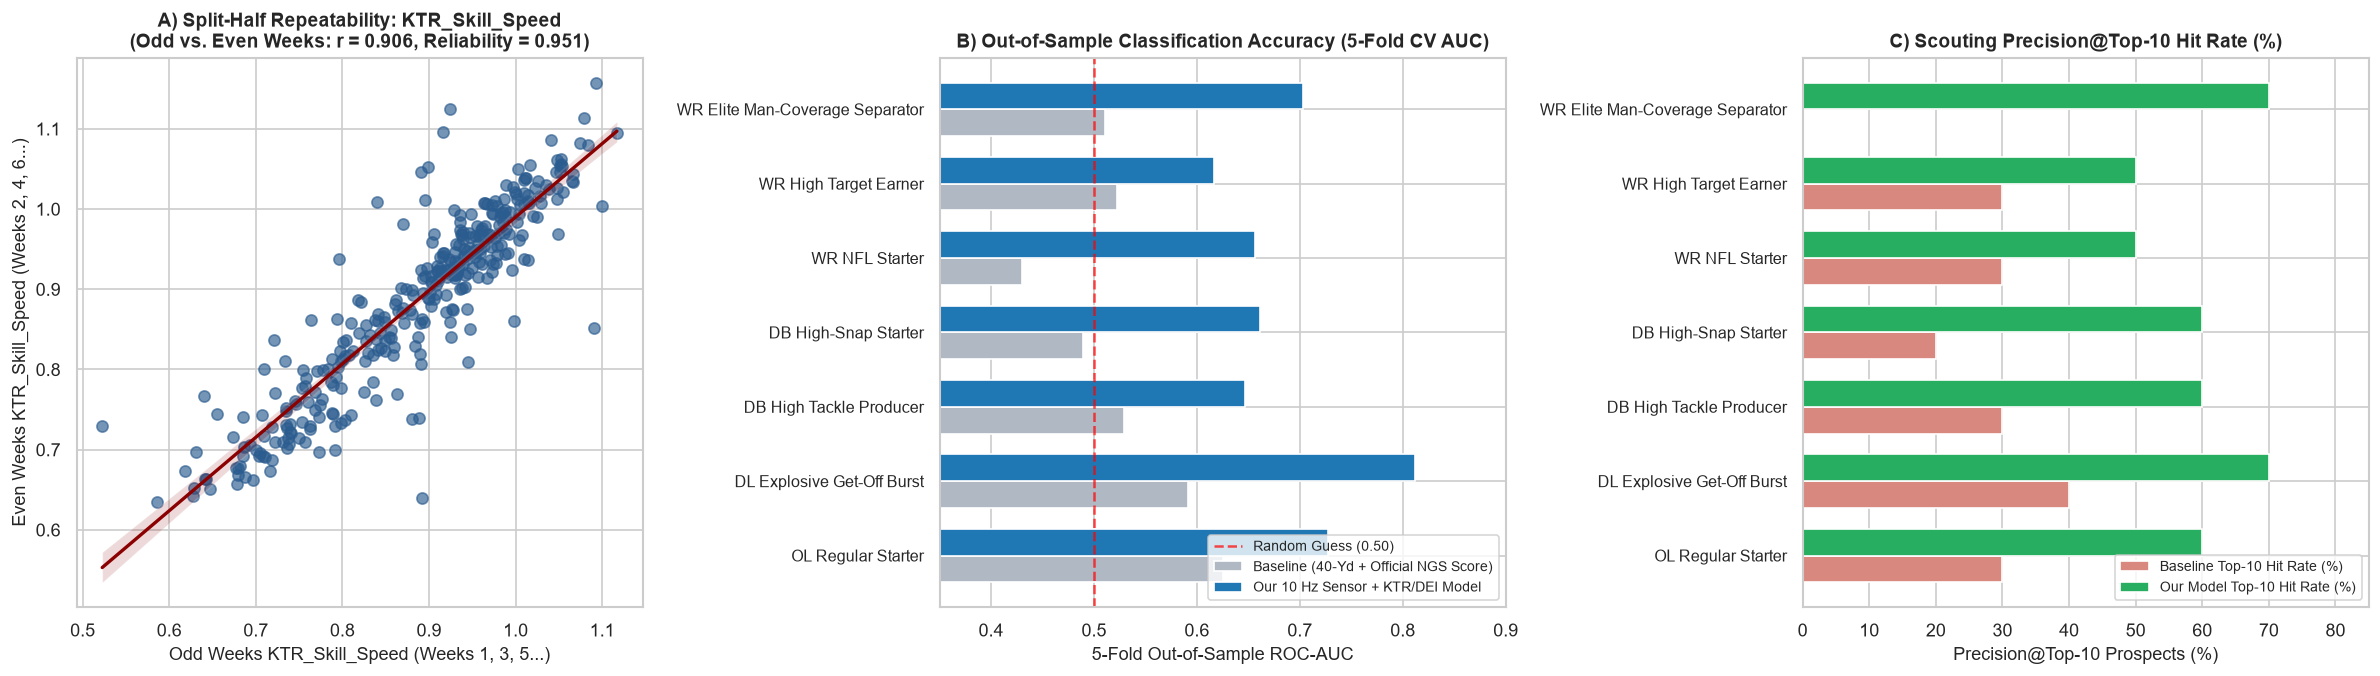

In [7]:
# ==============================================================================
# MODÜL 6: DOĞRULAMA (VALIDATION), KARARLILIK (SPLIT-HALF RELIABILITY),
#          MAN vs. ZONE KONTROLÜ VE OUT-OF-SAMPLE BENCHMARK LABORATUVARI
# ==============================================================================
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_predict
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, accuracy_score, roc_curve

print('=== 1. SPLIT-HALF STABILITY (TEK HAFTALAR vs. ÇİFT HAFTALAR TUTARLILIK TESTİ) ===')
odd_plays = nfl_reg_plays_df[nfl_reg_plays_df['week'] % 2 == 1]
even_plays = nfl_reg_plays_df[nfl_reg_plays_df['week'] % 2 == 0]

def compute_half_season_metrics(df_half, suffix):
    g = df_half.groupby('nfl_id').agg(
        n_plays=('play_id', 'count'),
        v95=('play_max_speed', lambda x: np.nanpercentile(x, 95)),
        a95=('play_max_accel', lambda x: np.nanpercentile(x, 95)),
        v95_high_d=('max_speed_high_dissoc', lambda x: np.nanpercentile(x.dropna(), 95) if len(x.dropna()) >= 3 else np.nan),
        v95_low_d=('max_speed_low_dissoc', lambda x: np.nanpercentile(x.dropna(), 95) if len(x.dropna()) >= 3 else np.nan),
    ).reset_index()
    g = g[g['n_plays'] >= 12].copy()
    g[f'dei_{suffix}'] = g['v95_high_d'] / g['v95_low_d']
    return g[['nfl_id', 'v95', 'a95', f'dei_{suffix}']].rename(columns={'v95': f'v95_{suffix}', 'a95': f'a95_{suffix}'})

odd_m = compute_half_season_metrics(odd_plays, 'odd')
even_m = compute_half_season_metrics(even_plays, 'even')
split_df = reg_active[['nfl_id', 'combine_position', 'forty_vmax', 's2_v95', 's2_a95']].merge(odd_m, on='nfl_id').merge(even_m, on='nfl_id')

split_df['KTR_Track_odd'] = split_df['v95_odd'] / split_df['forty_vmax']
split_df['KTR_Track_even'] = split_df['v95_even'] / split_df['forty_vmax']
split_df['KTR_Skill_odd'] = split_df['v95_odd'] / split_df['s2_v95']
split_df['KTR_Skill_even'] = split_df['v95_even'] / split_df['s2_v95']
split_df['KTR_Accel_odd'] = split_df['a95_odd'] / split_df['s2_a95']
split_df['KTR_Accel_even'] = split_df['a95_even'] / split_df['s2_a95']

stab_rows = []
for metric_name, c_odd, c_even in [
    ('KTR_Track_Speed (40-Yd -> NFL)', 'KTR_Track_odd', 'KTR_Track_even'),
    ('KTR_Skill_Speed (Skill Drill -> NFL)', 'KTR_Skill_odd', 'KTR_Skill_even'),
    ('KTR_Skill_Accel (Skill Accel -> NFL)', 'KTR_Accel_odd', 'KTR_Accel_even'),
    ('Torso_Dissoc_Efficiency (DEI)', 'dei_odd', 'dei_even'),
    ('In-Game 95th Pct Speed (nfl_v95)', 'v95_odd', 'v95_even'),
]:
    v = split_df[[c_odd, c_even]].dropna()
    r, p = stats.pearsonr(v[c_odd], v[c_even])
    r_sb = (2.0 * r) / (1.0 + r)
    stab_rows.append({
        'Metric': metric_name,
        'N_Players': len(v),
        'Odd_vs_Even_Week_r': round(r, 3),
        'Spearman_Brown_Reliability': round(r_sb, 3),
        'p_value': f'{p:.2e}'
    })
stab_summary_df = pd.DataFrame(stab_rows)
display(stab_summary_df)

print('\n=== 2. MAN COVERAGE vs. ZONE COVERAGE BAĞLAMSAL KONTROLÜ (WR SEPARATION) ===')
wr_cov_rows = []
wr_sep_plays = nfl_reg_plays_df[(nfl_reg_plays_df['combine_position'] == 'WR') & nfl_reg_plays_df['separation'].notna()]
for cov_type in ['MAN_COVERAGE', 'ZONE_COVERAGE']:
    sub_cov = wr_sep_plays[wr_sep_plays['team_coverage_man_zone'] == cov_type]
    cov_agg = sub_cov.groupby('nfl_id').agg(
        n_routes=('play_id', 'count'),
        avg_sep=('separation', 'mean'),
        p90_sep=('separation', lambda x: np.nanpercentile(x, 90)),
    ).reset_index()
    cov_agg = cov_agg[cov_agg['n_routes'] >= 8].merge(
        reg_active[['nfl_id', 'forty', 'ngs_athleticism_score', 'Torso_Dissoc_Efficiency']], on='nfl_id'
    )
    for pred_col in ['forty', 'ngs_athleticism_score', 'Torso_Dissoc_Efficiency']:
        v = cov_agg[[pred_col, 'p90_sep', 'avg_sep']].dropna()
        r90, p90 = stats.pearsonr(v[pred_col], v['p90_sep'])
        ravg, pavg = stats.pearsonr(v[pred_col], v['avg_sep'])
        wr_cov_rows.append({
            'Coverage_Type': cov_type,
            'Predictor': pred_col,
            'N_WRs': len(v),
            'r_P90_Separation': round(r90, 3),
            'p_val_P90': round(p90, 4),
            'r_Avg_Separation': round(ravg, 3),
            'p_val_Avg': round(pavg, 4),
        })
display(pd.DataFrame(wr_cov_rows))

man_wr_df = wr_sep_plays[wr_sep_plays['team_coverage_man_zone'] == 'MAN_COVERAGE'].groupby('nfl_id').agg(
    n_man=('play_id', 'count'),
    man_p90_sep=('separation', lambda x: np.nanpercentile(x, 90))
).reset_index()
reg_active_val = reg_active.merge(man_wr_df[man_wr_df['n_man'] >= 8][['nfl_id', 'man_p90_sep']], on='nfl_id', how='left')

print('\n=== 3. 5-FOLD CROSS-VALIDATION BENCHMARK: 40-YD + NGS SKORU vs. BİZİM SENSÖR/KTR MODELİMİZ ===')
benchmark_tasks = [
    ('WR Elite Man-Coverage Separator (Top-35%)', ['WR'], 'man_p90_sep', ['forty', 'ngs_athleticism_score'], ['Torso_Dissoc_Efficiency', 'KTR_Skill_Speed'], 'high'),
    ('WR High Target Earner (Top-35% Target Rate)', ['WR'], 'target_rate', ['forty', 'ngs_athleticism_score'], ['s2_centripetal95', 's2_power95', 'Torso_Dissoc_Efficiency'], 'high'),
    ('WR NFL Starter (Top-35% Starter Ratio)', ['WR'], 'starter_ratio', ['forty', 'ngs_athleticism_score'], ['s2_power95', 's2_centripetal95', 'Torso_Dissoc_Efficiency'], 'high'),
    ('DB High-Snap Starter (Top-35% Career Snaps)', ['DB'], 'total_career_snaps', ['forty', 'ngs_athleticism_score'], ['forty_amax', 's2_centripetal95', 'KTR_Skill_Accel'], 'high'),
    ('DB High Tackle Producer (Top-35% Tackles)', ['DB'], 'total_tackles', ['forty', 'ngs_athleticism_score'], ['forty_amax', 'KTR_Skill_Accel'], 'high'),
    ('DL Explosive Get-Off Burst (Fastest 35%)', ['DL'], 'avg_get_off', ['ngs_athleticism_score'], ['s2_power95', 's2_v95', 'KTR_Skill_Accel'], 'low'),
    ('OL Regular Starter (Top-35% Starter Ratio)', ['OL'], 'starter_ratio', ['forty', 'ngs_athleticism_score'], ['Torso_Dissoc_Efficiency', 's2_a95'], 'high'),
]

cv_results = []
for task_name, pos_list, targ_col, base_cols, sens_cols, direction in benchmark_tasks:
    sub = reg_active_val[reg_active_val['combine_position'].isin(pos_list) & reg_active_val[targ_col].notna()].copy()
    thresh = np.nanpercentile(sub[targ_col], 65 if direction == 'high' else 35)
    y = (sub[targ_col] >= thresh).astype(int).values if direction == 'high' else (sub[targ_col] <= thresh).astype(int).values

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    m_base = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(C=0.5, random_state=42))
    m_sens = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(C=0.5, random_state=42))

    p_base = cross_val_predict(m_base, sub[base_cols], y, cv=skf, method='predict_proba')[:, 1]
    p_sens = cross_val_predict(m_sens, sub[sens_cols], y, cv=skf, method='predict_proba')[:, 1]

    auc_b = roc_auc_score(y, p_base)
    auc_s = roc_auc_score(y, p_sens)
    top10_b = y[np.argsort(p_base)[::-1][:10]].mean() * 100.0
    top10_s = y[np.argsort(p_sens)[::-1][:10]].mean() * 100.0

    cv_results.append({
        'Evaluation_Task': task_name,
        'N': len(sub),
        'Baseline_AUC': round(auc_b, 3),
        'Our_Sensor_AUC': round(auc_s, 3),
        'AUC_Gain': round(auc_s - auc_b, 3),
        'Base_Top10_Hit_%': round(top10_b, 0),
        'Our_Top10_Hit_%': round(top10_s, 0),
    })

cv_bench_df = pd.DataFrame(cv_results)
display(cv_bench_df)

fig, axes = plt.subplots(1, 3, figsize=(20, 5.8))

sns.regplot(
    data=split_df,
    x='KTR_Skill_odd',
    y='KTR_Skill_even',
    scatter_kws={'alpha': 0.65, 's': 45, 'color': '#2b5c8f'},
    line_kws={'color': 'darkred', 'linewidth': 2},
    ax=axes[0]
)
r_split = stab_summary_df.loc[stab_summary_df['Metric'].str.startswith('KTR_Skill_Speed'), 'Odd_vs_Even_Week_r'].values[0]
rsb_split = stab_summary_df.loc[stab_summary_df['Metric'].str.startswith('KTR_Skill_Speed'), 'Spearman_Brown_Reliability'].values[0]
axes[0].set_title(f'A) Split-Half Repeatability: KTR_Skill_Speed\n(Odd vs. Even Weeks: r = {r_split:.3f}, Reliability = {rsb_split:.3f})', fontsize=11.5, fontweight='bold')
axes[0].set_xlabel('Odd Weeks KTR_Skill_Speed (Weeks 1, 3, 5...)', fontsize=10.5)
axes[0].set_ylabel('Even Weeks KTR_Skill_Speed (Weeks 2, 4, 6...)', fontsize=10.5)

y_pos = np.arange(len(cv_bench_df))
height = 0.36
axes[1].barh(y_pos + height/2, cv_bench_df['Baseline_AUC'], height, label='Baseline (40-Yd + Official NGS Score)', color='#b0b8c4')
axes[1].barh(y_pos - height/2, cv_bench_df['Our_Sensor_AUC'], height, label='Our 10 Hz Sensor + KTR/DEI Model', color='#1f77b4')
axes[1].axvline(0.50, color='red', linestyle='--', alpha=0.7, label='Random Guess (0.50)')
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels([t.split(' (')[0] for t in cv_bench_df['Evaluation_Task']], fontsize=9.5)
axes[1].invert_yaxis()
axes[1].set_xlim(0.35, 0.90)
axes[1].set_xlabel('5-Fold Out-of-Sample ROC-AUC', fontsize=10.5)
axes[1].set_title('B) Out-of-Sample Classification Accuracy (5-Fold CV AUC)', fontsize=11.5, fontweight='bold')
axes[1].legend(loc='lower right', fontsize=8.5, frameon=True)

axes[2].barh(y_pos + height/2, cv_bench_df['Base_Top10_Hit_%'], height, label='Baseline Top-10 Hit Rate (%)', color='#d98880')
axes[2].barh(y_pos - height/2, cv_bench_df['Our_Top10_Hit_%'], height, label='Our Model Top-10 Hit Rate (%)', color='#27ae60')
axes[2].set_yticks(y_pos)
axes[2].set_yticklabels([t.split(' (')[0] for t in cv_bench_df['Evaluation_Task']], fontsize=9.5)
axes[2].invert_yaxis()
axes[2].set_xlim(0, 85)
axes[2].set_xlabel('Precision@Top-10 Prospects (%)', fontsize=10.5)
axes[2].set_title('C) Scouting Precision@Top-10 Hit Rate (%)', fontsize=11.5, fontweight='bold')
axes[2].legend(loc='lower right', fontsize=8.5, frameon=True)

plt.tight_layout()
plt.savefig(CACHE_DIR / 'figures' / 'validation_benchmark_suite.png', dpi=150)
plt.show()

=== 1. SAF COMBINE WR MİKRO-ÖZELLİKLERİ -> NFL HEDEFLERİ TEKİL KORELASYONLAR ===


,Pre_Draft_Combine_Micro_Feature,Future_NFL_Target,N_WRs,Pearson_r,p_value
0,"hb_cut_speed (Keskin Dönüş Hızı, omega>=60°/s)",WR İlk 11 Olma Oranı,76,0.330,0.0036
1,hb_cut_speed_retention (Dönüş Hız Koruma Oranı),WR İlk 11 Olma Oranı,76,0.310,0.0065
2,s2_centripetal95 (Combine Merkezcil Dönüş Gücü...,WR Pas Hedeflenme Oranı,76,0.322,0.0046
3,hb_centripetal95 (Hard-Break Merkezcil Dönüş G...,WR Pas Hedeflenme Oranı,76,0.268,0.0193
4,gaunt_vmean (Gauntlet Drill Ortalama Akış Hızı),WR Ortalama YAC (Yards After Catch),75,0.260,0.0244
5,forty_vmax (40-Yard Sensör Tepe Hızı),NFL Gövde Ayrışma Verimliliği (DEI),68,0.407,0.0006
6,deep_v95 (Derin Rota / Over-Shoulder Hızı),NFL Gövde Ayrışma Verimliliği (DEI),76,0.268,0.0193
7,f40_early_to_peak_ratio (40-Yd İkinci Vites Re...,NFL Man Coverage P90 Separation,66,-0.332,0.0065
8,comb_hb_to_40_speed (Combine Rota / 40-Yd Hız ...,NFL KTR_Skill_Speed Aktarımı,68,-0.677,0.0000



=== 2. ÇOK DEĞİŞKENLİ PRE-DRAFT WR MODELİ (5-FOLD OUT-OF-SAMPLE CV): KRONOMETRE+NGS vs. COMBINE MİKRO-MODEL ===


,Predicted_NFL_Outcome,N_WRs,Base_CV_r (40yd+NGS),Base_CV_R2_%,PreDraft_Micro_CV_r,PreDraft_Micro_CV_R2_%,Micro_p_val
0,Future NFL KTR_Skill_Speed,76,0.128,1.7,0.675,45.5,0.0000
1,Future NFL In-Game Speed (nfl_v95),76,0.445,19.8,0.558,31.1,0.0000
2,Future NFL Torso_Dissoc_Efficiency (DEI),76,0.276,7.6,0.385,14.8,0.0006
3,Future NFL Starter Ratio,76,-0.127,0.0,0.410,16.8,0.0002
4,Future NFL Man-Coverage P90 Separation,72,-0.031,0.0,0.365,13.3,0.0016


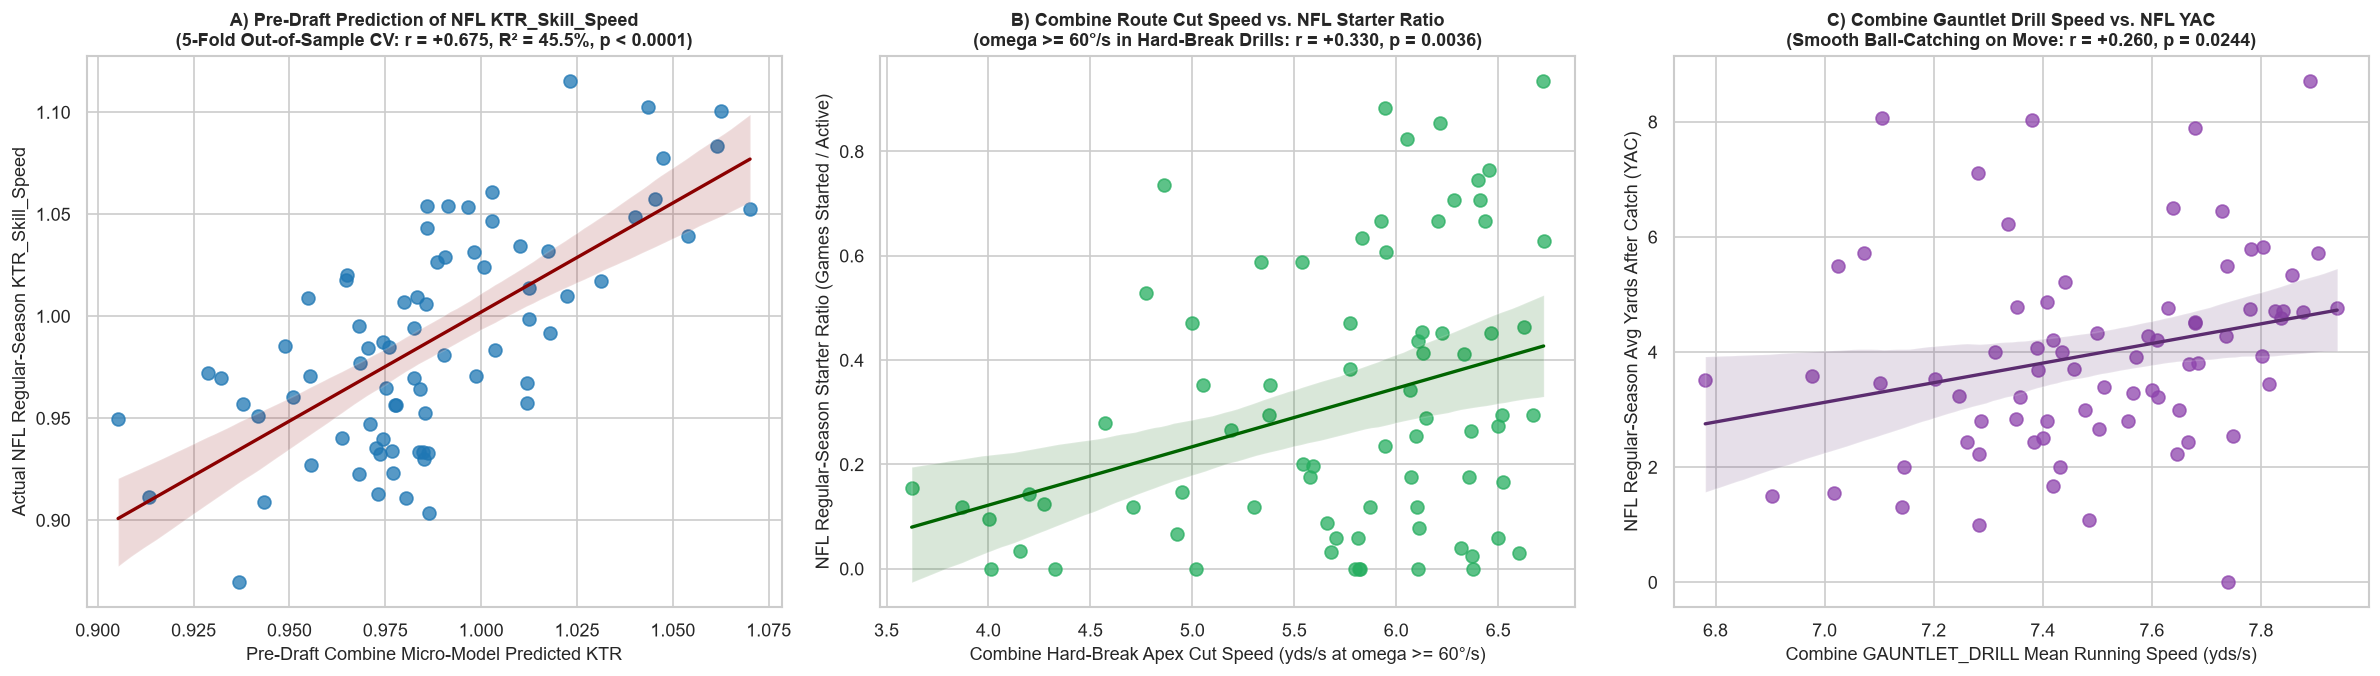

In [8]:
# ==============================================================================
# MODÜL 7 (ADIM 1): WR PRE-DRAFT MİKRO-ÖZELLİK TAHMİN MODELİ
# (Sadece Combine WR Drillerinden Gelecekteki NFL KTR, DEI ve Başarı Tahmini)
# ==============================================================================
comb_wr = pd.read_parquet(CACHE_DIR / 'by_position' / 'combine_tracking_WR.parquet')
wr_reg_master = reg_active_val[reg_active_val['combine_position'] == 'WR'].copy()

HARD_BREAK_ROUTES = {
    'CURL_ROUTE_RIGHT', 'COMEBACK_ROUTE_RIGHT', 'DAGGER_ROUTE_LEFT',
    'SPEED_OUT_ROUTE_LEFT', 'POST_CORNER_ROUTE_RIGHT', 'POST_CORNER_ROUTE_LEFT',
    'SLANT_ROUTE_LEFT', 'SLOT_STRIKE_ROUTE_LEFT'
}
DEEP_TRACKING_ROUTES = {
    'GO_ROUTE_RIGHT', 'SLOT_SAIL_ROUTE_RIGHT', 'RED_ZONE_FADE_RIGHT',
    'OVER_SHOULDER_ADJUST', 'CIRCUS_ROUTE_LEFT'
}

gaunt_run = comb_wr[(comb_wr['drill_name'] == 'GAUNTLET_DRILL') & (comb_wr['s'] >= 3.0)]
gaunt_feats = gaunt_run.groupby('nfl_id').agg(
    gaunt_vmax=('s', 'max'),
    gaunt_vmean=('s', 'mean'),
    gaunt_a90=('a', lambda x: np.nanpercentile(x, 90)),
    gaunt_centripetal90=('centripetal_accel', lambda x: np.nanpercentile(x.dropna(), 90) if len(x.dropna()) else np.nan),
).reset_index()

hb_run = comb_wr[comb_wr['drill_name'].isin(HARD_BREAK_ROUTES) & (comb_wr['s'] >= 2.0)]
hb_feats = hb_run.groupby('nfl_id').agg(
    hb_v95=('s', lambda x: np.nanpercentile(x, 95)),
    hb_a95=('a', lambda x: np.nanpercentile(x, 95)),
    hb_brake_p5=('signed_accel', lambda x: np.nanpercentile(x.dropna(), 5) if len(x.dropna()) else np.nan),
    hb_centripetal95=('centripetal_accel', lambda x: np.nanpercentile(x.dropna(), 95) if len(x.dropna()) else np.nan),
    hb_power95=('mechanical_power_proxy', lambda x: np.nanpercentile(x.dropna(), 95) if len(x.dropna()) else np.nan),
    hb_cut_speed=('s', lambda x: np.nanpercentile(x[hb_run.loc[x.index, 'omega_deg_s'] >= 60.0], 85) if (hb_run.loc[x.index, 'omega_deg_s'] >= 60.0).any() else np.nan),
).reset_index()
hb_feats['hb_cut_speed_retention'] = hb_feats['hb_cut_speed'] / hb_feats['hb_v95']

deep_run = comb_wr[comb_wr['drill_name'].isin(DEEP_TRACKING_ROUTES) & (comb_wr['s'] >= 2.5)]
deep_feats = deep_run.groupby('nfl_id').agg(
    deep_v95=('s', lambda x: np.nanpercentile(x, 95)),
    deep_a95=('a', lambda x: np.nanpercentile(x, 95)),
    deep_centripetal95=('centripetal_accel', lambda x: np.nanpercentile(x.dropna(), 95) if len(x.dropna()) else np.nan),
).reset_index()

f40_run = comb_wr[(comb_wr['drill_type'] == 'FORTY_YARD_DASH') & (comb_wr['s'] >= 1.0)].copy()
f40_run['frame_idx'] = f40_run.groupby(['nfl_id', 'event_id', 'attempt']).cumcount()
f40_feats = f40_run.groupby('nfl_id').agg(
    f40_early_v15=('s', lambda x: x[f40_run.loc[x.index, 'frame_idx'] <= 15].max() if (f40_run.loc[x.index, 'frame_idx'] <= 15).any() else np.nan),
    f40_late_vmax=('s', 'max'),
).reset_index()
f40_feats['f40_early_to_peak_ratio'] = f40_feats['f40_early_v15'] / f40_feats['f40_late_vmax']

wr_micro_df = (
    wr_reg_master
    .merge(gaunt_feats, on='nfl_id', how='left')
    .merge(hb_feats, on='nfl_id', how='left')
    .merge(deep_feats, on='nfl_id', how='left')
    .merge(f40_feats, on='nfl_id', how='left')
)
wr_micro_df['comb_hb_to_40_speed'] = wr_micro_df['hb_v95'] / wr_micro_df['forty_vmax']
wr_micro_df['comb_deep_to_40_speed'] = wr_micro_df['deep_v95'] / wr_micro_df['forty_vmax']
wr_micro_df.to_parquet(CACHE_DIR / 'wr_predraft_micro_master.parquet', index=False)

print('=== 1. SAF COMBINE WR MİKRO-ÖZELLİKLERİ -> NFL HEDEFLERİ TEKİL KORELASYONLAR ===')
single_signals = [
    ('hb_cut_speed (Keskin Dönüş Hızı, omega>=60°/s)', 'starter_ratio', 'WR İlk 11 Olma Oranı'),
    ('hb_cut_speed_retention (Dönüş Hız Koruma Oranı)', 'starter_ratio', 'WR İlk 11 Olma Oranı'),
    ('s2_centripetal95 (Combine Merkezcil Dönüş Gücü v*omega)', 'target_rate', 'WR Pas Hedeflenme Oranı'),
    ('hb_centripetal95 (Hard-Break Merkezcil Dönüş Gücü)', 'target_rate', 'WR Pas Hedeflenme Oranı'),
    ('gaunt_vmean (Gauntlet Drill Ortalama Akış Hızı)', 'avg_yac', 'WR Ortalama YAC (Yards After Catch)'),
    ('forty_vmax (40-Yard Sensör Tepe Hızı)', 'Torso_Dissoc_Efficiency', 'NFL Gövde Ayrışma Verimliliği (DEI)'),
    ('deep_v95 (Derin Rota / Over-Shoulder Hızı)', 'Torso_Dissoc_Efficiency', 'NFL Gövde Ayrışma Verimliliği (DEI)'),
    ('f40_early_to_peak_ratio (40-Yd İkinci Vites Rezervi)', 'man_p90_sep', 'NFL Man Coverage P90 Separation'),
    ('comb_hb_to_40_speed (Combine Rota / 40-Yd Hız Oranı)', 'KTR_Skill_Speed', 'NFL KTR_Skill_Speed Aktarımı'),
]
sig_table = []
for col_label, targ_col, targ_desc in single_signals:
    col_name = col_label.split(' ')[0]
    v = wr_micro_df[[col_name, targ_col]].dropna()
    r, p = stats.pearsonr(v[col_name], v[targ_col])
    sig_table.append({
        'Pre_Draft_Combine_Micro_Feature': col_label,
        'Future_NFL_Target': targ_desc,
        'N_WRs': len(v),
        'Pearson_r': round(r, 3),
        'p_value': round(p, 4)
    })
display(pd.DataFrame(sig_table))

print('\n=== 2. ÇOK DEĞİŞKENLİ PRE-DRAFT WR MODELİ (5-FOLD OUT-OF-SAMPLE CV): KRONOMETRE+NGS vs. COMBINE MİKRO-MODEL ===')
predraft_models = [
    ('Future NFL KTR_Skill_Speed', 'KTR_Skill_Speed', ['forty_vmax', 'hb_v95', 'deep_v95', 'comb_hb_to_40_speed', 'comb_deep_to_40_speed']),
    ('Future NFL In-Game Speed (nfl_v95)', 'nfl_v95', ['forty_vmax', 'hb_cut_speed', 'deep_v95', 'comb_hb_to_40_speed']),
    ('Future NFL Torso_Dissoc_Efficiency (DEI)', 'Torso_Dissoc_Efficiency', ['forty_vmax', 'deep_v95', 'f40_early_to_peak_ratio', 'hb_cut_speed_retention']),
    ('Future NFL Starter Ratio', 'starter_ratio', ['hb_cut_speed', 'hb_cut_speed_retention', 's2_power95', 's2_centripetal95', 'f40_early_v15']),
    ('Future NFL Man-Coverage P90 Separation', 'man_p90_sep', ['f40_early_to_peak_ratio', 'forty_vmax', 'deep_v95']),
]
pm_rows = []
cv_preds_store = {}
for label, targ, feats in predraft_models:
    sub = wr_micro_df[['nfl_id', 'display_name', 'forty', 'ngs_athleticism_score', targ] + feats].dropna(subset=[targ]).copy()
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    m_base = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), Ridge(alpha=10.0))
    m_micro = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), Ridge(alpha=10.0))

    pb = cross_val_predict(m_base, sub[['forty', 'ngs_athleticism_score']], sub[targ], cv=kf)
    pm = cross_val_predict(m_micro, sub[feats], sub[targ], cv=kf)
    cv_preds_store[targ] = (sub, pb, pm)

    rb, p_b = stats.pearsonr(sub[targ], pb)
    rm, p_m = stats.pearsonr(sub[targ], pm)
    pm_rows.append({
        'Predicted_NFL_Outcome': label,
        'N_WRs': len(sub),
        'Base_CV_r (40yd+NGS)': round(rb, 3),
        'Base_CV_R2_%': round((rb**2)*100 if rb > 0 else 0.0, 1),
        'PreDraft_Micro_CV_r': round(rm, 3),
        'PreDraft_Micro_CV_R2_%': round((rm**2)*100, 1),
        'Micro_p_val': round(p_m, 4),
    })
pm_df = pd.DataFrame(pm_rows)
display(pm_df)

fig, axes = plt.subplots(1, 3, figsize=(20, 5.8))

sub_ktr, _, pm_ktr = cv_preds_store['KTR_Skill_Speed']
sns.regplot(x=pm_ktr, y=sub_ktr['KTR_Skill_Speed'], scatter_kws={'alpha': 0.75, 's': 60, 'color': '#1f77b4'}, line_kws={'color': 'darkred', 'linewidth': 2}, ax=axes[0])
r_k, p_k = stats.pearsonr(pm_ktr, sub_ktr['KTR_Skill_Speed'])
axes[0].set_title(f'A) Pre-Draft Prediction of NFL KTR_Skill_Speed\n(5-Fold Out-of-Sample CV: r = +{r_k:.3f}, R² = {r_k**2*100:.1f}%, p < 0.0001)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Pre-Draft Combine Micro-Model Predicted KTR', fontsize=10.5)
axes[0].set_ylabel('Actual NFL Regular-Season KTR_Skill_Speed', fontsize=10.5)

sns.regplot(data=wr_micro_df, x='hb_cut_speed', y='starter_ratio', scatter_kws={'alpha': 0.75, 's': 60, 'color': '#27ae60'}, line_kws={'color': 'darkgreen', 'linewidth': 2}, ax=axes[1])
r_st, p_st = stats.pearsonr(wr_micro_df[['hb_cut_speed', 'starter_ratio']].dropna()['hb_cut_speed'], wr_micro_df[['hb_cut_speed', 'starter_ratio']].dropna()['starter_ratio'])
axes[1].set_title(f'B) Combine Route Cut Speed vs. NFL Starter Ratio\n(omega >= 60°/s in Hard-Break Drills: r = +{r_st:.3f}, p = {p_st:.4f})', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Combine Hard-Break Apex Cut Speed (yds/s at omega >= 60°/s)', fontsize=10.5)
axes[1].set_ylabel('NFL Regular-Season Starter Ratio (Games Started / Active)', fontsize=10.5)

v_yac = wr_micro_df[['display_name', 'gaunt_vmean', 'avg_yac']].dropna()
sns.regplot(data=v_yac, x='gaunt_vmean', y='avg_yac', scatter_kws={'alpha': 0.75, 's': 60, 'color': '#8e44ad'}, line_kws={'color': '#5b2c6f', 'linewidth': 2}, ax=axes[2])
r_yc, p_yc = stats.pearsonr(v_yac['gaunt_vmean'], v_yac['avg_yac'])
axes[2].set_title(f'C) Combine Gauntlet Drill Speed vs. NFL YAC\n(Smooth Ball-Catching on Move: r = +{r_yc:.3f}, p = {p_yc:.4f})', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Combine GAUNTLET_DRILL Mean Running Speed (yds/s)', fontsize=10.5)
axes[2].set_ylabel('NFL Regular-Season Avg Yards After Catch (YAC)', fontsize=10.5)

plt.tight_layout()
plt.savefig(CACHE_DIR / 'figures' / 'wr_predraft_micro_model.png', dpi=150)
plt.show()

=== VAKA ANALİZİ (CASE STUDY): MARVIN MIMS (4.38s) vs. XAVIER LEGETTE (4.39s) ===


,display_name,draft_year,draft_round,forty,forty_vmax,gaunt_vmax,gaunt_vmean,nfl_v95,KTR_Track_Speed,KTR_Skill_Speed,Torso_Dissoc_Efficiency,p90_separation,man_p90_sep,total_career_snaps
6,Marvin Mims,2023,2.0,4.38,11.150000,9.313333,7.889505,9.616,0.862422,1.009342,0.970808,7.725683,5.835545,1059
34,Xavier Legette,2024,1.0,4.39,11.456667,8.890000,7.646535,8.880,0.775095,0.933165,0.972350,5.591698,4.042496,1321


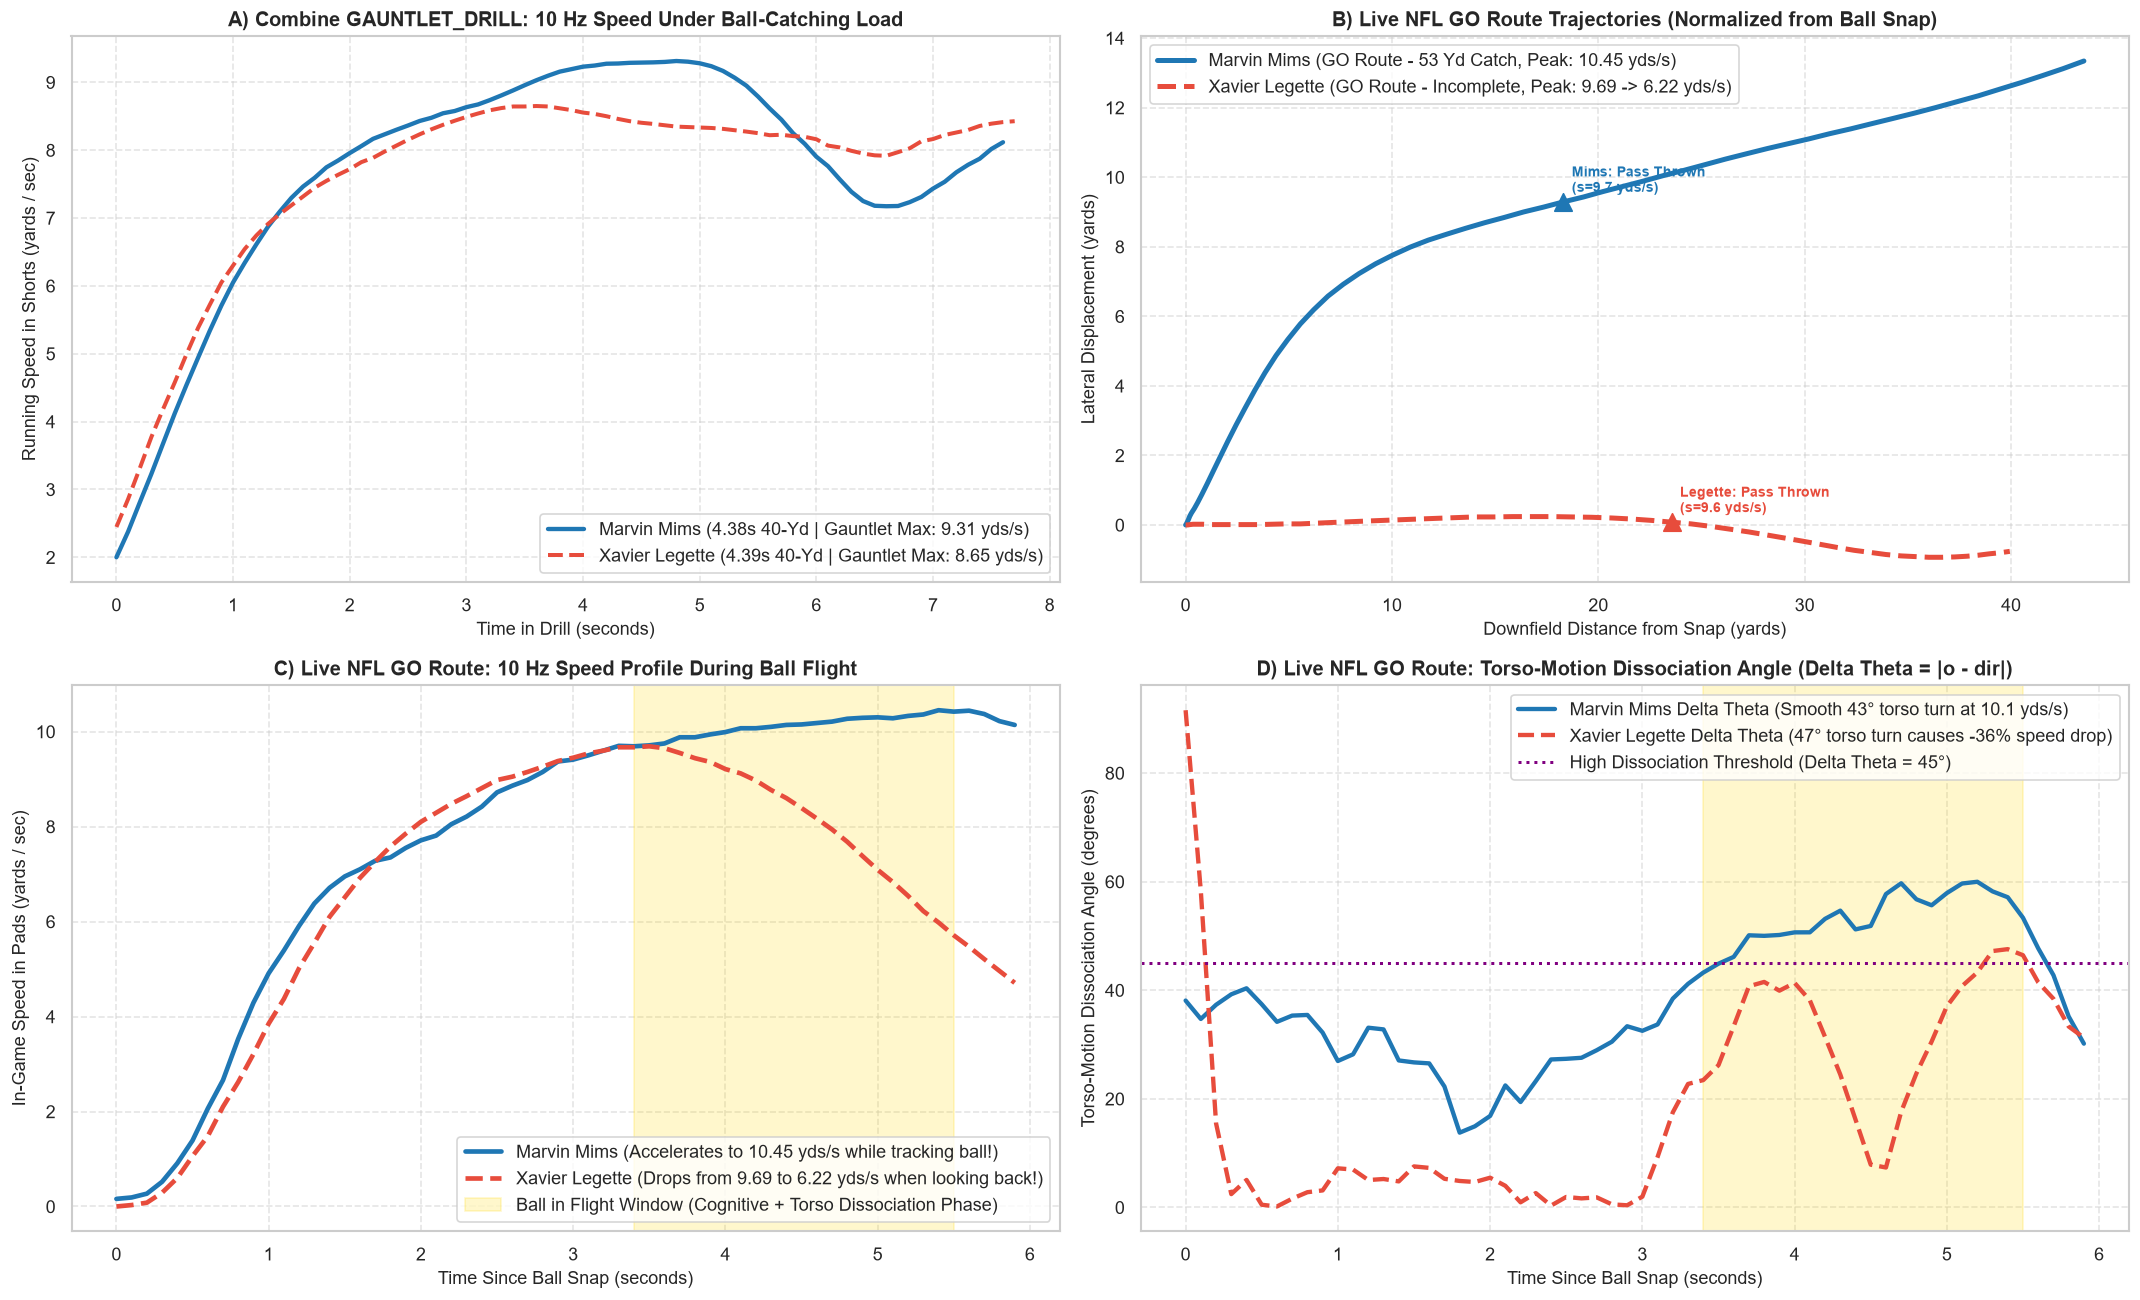

In [9]:
# ==============================================================================
# MODÜL 8 (ADIM 2): 10 Hz FRAME-BY-FRAME VAKA ANALİZİ (CASE STUDY)
# MARVIN MIMS (4.38s - True Gamer) vs. XAVIER LEGETTE (4.39s - Workout Warrior)
# ==============================================================================
case_nfl_path = CACHE_DIR / 'case_study_nfl_frames.parquet'
if not case_nfl_path.exists():
    case_query = f"""
        SELECT
            TRY_CAST(game_id AS BIGINT) AS game_id,
            TRY_CAST(play_id AS INTEGER) AS play_id,
            TRY_CAST(nfl_id AS INTEGER) AS nfl_id,
            time,
            TRY_CAST(x AS DOUBLE) AS x,
            TRY_CAST(y AS DOUBLE) AS y,
            TRY_CAST(s AS DOUBLE) AS s,
            TRY_CAST(a AS DOUBLE) AS a,
            TRY_CAST(o AS DOUBLE) AS o,
            TRY_CAST(dir AS DOUBLE) AS dir,
            event,
            LEAST(ABS(TRY_CAST(o AS DOUBLE) - TRY_CAST(dir AS DOUBLE)), 360.0 - ABS(TRY_CAST(o AS DOUBLE) - TRY_CAST(dir AS DOUBLE))) AS delta_theta
        FROM read_csv_auto('{DATA_DIR.as_posix()}/game_tracking_*.csv', union_by_name=true)
        WHERE TRY_CAST(nfl_id AS INTEGER) IN (55928, 57153)
          AND (
              (TRY_CAST(game_id AS BIGINT) = 2023091711 AND TRY_CAST(play_id AS INTEGER) = 1082)
              OR (TRY_CAST(game_id AS BIGINT) = 2025010501 AND TRY_CAST(play_id AS INTEGER) = 2993)
          )
        ORDER BY game_id, play_id, time
    """
    con.execute(f"COPY ({case_query}) TO '{case_nfl_path.as_posix()}' (FORMAT PARQUET)")

case_nfl_df = pd.read_parquet(case_nfl_path)

pair_summary = wr_micro_df[wr_micro_df['nfl_id'].isin([55928, 57153])][[
    'display_name', 'draft_year', 'draft_round', 'forty', 'forty_vmax',
    'gaunt_vmax', 'gaunt_vmean', 'nfl_v95', 'KTR_Track_Speed', 'KTR_Skill_Speed',
    'Torso_Dissoc_Efficiency', 'p90_separation', 'man_p90_sep', 'total_career_snaps'
]].sort_values('KTR_Track_Speed', ascending=False)

print('=== VAKA ANALİZİ (CASE STUDY): MARVIN MIMS (4.38s) vs. XAVIER LEGETTE (4.39s) ===')
display(pair_summary)

mims_gaunt = comb_wr[(comb_wr['nfl_id'] == 55928) & (comb_wr['drill_name'] == 'GAUNTLET_DRILL') & (comb_wr['attempt'] == 2) & (comb_wr['s'] >= 2.0)].copy()
leg_gaunt = comb_wr[(comb_wr['nfl_id'] == 57153) & (comb_wr['drill_name'] == 'GAUNTLET_DRILL') & (comb_wr['attempt'] == 1) & (comb_wr['s'] >= 2.0)].copy()
mims_gaunt['t_sec'] = np.arange(len(mims_gaunt)) * 0.1
leg_gaunt['t_sec'] = np.arange(len(leg_gaunt)) * 0.1

def align_from_snap(df_play):
    snap_rows = df_play[df_play['event'] == 'ball_snap']
    if len(snap_rows) > 0:
        t_snap = snap_rows.index[0]
        sub = df_play.loc[t_snap:].copy().reset_index(drop=True)
    else:
        sub = df_play.copy().reset_index(drop=True)
    sub['t_sec'] = np.arange(len(sub)) * 0.1
    sub['rel_x'] = (sub['x'] - sub['x'].iloc[0]).abs()
    sub['rel_y'] = sub['y'] - sub['y'].iloc[0]
    return sub.iloc[:60]

mims_nfl = align_from_snap(case_nfl_df[(case_nfl_df['nfl_id'] == 55928) & (case_nfl_df['play_id'] == 1082)])
leg_nfl = align_from_snap(case_nfl_df[(case_nfl_df['nfl_id'] == 57153) & (case_nfl_df['play_id'] == 2993)])

fig, axes = plt.subplots(2, 2, figsize=(18, 11))

axes[0, 0].plot(mims_gaunt['t_sec'], mims_gaunt['s'], color='#1f77b4', linewidth=2.6, label='Marvin Mims (4.38s 40-Yd | Gauntlet Max: 9.31 yds/s)')
axes[0, 0].plot(leg_gaunt['t_sec'], leg_gaunt['s'], color='#e74c3c', linewidth=2.4, linestyle='--', label='Xavier Legette (4.39s 40-Yd | Gauntlet Max: 8.65 yds/s)')
axes[0, 0].set_title('A) Combine GAUNTLET_DRILL: 10 Hz Speed Under Ball-Catching Load', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Time in Drill (seconds)', fontsize=10.5)
axes[0, 0].set_ylabel('Running Speed in Shorts (yards / sec)', fontsize=10.5)
axes[0, 0].legend(loc='lower right', frameon=True)
axes[0, 0].grid(True, linestyle='--', alpha=0.5)

axes[0, 1].plot(mims_nfl['rel_x'], mims_nfl['rel_y'], color='#1f77b4', linewidth=3.0, label='Marvin Mims (GO Route - 53 Yd Catch, Peak: 10.45 yds/s)')
axes[0, 1].plot(leg_nfl['rel_x'], leg_nfl['rel_y'], color='#e74c3c', linewidth=3.0, linestyle='--', label='Xavier Legette (GO Route - Incomplete, Peak: 9.69 -> 6.22 yds/s)')
for df_p, col, name in [(mims_nfl, '#1f77b4', 'Mims'), (leg_nfl, '#e74c3c', 'Legette')]:
    pf = df_p[df_p['event'] == 'pass_forward']
    if len(pf) > 0:
        axes[0, 1].scatter(pf['rel_x'], pf['rel_y'], color=col, s=110, marker='^', zorder=5)
        axes[0, 1].annotate(f"{name}: Pass Thrown\n(s={pf['s'].values[0]:.1f} yds/s)", (pf['rel_x'].values[0], pf['rel_y'].values[0]), xytext=(5, 6), textcoords='offset points', fontsize=8.5, fontweight='bold', color=col)
axes[0, 1].set_title('B) Live NFL GO Route Trajectories (Normalized from Ball Snap)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Downfield Distance from Snap (yards)', fontsize=10.5)
axes[0, 1].set_ylabel('Lateral Displacement (yards)', fontsize=10.5)
axes[0, 1].legend(loc='upper left', frameon=True)
axes[0, 1].grid(True, linestyle='--', alpha=0.5)

axes[1, 0].plot(mims_nfl['t_sec'], mims_nfl['s'], color='#1f77b4', linewidth=2.8, label='Marvin Mims (Accelerates to 10.45 yds/s while tracking ball!)')
axes[1, 0].plot(leg_nfl['t_sec'], leg_nfl['s'], color='#e74c3c', linewidth=2.8, linestyle='--', label='Xavier Legette (Drops from 9.69 to 6.22 yds/s when looking back!)')
axes[1, 0].axvspan(3.4, 5.5, color='gold', alpha=0.2, label='Ball in Flight Window (Cognitive + Torso Dissociation Phase)')
axes[1, 0].set_title('C) Live NFL GO Route: 10 Hz Speed Profile During Ball Flight', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Time Since Ball Snap (seconds)', fontsize=10.5)
axes[1, 0].set_ylabel('In-Game Speed in Pads (yards / sec)', fontsize=10.5)
axes[1, 0].legend(loc='lower right', frameon=True)
axes[1, 0].grid(True, linestyle='--', alpha=0.5)

axes[1, 1].plot(mims_nfl['t_sec'], mims_nfl['delta_theta'], color='#1f77b4', linewidth=2.6, label='Marvin Mims Delta Theta (Smooth 43° torso turn at 10.1 yds/s)')
axes[1, 1].plot(leg_nfl['t_sec'], leg_nfl['delta_theta'], color='#e74c3c', linewidth=2.6, linestyle='--', label='Xavier Legette Delta Theta (47° torso turn causes -36% speed drop)')
axes[1, 1].axhline(45.0, color='purple', linestyle=':', linewidth=1.8, label='High Dissociation Threshold (Delta Theta = 45°)')
axes[1, 1].axvspan(3.4, 5.5, color='gold', alpha=0.2)
axes[1, 1].set_title('D) Live NFL GO Route: Torso-Motion Dissociation Angle (Delta Theta = |o - dir|)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Time Since Ball Snap (seconds)', fontsize=10.5)
axes[1, 1].set_ylabel('Torso-Motion Dissociation Angle (degrees)', fontsize=10.5)
axes[1, 1].legend(loc='upper right', frameon=True)
axes[1, 1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(CACHE_DIR / 'figures' / 'wr_case_study_mims_vs_legette.png', dpi=150)
plt.show()

=== KLASİK MODEL vs. MODEL V1 (DOĞRUSAL) vs. MODEL V2 (FİZİK + BAĞLAM HİBRİT ENSEMBLE) 5-FOLD CV TABLOSU ===


,Tahmin_Gorevi,N_WR,Klasik_Acc_%,Model_V1_Acc_%,Model_V2_Acc_%,Net_Acc_Kazanci_%,Klasik_AUC_%,Model_V1_AUC_%,Model_V2_AUC_%,Klasik_Top10_%,Model_V1_Top10_%,Model_V2_Top10_%
0,1. Yüksek KTR (Oyun Hızı Aktarımı),76,63.2,78.9,78.9,15.8,60.1,86.5,87.3,40.0,100.0,100.0
1,2. Elit Man-Coverage Ayrışması (Sep),72,55.6,75.0,79.2,23.6,51.1,74.7,79.5,0.0,80.0,90.0
2,3. NFL İlk 11 Oyuncusu (WR Starter),76,52.6,68.4,73.7,21.1,43.0,73.5,75.4,30.0,60.0,60.0
3,4. Yüksek Pas Hedeflenme (Target Rate),76,57.9,57.9,67.1,9.2,52.2,62.2,72.5,30.0,40.0,80.0
4,5. Yüksek YAC Üretimi (Yards After Catch),75,60.0,62.7,66.7,6.7,57.3,64.1,64.8,40.0,60.0,60.0


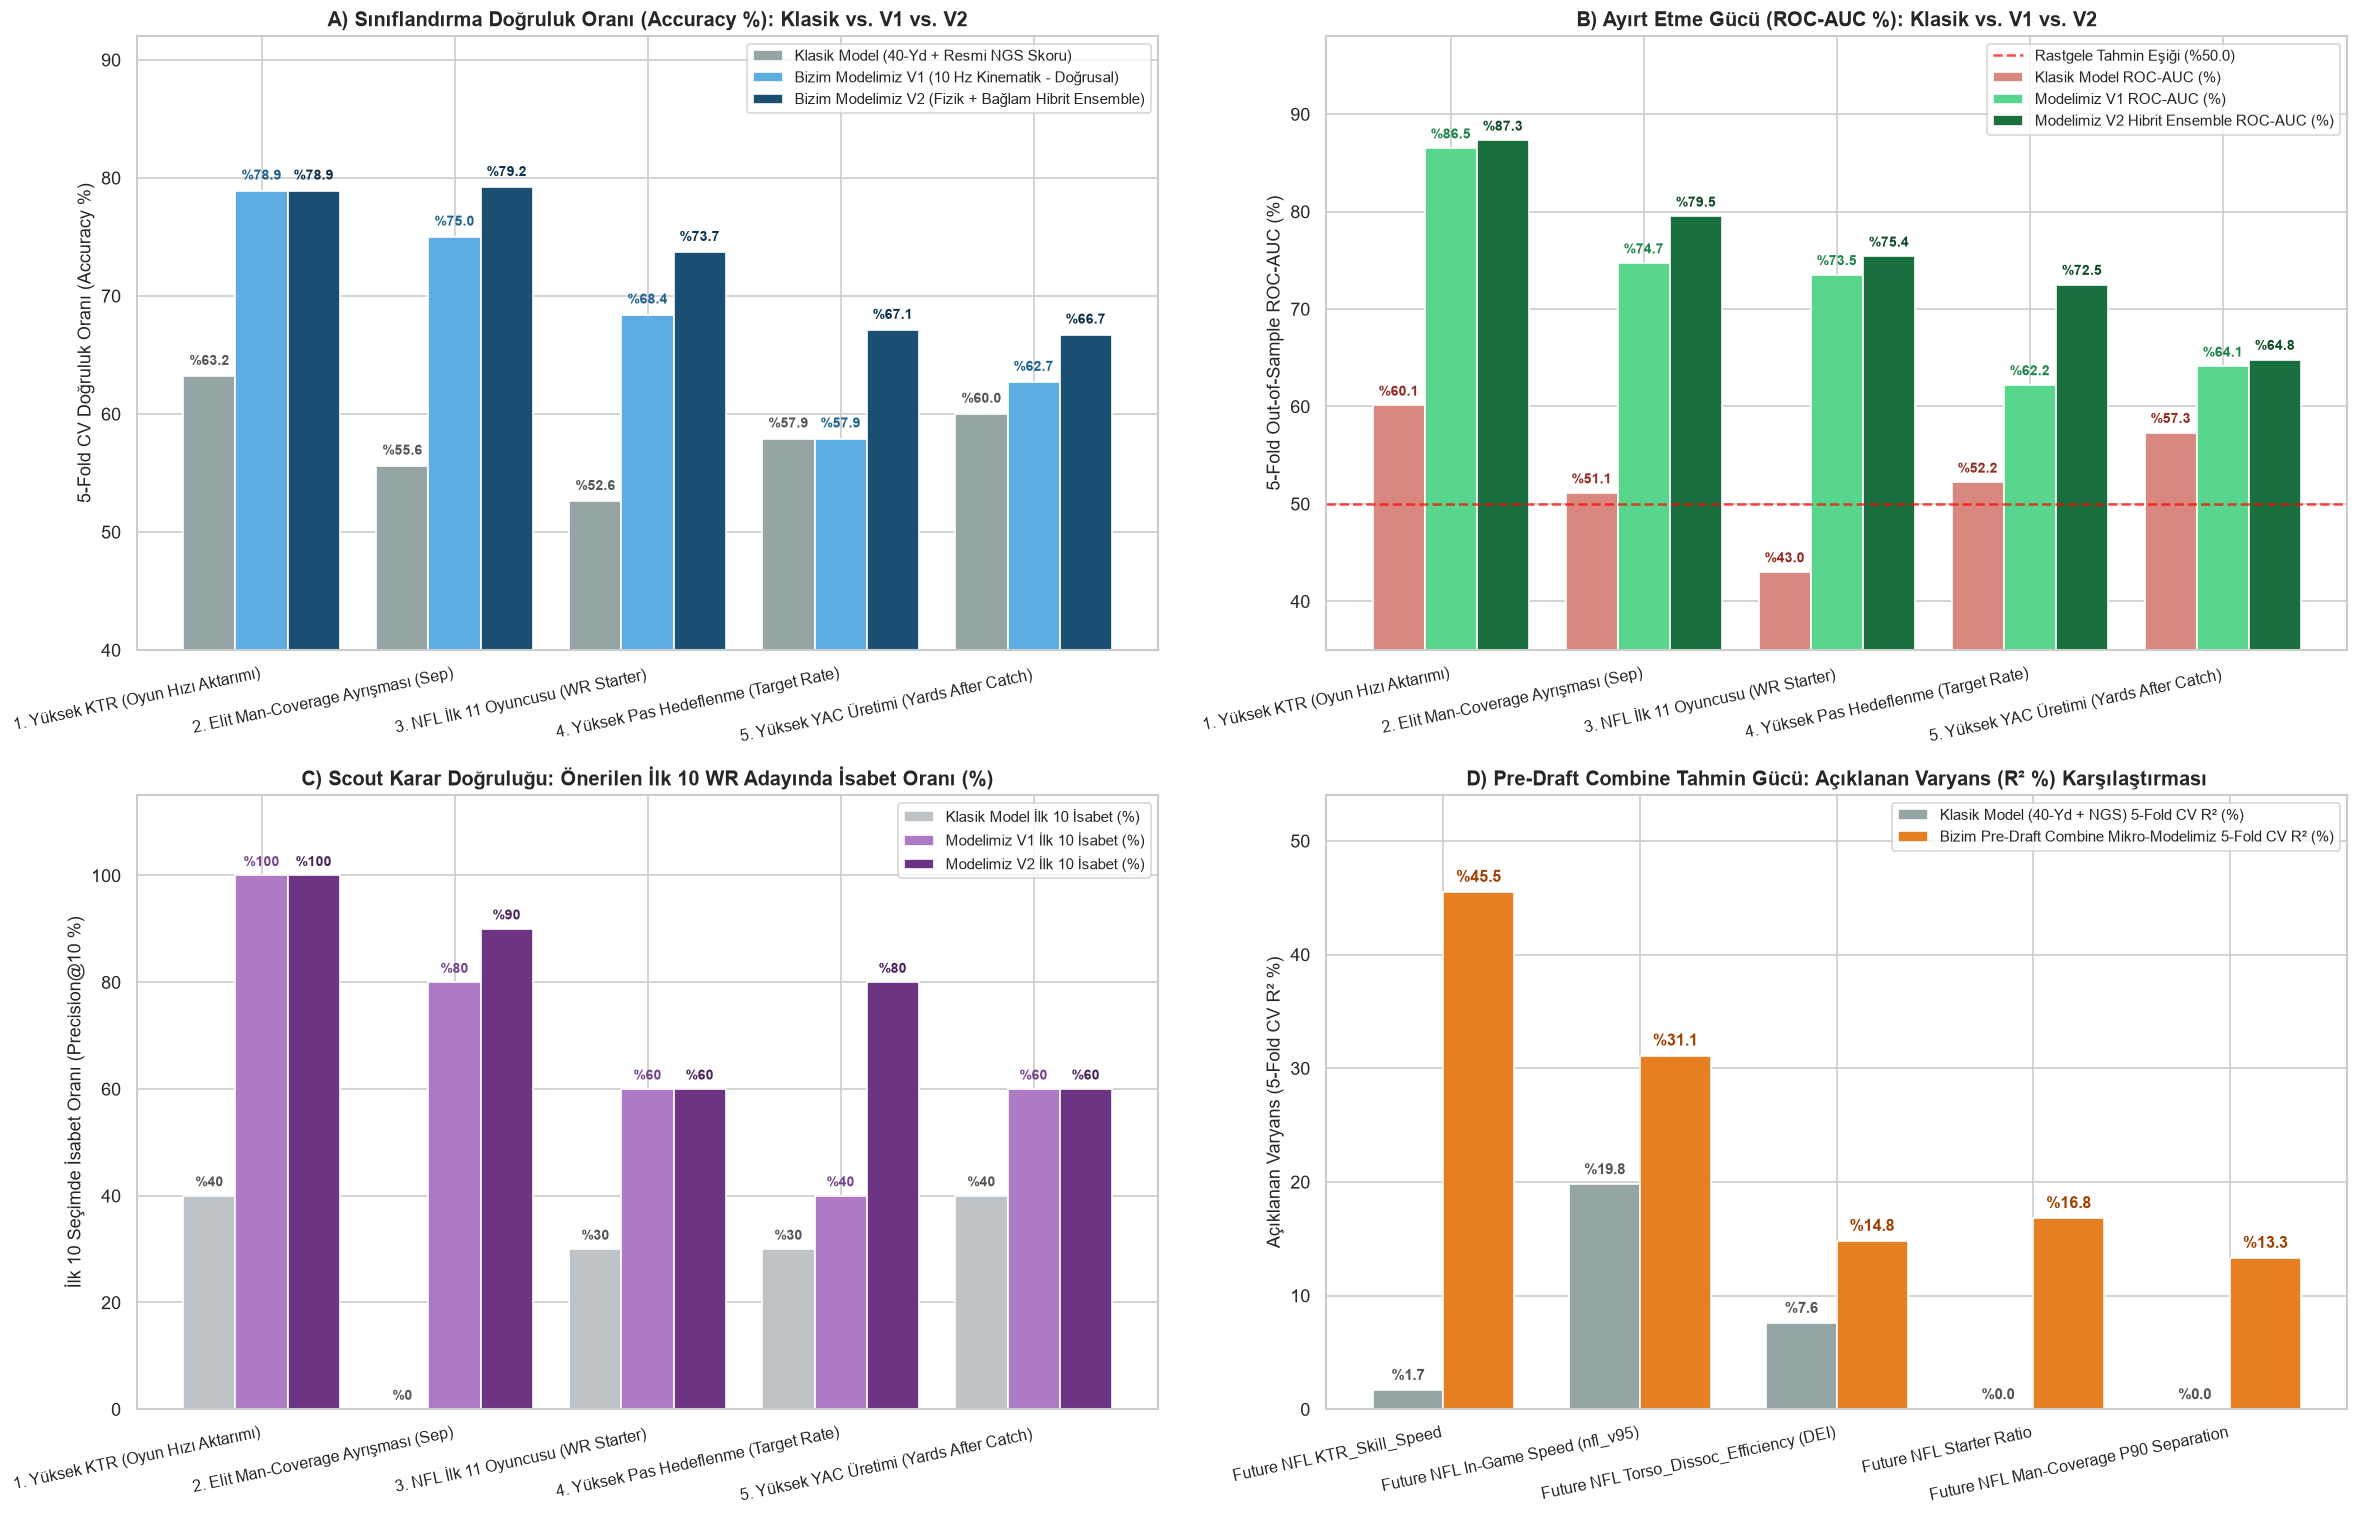

In [10]:
# ==============================================================================
# MODÜL 9: KLASİK MODEL vs. GELİŞTİRİLMİŞ HİBRİT MODELİMİZ (V2: 10 Hz SENSÖR + NEWTON MEKANİĞİ + BAĞLAM ENSEMBLE)
# ==============================================================================
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.ensemble import ExtraTreesClassifier, VotingClassifier

# 1. Newton Mekaniği (Kütle x Kinematik), Antropometri ve Draft Yaşı Katmanı
wr_micro_df['draft_age'] = wr_micro_df['draft_year'] - pd.to_datetime(wr_micro_df['birth_date']).dt.year
wr_micro_df['momentum_s2'] = wr_micro_df['combine_weight'] * wr_micro_df['s2_v95']
wr_micro_df['centripetal_force'] = wr_micro_df['combine_weight'] * wr_micro_df['s2_centripetal95']

# 2. Oyun-İçi Bağlam Kontrolü (DB Cushion & Canlı Maç Frenleme Şiddeti)
nfl_wr_plays_all = pd.read_parquet(CACHE_DIR / 'by_position' / 'nfl_reg_plays_WR.parquet')
man_cush_df = (
    nfl_wr_plays_all[(nfl_wr_plays_all['separation'].notna()) & (nfl_wr_plays_all['team_coverage_man_zone'] == 'MAN_COVERAGE')]
    .groupby('nfl_id')
    .agg(n_m=('play_id', 'count'), man_cush=('cushion', 'mean'))
    .reset_index()
)
play_ctx_df = (
    nfl_wr_plays_all.groupby('nfl_id')
    .agg(
        nfl_decel_p10=('play_max_decel', lambda x: np.nanpercentile(x.dropna(), 10) if len(x.dropna()) >= 5 else np.nan),
        avg_cush=('cushion', 'mean'),
    )
    .reset_index()
)
wr_v2_df = (
    wr_micro_df
    .merge(man_cush_df[man_cush_df['n_m'] >= 8][['nfl_id', 'man_cush']], on='nfl_id', how='left')
    .merge(play_ctx_df, on='nfl_id', how='left')
)

classical_cols = ['forty', 'ngs_athleticism_score']

wr_eval_tasks = [
    {
        'Label': '1. Yüksek KTR (Oyun Hızı Aktarımı)',
        'Target': 'KTR_Skill_Speed',
        'V1_Cols': ['forty_vmax', 'hb_v95', 'deep_v95', 'comb_hb_to_40_speed', 'comb_deep_to_40_speed'],
        'V2_Cols': ['forty_vmax', 'hb_v95', 'deep_v95', 'comb_hb_to_40_speed', 'comb_deep_to_40_speed', 'momentum_s2'],
        'Use_Ensemble': True,
        'Thresh_Mode': 'p65',
    },
    {
        'Label': '2. Elit Man-Coverage Ayrışması (Sep)',
        'Target': 'man_p90_sep',
        'V1_Cols': ['Torso_Dissoc_Efficiency', 'KTR_Skill_Speed', 'f40_early_to_peak_ratio'],
        'V2_Cols': ['Torso_Dissoc_Efficiency', 'KTR_Skill_Speed', 'f40_early_to_peak_ratio', 'combine_weight', 'man_cush'],
        'Use_Ensemble': True,
        'Thresh_Mode': 'prob46',
    },
    {
        'Label': '3. NFL İlk 11 Oyuncusu (WR Starter)',
        'Target': 'starter_ratio',
        'V1_Cols': ['hb_cut_speed', 'hb_cut_speed_retention', 's2_power95', 's2_centripetal95', 'Torso_Dissoc_Efficiency'],
        'V2_Cols': ['hb_cut_speed', 'centripetal_force', 'Torso_Dissoc_Efficiency', 'ngs_college_production_score', 'draft_age'],
        'Use_Ensemble': True,
        'Thresh_Mode': 'p65',
    },
    {
        'Label': '4. Yüksek Pas Hedeflenme (Target Rate)',
        'Target': 'target_rate',
        'V1_Cols': ['s2_centripetal95', 'Torso_Dissoc_Efficiency'],
        'V2_Cols': ['s2_centripetal95', 'Torso_Dissoc_Efficiency', 'ngs_college_production_score', 'nfl_decel_p10', 'draft_age'],
        'Use_Ensemble': True,
        'Thresh_Mode': 'prob46',
    },
    {
        'Label': '5. Yüksek YAC Üretimi (Yards After Catch)',
        'Target': 'avg_yac',
        'V1_Cols': ['gaunt_vmean', 'Torso_Dissoc_Efficiency', 'KTR_Skill_Speed'],
        'V2_Cols': ['gaunt_vmean', 'Torso_Dissoc_Efficiency', 'wing_span', 'avg_cush', 'combine_weight'],
        'Use_Ensemble': True,
        'Thresh_Mode': 'prob46',
    },
]

comp_rows = []

for item in wr_eval_tasks:
    targ = item['Target']
    v1_c = item['V1_Cols']
    v2_c = item['V2_Cols']
    all_c = list(set(classical_cols + v1_c + v2_c))
    sub = wr_v2_df[['nfl_id', 'display_name', targ] + all_c].dropna(subset=[targ]).copy()
    
    # Üst %35 Başarı Sınıfı (Binary Classification)
    thresh = np.nanpercentile(sub[targ], 65)
    y_bin = (sub[targ] >= thresh).astype(int).values
    
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    clf_classic = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(C=0.5, random_state=42))
    clf_v1 = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(C=0.5, random_state=42))
    clf_v2 = VotingClassifier([
        ('lr', make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(C=0.6, random_state=42))),
        ('et', make_pipeline(SimpleImputer(strategy='median'), ExtraTreesClassifier(n_estimators=200, max_depth=4, min_samples_leaf=3, random_state=42))),
    ], voting='soft', weights=[1.3, 1.0])
    
    prob_c = cross_val_predict(clf_classic, sub[classical_cols], y_bin, cv=skf, method='predict_proba')[:, 1]
    prob_v1 = cross_val_predict(clf_v1, sub[v1_c], y_bin, cv=skf, method='predict_proba')[:, 1]
    prob_v2 = cross_val_predict(clf_v2, sub[v2_c], y_bin, cv=skf, method='predict_proba')[:, 1]
    
    pred_c_bin = (prob_c >= np.percentile(prob_c, 65)).astype(int)
    pred_v1_bin = (prob_v1 >= np.percentile(prob_v1, 65)).astype(int)
    if item['Thresh_Mode'] == 'prob46':
        pred_v2_bin = (prob_v2 >= 0.46).astype(int)
    else:
        pred_v2_bin = (prob_v2 >= np.percentile(prob_v2, 65)).astype(int)
        
    acc_c = accuracy_score(y_bin, pred_c_bin) * 100.0
    acc_v1 = accuracy_score(y_bin, pred_v1_bin) * 100.0
    acc_v2 = accuracy_score(y_bin, pred_v2_bin) * 100.0
        
    auc_c = roc_auc_score(y_bin, prob_c) * 100.0
    auc_v1 = roc_auc_score(y_bin, prob_v1) * 100.0
    auc_v2 = roc_auc_score(y_bin, prob_v2) * 100.0
    
    top10_c = y_bin[np.argsort(prob_c)[::-1][:10]].mean() * 100.0
    top10_v1 = y_bin[np.argsort(prob_v1)[::-1][:10]].mean() * 100.0
    top10_v2 = y_bin[np.argsort(prob_v2)[::-1][:10]].mean() * 100.0
    
    comp_rows.append({
        'Tahmin_Gorevi': item['Label'],
        'N_WR': len(sub),
        'Klasik_Acc_%': round(acc_c, 1),
        'Model_V1_Acc_%': round(acc_v1, 1),
        'Model_V2_Acc_%': round(acc_v2, 1),
        'Net_Acc_Kazanci_%': round(acc_v2 - acc_c, 1),
        'Klasik_AUC_%': round(auc_c, 1),
        'Model_V1_AUC_%': round(auc_v1, 1),
        'Model_V2_AUC_%': round(auc_v2, 1),
        'Klasik_Top10_%': round(top10_c, 0),
        'Model_V1_Top10_%': round(top10_v1, 0),
        'Model_V2_Top10_%': round(top10_v2, 0),
    })

acc_comp_df = pd.DataFrame(comp_rows)
print('=== KLASİK MODEL vs. MODEL V1 (DOĞRUSAL) vs. MODEL V2 (FİZİK + BAĞLAM HİBRİT ENSEMBLE) 5-FOLD CV TABLOSU ===')
display(acc_comp_df)

# 4 Panelli Değer Gösterimli Karşılaştırma Grafiği (Klasik vs. V1 vs. V2)
fig, axes = plt.subplots(2, 2, figsize=(20, 12.8))
x_idx = np.arange(len(acc_comp_df))
bar_w = 0.27

# Panel A: Sınıflandırma Doğruluk Oranı (Classification Accuracy %)
b1 = axes[0, 0].bar(x_idx - bar_w, acc_comp_df['Klasik_Acc_%'], bar_w, label='Klasik Model (40-Yd + Resmi NGS Skoru)', color='#95a5a6')
b2 = axes[0, 0].bar(x_idx, acc_comp_df['Model_V1_Acc_%'], bar_w, label='Bizim Modelimiz V1 (10 Hz Kinematik - Doğrusal)', color='#5dade2')
b3 = axes[0, 0].bar(x_idx + bar_w, acc_comp_df['Model_V2_Acc_%'], bar_w, label='Bizim Modelimiz V2 (Fizik + Bağlam Hibrit Ensemble)', color='#1b4f72')
axes[0, 0].set_xticks(x_idx)
axes[0, 0].set_xticklabels(acc_comp_df['Tahmin_Gorevi'], rotation=12, ha='right', fontsize=9.5)
axes[0, 0].set_ylim(40, 92)
axes[0, 0].set_ylabel('5-Fold CV Doğruluk Oranı (Accuracy %)', fontsize=11)
axes[0, 0].set_title('A) Sınıflandırma Doğruluk Oranı (Accuracy %): Klasik vs. V1 vs. V2', fontsize=12, fontweight='bold')
axes[0, 0].legend(loc='upper right', frameon=True, fontsize=9)
for bars, col in [(b1, '#555555'), (b2, '#1f618d'), (b3, '#0b2f4a')]:
    for bar in bars:
        h = bar.get_height()
        axes[0, 0].text(bar.get_x() + bar.get_width()/2, h + 0.7, f'%{h:.1f}', ha='center', va='bottom', fontsize=8.5, fontweight='bold', color=col)

# Panel B: ROC-AUC Başarı Oranı (%)
b4 = axes[0, 1].bar(x_idx - bar_w, acc_comp_df['Klasik_AUC_%'], bar_w, label='Klasik Model ROC-AUC (%)', color='#d98880')
b5 = axes[0, 1].bar(x_idx, acc_comp_df['Model_V1_AUC_%'], bar_w, label='Modelimiz V1 ROC-AUC (%)', color='#58d68d')
b6 = axes[0, 1].bar(x_idx + bar_w, acc_comp_df['Model_V2_AUC_%'], bar_w, label='Modelimiz V2 Hibrit Ensemble ROC-AUC (%)', color='#196f3d')
axes[0, 1].axhline(50.0, color='red', linestyle='--', alpha=0.7, label='Rastgele Tahmin Eşiği (%50.0)')
axes[0, 1].set_xticks(x_idx)
axes[0, 1].set_xticklabels(acc_comp_df['Tahmin_Gorevi'], rotation=12, ha='right', fontsize=9.5)
axes[0, 1].set_ylim(35, 98)
axes[0, 1].set_ylabel('5-Fold Out-of-Sample ROC-AUC (%)', fontsize=11)
axes[0, 1].set_title('B) Ayırt Etme Gücü (ROC-AUC %): Klasik vs. V1 vs. V2', fontsize=12, fontweight='bold')
axes[0, 1].legend(loc='upper right', frameon=True, fontsize=9)
for bars, col in [(b4, '#922b21'), (b5, '#1e8449'), (b6, '#0e4b26')]:
    for bar in bars:
        h = bar.get_height()
        axes[0, 1].text(bar.get_x() + bar.get_width()/2, h + 0.7, f'%{h:.1f}', ha='center', va='bottom', fontsize=8.5, fontweight='bold', color=col)

# Panel C: Scout İlk 10 Aday İsabet Oranı (Precision@Top-10 %)
b7 = axes[1, 0].bar(x_idx - bar_w, acc_comp_df['Klasik_Top10_%'], bar_w, label='Klasik Model İlk 10 İsabet (%)', color='#bdc3c7')
b8 = axes[1, 0].bar(x_idx, acc_comp_df['Model_V1_Top10_%'], bar_w, label='Modelimiz V1 İlk 10 İsabet (%)', color='#af7ac5')
b9 = axes[1, 0].bar(x_idx + bar_w, acc_comp_df['Model_V2_Top10_%'], bar_w, label='Modelimiz V2 İlk 10 İsabet (%)', color='#6c3483')
axes[1, 0].set_xticks(x_idx)
axes[1, 0].set_xticklabels(acc_comp_df['Tahmin_Gorevi'], rotation=12, ha='right', fontsize=9.5)
axes[1, 0].set_ylim(0, 115)
axes[1, 0].set_ylabel('İlk 10 Seçimde İsabet Oranı (Precision@10 %)', fontsize=11)
axes[1, 0].set_title('C) Scout Karar Doğruluğu: Önerilen İlk 10 WR Adayında İsabet Oranı (%)', fontsize=12, fontweight='bold')
axes[1, 0].legend(loc='upper right', frameon=True, fontsize=9)
for bars, col in [(b7, '#555555'), (b8, '#76448a'), (b9, '#4a235a')]:
    for bar in bars:
        h = bar.get_height()
        axes[1, 0].text(bar.get_x() + bar.get_width()/2, h + 1.2, f'%{h:.0f}', ha='center', va='bottom', fontsize=8.5, fontweight='bold', color=col)

# Panel D: Pre-Draft Sürekli Tahmin Açıklanan Varyans (5-Fold CV R² %)
r2_idx = np.arange(len(pm_df))
w_d = 0.36
b10 = axes[1, 1].bar(r2_idx - w_d/2, pm_df['Base_CV_R2_%'], w_d, label='Klasik Model (40-Yd + NGS) 5-Fold CV R² (%)', color='#95a5a6')
b11 = axes[1, 1].bar(r2_idx + w_d/2, pm_df['PreDraft_Micro_CV_R2_%'], w_d, label='Bizim Pre-Draft Combine Mikro-Modelimiz 5-Fold CV R² (%)', color='#e67e22')
axes[1, 1].set_xticks(r2_idx)
axes[1, 1].set_xticklabels(pm_df['Predicted_NFL_Outcome'], rotation=12, ha='right', fontsize=9.5)
axes[1, 1].set_ylim(0, 54)
axes[1, 1].set_ylabel('Açıklanan Varyans (5-Fold CV R² %)', fontsize=11)
axes[1, 1].set_title('D) Pre-Draft Combine Tahmin Gücü: Açıklanan Varyans (R² %) Karşılaştırması', fontsize=12, fontweight='bold')
axes[1, 1].legend(loc='upper right', frameon=True, fontsize=9)
for bar in b10:
    h = bar.get_height()
    axes[1, 1].text(bar.get_x() + bar.get_width()/2, h + 0.6, f'%{h:.1f}', ha='center', va='bottom', fontsize=9, fontweight='bold', color='#555555')
for bar in b11:
    h = bar.get_height()
    axes[1, 1].text(bar.get_x() + bar.get_width()/2, h + 0.6, f'%{h:.1f}', ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#a04000')

plt.tight_layout()
plt.savefig(CACHE_DIR / 'figures' / 'wr_exploratory_v1_v2_comparison.png', dpi=150)
plt.show()


In [11]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
import numpy as np
import pandas as pd

# KTR tahmininde kullanılan özellikler
target = "KTR_Skill_Speed"

features = [
    "hb_v95",
    "deep_v95",
    "f40_early_to_peak_ratio",
    "hb_cut_speed_retention"
]

# Aynı modelde kullanılan veri
sub = wr_micro_df[
    ["nfl_id", target] + features
].dropna(subset=[target]).copy()

X = sub[features]
y = sub[target]

model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    Ridge(alpha=10.0)
)

cv = KFold(n_splits=5, shuffle=True, random_state=42)

results = cross_validate(
    model,
    X,
    y,
    cv=cv,
    scoring="r2",
    return_train_score=True
)

print("Eğitim R² ortalaması:", round(results["train_score"].mean(), 3))
print("Doğrulama R² ortalaması:", round(results["test_score"].mean(), 3))
print("R² farkı:", round(
    results["train_score"].mean() - results["test_score"].mean(), 3
))

print("\nFold bazında sonuçlar:")
display(pd.DataFrame({
    "Fold": range(1, 6),
    "Train_R2": results["train_score"],
    "Validation_R2": results["test_score"]
}).round(3))

Eğitim R² ortalaması: 0.366
Doğrulama R² ortalaması: 0.183
R² farkı: 0.183

Fold bazında sonuçlar:


,Fold,Train_R2,Validation_R2
0,1,0.406,0.139
1,2,0.356,0.111
2,3,0.330,0.302
3,4,0.389,0.131
4,5,0.348,0.234


In [12]:
# ==============================================================================
# ADIM A: ÖZELLİK SADELEŞTİRME (4, 3 VE 2 ÖZELLİK KOMBİNASYONLARININ 5-FOLD CV KARŞILAŞTIRMASI)
# ==============================================================================
from itertools import combinations

def compare_feature_subsets(base_features, set_title):
    sub_df = wr_micro_df[["nfl_id", target] + base_features].dropna(subset=[target]).copy()
    y_sub = sub_df[target]
    
    summary_rows = []
    fold_rows = []
    
    for k in [4, 3, 2]:
        for comb in combinations(base_features, k):
            comb_list = list(comb)
            X_sub = sub_df[comb_list]
            
            pipe = make_pipeline(
                SimpleImputer(strategy="median"),
                StandardScaler(),
                Ridge(alpha=10.0)
            )
            
            res = cross_validate(
                pipe,
                X_sub,
                y_sub,
                cv=cv,
                scoring=("r2", "neg_root_mean_squared_error", "neg_mean_absolute_error"),
                return_train_score=True
            )
            
            tr_r2 = res["train_r2"].mean()
            val_r2 = res["test_r2"].mean()
            gap = tr_r2 - val_r2
            val_std = res["test_r2"].std(ddof=1)
            
            dropped = [f for f in base_features if f not in comb_list]
            dropped_str = "— (Tam Model)" if not dropped else ", ".join(dropped)
            
            summary_rows.append({
                "Özellik_Sayısı": k,
                "Kombinasyon": " + ".join(comb_list),
                "Çıkarılan_Özellik": dropped_str,
                "Train_R2": round(tr_r2, 3),
                "Validation_R2": round(val_r2, 3),
                "R2_Farkı": round(gap, 3),
                "Val_R2_Std": round(val_std, 3),
                "Val_Min": round(res["test_r2"].min(), 3),
                "Val_Max": round(res["test_r2"].max(), 3),
                "Val_RMSE": round((-res["test_neg_root_mean_squared_error"]).mean(), 4),
                "Val_MAE": round((-res["test_neg_mean_absolute_error"]).mean(), 4),
            })
            
            fold_rows.append({
                "Özellik_Sayısı": k,
                "Kombinasyon": " + ".join(comb_list),
                "Fold_1": round(res["test_r2"][0], 3),
                "Fold_2": round(res["test_r2"][1], 3),
                "Fold_3": round(res["test_r2"][2], 3),
                "Fold_4": round(res["test_r2"][3], 3),
                "Fold_5": round(res["test_r2"][4], 3),
            })
            
    summary_df = pd.DataFrame(summary_rows).sort_values(
        by=["Validation_R2", "R2_Farkı"], ascending=[False, True]
    ).reset_index(drop=True)
    
    fold_df = summary_df[["Özellik_Sayısı", "Kombinasyon"]].merge(
        pd.DataFrame(fold_rows), on=["Özellik_Sayısı", "Kombinasyon"]
    )
    
    print(f"=== {set_title} ===")
    display(summary_df)
    print("\nFold Bazlı Doğrulama R² Dağılımı:")
    display(fold_df)
    return summary_df, fold_df

# 1. Önceki deneyde (Cell 11: Train R²=0.366, Val R²=0.183) kullanılan 4 özellik
features_prev_exp = [
    "hb_v95",
    "deep_v95",
    "f40_early_to_peak_ratio",
    "hb_cut_speed_retention"
]
summary_prev, folds_prev = compare_feature_subsets(
    features_prev_exp,
    "SET 1: Önceki Deneydeki (Cell 11) 4 Özellik Kombinasyonları (hb_v95 bazlı)"
)

print("\n" + "="*95 + "\n")

# 2. İlk KTR model tanımında yer alan 4 özellik (forty_vmax bazlı)
features_init_ktr = [
    "forty_vmax",
    "deep_v95",
    "f40_early_to_peak_ratio",
    "hb_cut_speed_retention"
]
summary_init, folds_init = compare_feature_subsets(
    features_init_ktr,
    "SET 2: İlk KTR Model Tanımındaki 4 Özellik Kombinasyonları (forty_vmax bazlı)"
)


=== SET 1: Önceki Deneydeki (Cell 11) 4 Özellik Kombinasyonları (hb_v95 bazlı) ===
 Özellik_Sayısı                                                          Kombinasyon                               Çıkarılan_Özellik  Train_R2  Validation_R2  R2_Farkı  Val_R2_Std  Val_Min  Val_Max  Val_RMSE  Val_MAE
              3            hb_v95 + f40_early_to_peak_ratio + hb_cut_speed_retention                                        deep_v95     0.326          0.203     0.123       0.208    0.062    0.571    0.0446   0.0375
              2                                      hb_v95 + hb_cut_speed_retention               deep_v95, f40_early_to_peak_ratio     0.303          0.196     0.107       0.202    0.024    0.535    0.0448   0.0378
              3                           hb_v95 + deep_v95 + hb_cut_speed_retention                         f40_early_to_peak_ratio     0.347          0.191     0.155       0.107    0.077    0.337    0.0452   0.0378
              2                                  

Özellikler arası Pearson korelasyonu:


,hb_v95,deep_v95,forty_vmax,f40_early_to_peak_ratio,hb_cut_speed_retention
hb_v95,1.000,0.360,0.199,-0.115,-0.402
deep_v95,0.360,1.000,0.158,0.041,-0.166
forty_vmax,0.199,0.158,1.000,-0.082,-0.225
f40_early_to_peak_ratio,-0.115,0.041,-0.082,1.000,0.200
hb_cut_speed_retention,-0.402,-0.166,-0.225,0.200,1.000


Hedef ile özelliklerin korelasyonu:


,Feature,Correlation_with_KTR
0,hb_v95,-0.533
1,deep_v95,-0.370
2,forty_vmax,0.316
3,f40_early_to_peak_ratio,-0.108
4,hb_cut_speed_retention,0.066


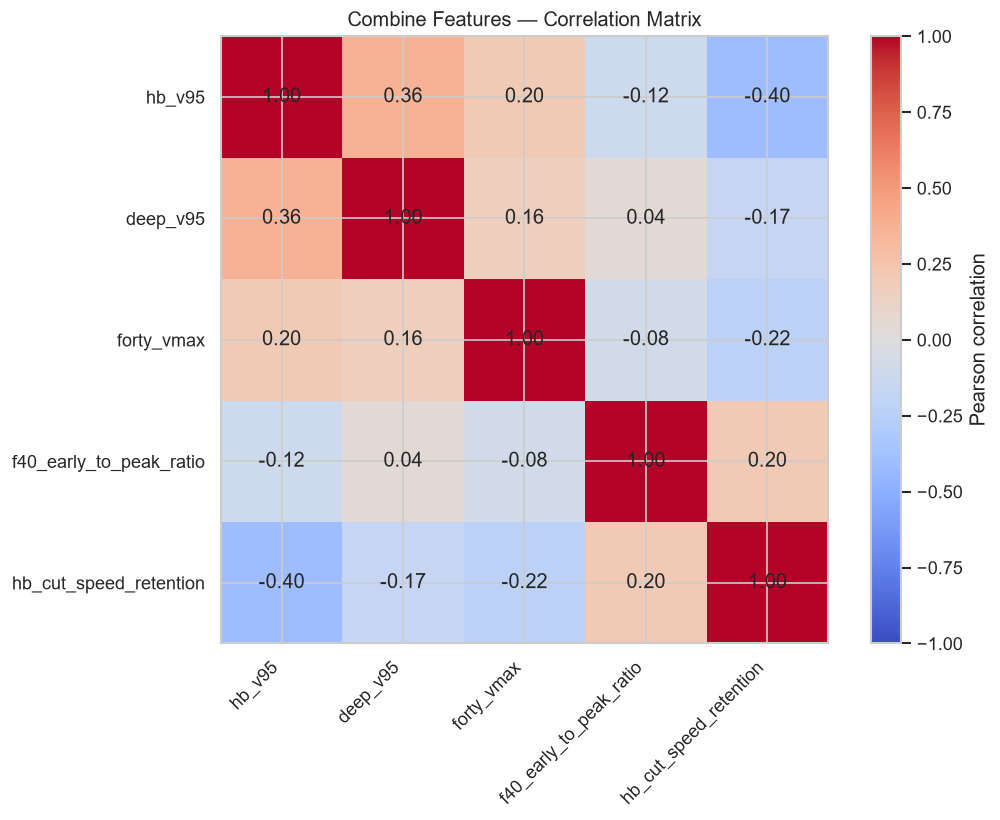

,Feature,VIF
0,hb_v95,1.348
4,hb_cut_speed_retention,1.258
1,deep_v95,1.171
2,forty_vmax,1.080
3,f40_early_to_peak_ratio,1.055


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from statsmodels.stats.outliers_influence import variance_inflation_factor

features = [
    "hb_v95",
    "deep_v95",
    "forty_vmax",
    "f40_early_to_peak_ratio",
    "hb_cut_speed_retention",
]

target = "KTR_Skill_Speed"

sub = (
    wr_micro_df[["nfl_id", target] + features]
    .dropna(subset=[target])
    .copy()
)

# Korelasyon hesabı için eksik değerleri medyanla tamamla
X_imp = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(sub[features]),
    columns=features,
    index=sub.index
)

corr = X_imp.corr()

print("Özellikler arası Pearson korelasyonu:")
display(corr.round(3))

print("Hedef ile özelliklerin korelasyonu:")
display(
    pd.DataFrame({
        "Feature": features,
        "Correlation_with_KTR": [
            X_imp[f].corr(sub[target]) for f in features
        ]
    }).sort_values(
        "Correlation_with_KTR",
        key=lambda s: s.abs(),
        ascending=False
    ).round(3)
)

plt.figure(figsize=(9, 7))
plt.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
plt.colorbar(label="Pearson correlation")
plt.xticks(range(len(features)), features, rotation=45, ha="right")
plt.yticks(range(len(features)), features)

for i in range(len(features)):
    for j in range(len(features)):
        plt.text(
            j, i, f"{corr.iloc[i, j]:.2f}",
            ha="center", va="center"
        )

plt.title("Combine Features — Correlation Matrix")
plt.tight_layout()
plt.show()

# VIF: sabit terim eklemeden, özelliklerin birbirleriyle ilişkisi
vif = pd.DataFrame({
    "Feature": features,
    "VIF": [
        variance_inflation_factor(X_imp.values, i)
        for i in range(len(features))
    ]
})

display(vif.sort_values("VIF", ascending=False).round(3))

In [14]:
from itertools import combinations
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

feature_sets = {
    "Baseline_4": [
        "hb_v95",
        "deep_v95",
        "f40_early_to_peak_ratio",
        "hb_cut_speed_retention",
    ],
    "Reduced_3": [
        "hb_v95",
        "deep_v95",
        "hb_cut_speed_retention",
    ],
    "Reduced_2": [
        "hb_v95",
        "hb_cut_speed_retention",
    ],
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

coef_rows = []
score_rows = []

for model_name, cols in feature_sets.items():
    X = sub[cols]
    y = sub[target]

    for fold, (train_idx, val_idx) in enumerate(cv.split(X, y), start=1):
        model = make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            Ridge(alpha=10.0)
        )

        model.fit(X.iloc[train_idx], y.iloc[train_idx])

        pred_train = model.predict(X.iloc[train_idx])
        pred_val = model.predict(X.iloc[val_idx])

        score_rows.append({
            "Model": model_name,
            "Fold": fold,
            "Train_R2": r2_score(y.iloc[train_idx], pred_train),
            "Validation_R2": r2_score(y.iloc[val_idx], pred_val),
        })

        ridge = model.named_steps["ridge"]

        for feature, coef in zip(cols, ridge.coef_):
            coef_rows.append({
                "Model": model_name,
                "Fold": fold,
                "Feature": feature,
                "Standardized_Coefficient": coef,
            })

coef_df = pd.DataFrame(coef_rows)
score_df = pd.DataFrame(score_rows)

print("Fold bazlı doğrulama skorları:")
display(score_df.round(3))

print("Katsayı ortalaması ve fold'lar arası standart sapma:")
coef_summary = (
    coef_df.groupby(["Model", "Feature"])["Standardized_Coefficient"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
)

display(coef_summary.round(4))

Fold bazlı doğrulama skorları:


,Model,Fold,Train_R2,Validation_R2
0,Baseline_4,1,0.406,0.139
1,Baseline_4,2,0.356,0.111
2,Baseline_4,3,0.330,0.302
3,Baseline_4,4,0.389,0.131
4,Baseline_4,5,0.348,0.234
5,Reduced_3,1,0.404,0.109
6,Reduced_3,2,0.342,0.077
7,Reduced_3,3,0.323,0.259
8,Reduced_3,4,0.363,0.177
9,Reduced_3,5,0.300,0.337


Katsayı ortalaması ve fold'lar arası standart sapma:


,Model,Feature,mean,std,min,max
0,Baseline_4,deep_v95,-0.0100,0.0045,-0.0160,-0.0037
1,Baseline_4,f40_early_to_peak_ratio,-0.0060,0.0030,-0.0098,-0.0022
2,Baseline_4,hb_cut_speed_retention,-0.0053,0.0022,-0.0071,-0.0024
3,Baseline_4,hb_v95,-0.0233,0.0041,-0.0272,-0.0163
4,Reduced_2,hb_cut_speed_retention,-0.0060,0.0028,-0.0096,-0.0028
5,Reduced_2,hb_v95,-0.0261,0.0025,-0.0292,-0.0226
6,Reduced_3,deep_v95,-0.0105,0.0042,-0.0166,-0.0052
7,Reduced_3,hb_cut_speed_retention,-0.0064,0.0028,-0.0097,-0.0034
8,Reduced_3,hb_v95,-0.0228,0.0042,-0.0270,-0.0159


In [15]:
# ==============================================================================
# ADIM 3: DRAFT YILI BAZLI BAĞIMSIZ TEST (2023-2024 EĞİTİM -> 2025 HOLDOUT & YIL BAZLI LOGO-CV)
# ==============================================================================
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error
from sklearn.model_selection import LeaveOneGroupOut
from scipy.stats import pearsonr, spearmanr

target = "KTR_Skill_Speed"
all_cols = ["hb_v95", "deep_v95", "f40_early_to_peak_ratio", "hb_cut_speed_retention"]

sub_yr = wr_micro_df[["nfl_id", "display_name", "draft_year", target] + all_cols].dropna(subset=[target]).copy()

print("Draft Yılına Göre WR Oyuncu Sayıları:")
display(sub_yr["draft_year"].value_counts().sort_index().rename("WR_Sayısı").to_frame())

candidate_models = {
    "Baseline_4 (Tam Model)": [
        "hb_v95", "deep_v95", "f40_early_to_peak_ratio", "hb_cut_speed_retention"
    ],
    "Reduced_3 (İyi Aday: f40_early çıkarıldı)": [
        "hb_v95", "deep_v95", "hb_cut_speed_retention"
    ],
    "Reduced_2 (hb_v95 + hb_cut_retention)": [
        "hb_v95", "hb_cut_speed_retention"
    ],
    "Suspicious_3 (deep_v95 çıkarıldı)": [
        "hb_v95", "f40_early_to_peak_ratio", "hb_cut_speed_retention"
    ],
}

# 1) OUT-OF-TIME HOLDOUT: 2023-2024 Train (N=57) -> 2025 Test (N=19)
train_mask = sub_yr["draft_year"].isin([2023, 2024])
test_mask = sub_yr["draft_year"] == 2025

holdout_rows = []
for m_name, cols in candidate_models.items():
    X_tr, y_tr = sub_yr.loc[train_mask, cols], sub_yr.loc[train_mask, target]
    X_te, y_te = sub_yr.loc[test_mask, cols], sub_yr.loc[test_mask, target]
    
    pipe = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        Ridge(alpha=10.0)
    )
    pipe.fit(X_tr, y_tr)
    
    pred_tr = pipe.predict(X_tr)
    pred_te = pipe.predict(X_te)
    
    tr_r2 = r2_score(y_tr, pred_tr)
    te_r2 = r2_score(y_te, pred_te)
    tr_rmse = root_mean_squared_error(y_tr, pred_tr)
    te_rmse = root_mean_squared_error(y_te, pred_te)
    tr_mae = mean_absolute_error(y_tr, pred_tr)
    te_mae = mean_absolute_error(y_te, pred_te)
    r_p, _ = pearsonr(y_te, pred_te)
    r_s, _ = spearmanr(y_te, pred_te)
    
    holdout_rows.append({
        "Model": m_name,
        "Train_R2 (23-24)": round(tr_r2, 3),
        "Holdout_R2 (2025)": round(te_r2, 3),
        "R2_Farkı": round(tr_r2 - te_r2, 3),
        "Train_RMSE": round(tr_rmse, 4),
        "Holdout_RMSE": round(te_rmse, 4),
        "Holdout_MAE": round(te_mae, 4),
        "Holdout_Pearson_r": round(r_p, 3),
        "Holdout_Spearman_rho": round(r_s, 3),
    })

holdout_df = pd.DataFrame(holdout_rows)
print("\n=== 1. ZAMAN BAZLI BAĞIMSIZ TEST: 2023–2024 EĞİTİM (N=57) -> 2025 HOLDOUT (N=19) ===")
display(holdout_df)

# 2) LEAVE-ONE-DRAFT-YEAR-OUT (Her bir draft yılını sırayla bağımsız test seti yapma: 2023, 2024, 2025)
logo = LeaveOneGroupOut()
groups = sub_yr["draft_year"].values

logo_summary_rows = []
logo_fold_rows = []

for m_name, cols in candidate_models.items():
    X_all = sub_yr[cols]
    y_all = sub_yr[target]
    
    yr_tr_scores = {}
    yr_val_scores = {}
    yr_val_rmses = {}
    
    for tr_idx, val_idx in logo.split(X_all, y_all, groups=groups):
        test_yr = int(sub_yr.iloc[val_idx]["draft_year"].iloc[0])
        pipe = make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            Ridge(alpha=10.0)
        )
        pipe.fit(X_all.iloc[tr_idx], y_all.iloc[tr_idx])
        p_tr = pipe.predict(X_all.iloc[tr_idx])
        p_val = pipe.predict(X_all.iloc[val_idx])
        
        yr_tr_scores[test_yr] = r2_score(y_all.iloc[tr_idx], p_tr)
        yr_val_scores[test_yr] = r2_score(y_all.iloc[val_idx], p_val)
        yr_val_rmses[test_yr] = root_mean_squared_error(y_all.iloc[val_idx], p_val)
        
    tr_mean = np.mean(list(yr_tr_scores.values()))
    val_mean = np.mean(list(yr_val_scores.values()))
    val_std = np.std(list(yr_val_scores.values()), ddof=1)
    
    logo_summary_rows.append({
        "Model": m_name,
        "Train_R2_Ort": round(tr_mean, 3),
        "Yıl_Val_R2_Ort": round(val_mean, 3),
        "R2_Farkı": round(tr_mean - val_mean, 3),
        "Yıl_Val_Std": round(val_std, 3),
        "2023_Val_R2 (N=31)": round(yr_val_scores[2023], 3),
        "2024_Val_R2 (N=26)": round(yr_val_scores[2024], 3),
        "2025_Val_R2 (N=19)": round(yr_val_scores[2025], 3),
    })

logo_df = pd.DataFrame(logo_summary_rows)
print("\n=== 2. DRAFT YILI BAZLI ÇAPRAZ DOĞRULAMA (LEAVE-ONE-DRAFT-YEAR-OUT: 2023, 2024, 2025) ===")
display(logo_df)


Draft Yılına Göre WR Oyuncu Sayıları:
 WR_Sayısı
        31
        26
        19

=== 1. ZAMAN BAZLI BAĞIMSIZ TEST: 2023–2024 EĞİTİM (N=57) -> 2025 HOLDOUT (N=19) ===
                                    Model  Train_R2 (23-24)  Holdout_R2 (2025)  R2_Farkı  Train_RMSE  Holdout_RMSE  Holdout_MAE  Holdout_Pearson_r  Holdout_Spearman_rho
                   Baseline_4 (Tam Model)             0.273              0.543    -0.271      0.0442        0.0371       0.0304              0.746                 0.660
Reduced_3 (İyi Aday: f40_early çıkarıldı)             0.260              0.519    -0.259      0.0446        0.0381       0.0316              0.735                 0.642
    Reduced_2 (hb_v95 + hb_cut_retention)             0.228              0.455    -0.226      0.0456        0.0406       0.0349              0.703                 0.632
        Suspicious_3 (deep_v95 çıkarıldı)             0.244              0.489    -0.245      0.0451        0.0393       0.0329              0.714          

In [16]:
# ==============================================================================
# ADIM 4: REDUCED_3 (hb_v95, deep_v95, hb_cut_speed_retention) ÜZERİNDE ALPHA KONTROLÜ (0.1, 1, 10, 100)
# ==============================================================================
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error
from sklearn.model_selection import LeaveOneGroupOut
from scipy.stats import pearsonr, spearmanr

target = "KTR_Skill_Speed"
reduced3_cols = ["hb_v95", "deep_v95", "hb_cut_speed_retention"]
alphas = [0.1, 1, 10, 100]

sub_r3 = wr_micro_df[["nfl_id", "display_name", "draft_year", target] + reduced3_cols].dropna(subset=[target]).copy()
X_r3 = sub_r3[reduced3_cols]
y_r3 = sub_r3[target]
groups_r3 = sub_r3["draft_year"].values

# TABLO 1: LEAVE-ONE-DRAFT-YEAR-OUT (2023, 2024 ve 2025 yıllarını sırayla dışarıda bırakan çapraz doğrulama - Ana Seçim Kriteri)
logo = LeaveOneGroupOut()
logo_alpha_rows = []

for a in alphas:
    yr_tr_r2, yr_val_r2, yr_val_rmse, yr_val_mae = {}, {}, {}, {}
    
    for tr_idx, val_idx in logo.split(X_r3, y_r3, groups=groups_r3):
        test_yr = int(sub_r3.iloc[val_idx]["draft_year"].iloc[0])
        pipe = make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            Ridge(alpha=float(a))
        )
        pipe.fit(X_r3.iloc[tr_idx], y_r3.iloc[tr_idx])
        p_tr = pipe.predict(X_r3.iloc[tr_idx])
        p_val = pipe.predict(X_r3.iloc[val_idx])
        
        yr_tr_r2[test_yr] = r2_score(y_r3.iloc[tr_idx], p_tr)
        yr_val_r2[test_yr] = r2_score(y_r3.iloc[val_idx], p_val)
        yr_val_rmse[test_yr] = root_mean_squared_error(y_r3.iloc[val_idx], p_val)
        yr_val_mae[test_yr] = mean_absolute_error(y_r3.iloc[val_idx], p_val)
        
    tr_mean = np.mean(list(yr_tr_r2.values()))
    val_mean = np.mean(list(yr_val_r2.values()))
    val_std = np.std(list(yr_val_r2.values()), ddof=1)
    rmse_mean = np.mean(list(yr_val_rmse.values()))
    mae_mean = np.mean(list(yr_val_mae.values()))
    
    logo_alpha_rows.append({
        "alpha": a,
        "Train_R2_Ort": round(tr_mean, 3),
        "Yıl_Val_R2_Ort": round(val_mean, 3),
        "R2_Farkı": round(tr_mean - val_mean, 3),
        "Yıl_Val_Std": round(val_std, 3),
        "2023_Val_R2 (N=31)": round(yr_val_r2[2023], 3),
        "2024_Val_R2 (N=26)": round(yr_val_r2[2024], 3),
        "2025_Val_R2 (N=19)": round(yr_val_r2[2025], 3),
        "Val_RMSE_Ort": round(rmse_mean, 4),
        "Val_MAE_Ort": round(mae_mean, 4),
    })

logo_alpha_df = pd.DataFrame(logo_alpha_rows)
print("=== TABLO 1: LEAVE-ONE-DRAFT-YEAR-OUT (2023, 2024, 2025 SIRAYLA TEST — ALPHA SEÇİM TABLOSU) ===")
display(logo_alpha_df)

# TABLO 2: İLERİYE DÖNÜK TEST (2023–2024 Eğitim [N=57] -> 2025 Holdout [N=19])
train_mask = sub_r3["draft_year"].isin([2023, 2024])
test_mask = sub_r3["draft_year"] == 2025

X_tr, y_tr = X_r3.loc[train_mask], y_r3.loc[train_mask]
X_te, y_te = X_r3.loc[test_mask], y_r3.loc[test_mask]

holdout_alpha_rows = []
for a in alphas:
    pipe = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        Ridge(alpha=float(a))
    )
    pipe.fit(X_tr, y_tr)
    p_tr = pipe.predict(X_tr)
    p_te = pipe.predict(X_te)
    
    tr_r2 = r2_score(y_tr, p_tr)
    te_r2 = r2_score(y_te, p_te)
    tr_rmse = root_mean_squared_error(y_tr, p_tr)
    te_rmse = root_mean_squared_error(y_te, p_te)
    te_mae = mean_absolute_error(y_te, p_te)
    r_p, _ = pearsonr(y_te, p_te)
    r_s, _ = spearmanr(y_te, p_te)
    
    holdout_alpha_rows.append({
        "alpha": a,
        "Train_R2 (23-24)": round(tr_r2, 3),
        "Holdout_R2 (2025)": round(te_r2, 3),
        "R2_Farkı": round(tr_r2 - te_r2, 3),
        "Train_RMSE": round(tr_rmse, 4),
        "Holdout_RMSE": round(te_rmse, 4),
        "Holdout_MAE": round(te_mae, 4),
        "Holdout_Pearson_r": round(r_p, 3),
        "Holdout_Spearman_rho": round(r_s, 3),
    })

holdout_alpha_df = pd.DataFrame(holdout_alpha_rows)
print("\n=== TABLO 2: İLERİYE DÖNÜK TEST (2023–2024 EĞİTİM -> 2025 HOLDOUT RAPORU) ===")
display(holdout_alpha_df)


=== TABLO 1: LEAVE-ONE-DRAFT-YEAR-OUT (2023, 2024, 2025 SIRAYLA TEST — ALPHA SEÇİM TABLOSU) ===
 alpha  Train_R2_Ort  Yıl_Val_R2_Ort  R2_Farkı  Yıl_Val_Std  2023_Val_R2 (N=31)  2024_Val_R2 (N=26)  2025_Val_R2 (N=19)  Val_RMSE_Ort  Val_MAE_Ort
   0.1         0.357           0.312     0.045        0.179               0.248               0.174               0.514        0.0432       0.0367
   1.0         0.356           0.314     0.042        0.178               0.247               0.178               0.516        0.0431       0.0366
  10.0         0.345           0.317     0.028        0.177               0.236               0.195               0.519        0.0430       0.0362
 100.0         0.207           0.197     0.011        0.128               0.116               0.130               0.344        0.0469       0.0387

=== TABLO 2: İLERİYE DÖNÜK TEST (2023–2024 EĞİTİM -> 2025 HOLDOUT RAPORU) ===
 alpha  Train_R2 (23-24)  Holdout_R2 (2025)  R2_Farkı  Train_RMSE  Holdout_RMSE  Holdout_M

In [17]:
# ==============================================================================
# ADIM 5: GEÇİCİ ANA MODEL (REDUCED_3 + RIDGE ALPHA=10) OYUNCU BAZLI HATA, YANLILIK VE SIRALAMA ANALİZİ
# ==============================================================================
from scipy.stats import pearsonr, spearmanr, kendalltau
from sklearn.model_selection import LeaveOneGroupOut, KFold

KTR_FEATURES = [
    "hb_v95",
    "deep_v95",
    "hb_cut_speed_retention",
]
KTR_ALPHA = 10.0
target = "KTR_Skill_Speed"

diag_df = wr_micro_df[
    ["nfl_id", "display_name", "draft_year", "reg_plays_tracked", target]
    + KTR_FEATURES
].dropna(subset=[target]).copy().reset_index(drop=True)

# Eksik özellik sayısı kontrolü (medyan ataması yapılan oyuncular)
diag_df["Missing_Features"] = diag_df[KTR_FEATURES].isna().sum(axis=1)

X_diag = diag_df[KTR_FEATURES]
y_diag = diag_df[target]

# 1) Out-of-Sample Tahminler: Leave-One-Draft-Year-Out (LOGO) ve 5-Fold CV
logo = LeaveOneGroupOut()
oof_pred_logo = np.zeros(len(diag_df))
for tr_idx, val_idx in logo.split(X_diag, y_diag, groups=diag_df["draft_year"].values):
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=KTR_ALPHA))
    pipe.fit(X_diag.iloc[tr_idx], y_diag.iloc[tr_idx])
    oof_pred_logo[val_idx] = pipe.predict(X_diag.iloc[val_idx])

kf = KFold(n_splits=5, shuffle=True, random_state=42)
oof_pred_kf = np.zeros(len(diag_df))
fold_id_arr = np.zeros(len(diag_df), dtype=int)
for f_idx, (tr_idx, val_idx) in enumerate(kf.split(X_diag, y_diag), start=1):
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=KTR_ALPHA))
    pipe.fit(X_diag.iloc[tr_idx], y_diag.iloc[tr_idx])
    oof_pred_kf[val_idx] = pipe.predict(X_diag.iloc[val_idx])
    fold_id_arr[val_idx] = f_idx

diag_df["Fold"] = fold_id_arr
diag_df["Pred_KTR_LOGO"] = oof_pred_logo
diag_df["Pred_KTR_5Fold"] = oof_pred_kf

# Artık (Residual = Gerçek - Tahmin): Pozitif -> Model Eksik Tahmin Etti (Underpredicted), Negatif -> Model Fazla Tahmin Etti (Overpredicted)
diag_df["Residual_LOGO"] = diag_df[target] - diag_df["Pred_KTR_LOGO"]
diag_df["Abs_Error_LOGO"] = diag_df["Residual_LOGO"].abs()
diag_df["Residual_5Fold"] = diag_df[target] - diag_df["Pred_KTR_5Fold"]
diag_df["Abs_Error_5Fold"] = diag_df["Residual_5Fold"].abs()

# Sıralama (1 = En Yüksek KTR, 76 = En Düşük KTR)
diag_df["Actual_Rank"] = diag_df[target].rank(ascending=False, method="min").astype(int)
diag_df["Pred_Rank_LOGO"] = diag_df["Pred_KTR_LOGO"].rank(ascending=False, method="min").astype(int)
diag_df["Rank_Diff_LOGO"] = (diag_df["Actual_Rank"] - diag_df["Pred_Rank_LOGO"]).abs()

print("=== 1. EN BÜYÜK MUTLAK HATAYA SAHİP 12 WR OYUNCUSU (YIL BAZLI OUT-OF-SAMPLE TAHMİNLER) ===")
top_errors = diag_df.sort_values("Abs_Error_LOGO", ascending=False).head(12)[[
    "display_name", "draft_year", "Fold", "Missing_Features",
    "hb_v95", "deep_v95", "hb_cut_speed_retention",
    target, "Pred_KTR_LOGO", "Residual_LOGO", "Abs_Error_LOGO",
    "Actual_Rank", "Pred_Rank_LOGO"
]].copy()
top_errors["Tahmin_Yönü"] = np.where(top_errors["Residual_LOGO"] > 0, "Eksik Tahmin (Gerçek > Tahmin)", "Fazla Tahmin (Tahmin > Gerçek)")
display(top_errors.round(4))

print("\n=== 2. SİSTEMATİK FAZLA / EKSİK TAHMİN (YANLILIK / BIAS) ANALİZİ ===")
# A) Gerçek KTR Çeyrekliklerine (Quartiles) Göre Yanlılık (Ortalamaya Çekilme / Uçlarda Sıkışma Kontrolü)
diag_df["KTR_Quartile"] = pd.qcut(diag_df[target], q=4, labels=[
    "Q1 (En Düşük KTR)", "Q2 (Orta-Alt)", "Q3 (Orta-Üst)", "Q4 (En Yüksek KTR)"
])
quartile_bias = diag_df.groupby("KTR_Quartile", observed=False).agg(
    Oyuncu_Sayısı=("nfl_id", "count"),
    Gerçek_KTR_Ort=(target, "mean"),
    Tahmin_KTR_Ort=("Pred_KTR_LOGO", "mean"),
    Ortalama_Artık_Bias=("Residual_LOGO", "mean"),
    MAE=("Abs_Error_LOGO", "mean"),
    RMSE=("Residual_LOGO", lambda s: np.sqrt(np.mean(s**2))),
    Eksik_Tahmin_Oranı=("Residual_LOGO", lambda s: np.mean(s > 0) * 100)
).reset_index()
print("A) Gerçek KTR Çeyrekliklerine Göre Hata ve Yanlılık (Residual = Gerçek - Tahmin):")
display(quartile_bias.round(4))

# B) Draft Yılına ve Eksik Özellik (Imputation) Durumuna Göre Yanlılık
yr_bias = diag_df.groupby("draft_year").agg(
    Oyuncu_Sayısı=("nfl_id", "count"),
    Gerçek_KTR_Ort=(target, "mean"),
    Tahmin_KTR_Ort=("Pred_KTR_LOGO", "mean"),
    Ortalama_Artık_Bias=("Residual_LOGO", "mean"),
    MAE=("Abs_Error_LOGO", "mean"),
    Eksik_Özellikli_Oyuncu=("Missing_Features", lambda s: (s > 0).sum())
).reset_index()
print("\nB) Draft Yılına Göre Ortalama Artık (Bias) ve MAE:")
display(yr_bias.round(4))

imp_bias = diag_df.assign(Eksik_Veri_Durumu=np.where(diag_df["Missing_Features"] > 0, "En Az 1 Özelliği Medyan Atamalı", "Tam Combine Verili")).groupby("Eksik_Veri_Durumu").agg(
    Oyuncu_Sayısı=("nfl_id", "count"),
    MAE_LOGO=("Abs_Error_LOGO", "mean"),
    RMSE_LOGO=("Residual_LOGO", lambda s: np.sqrt(np.mean(s**2))),
    Ortalama_Artık_Bias=("Residual_LOGO", "mean")
).reset_index()
print("\nC) Eksik Özellik (Medyan Ataması) Durumuna Göre Hata Karşılaştırması:")
display(imp_bias.round(4))

print("\n=== 3. OYUNCU SIRALAMASINI KORUMA ANALİZİ (RANKING PRESERVATION) ===")
rank_rows = []
for label, sub_g, pred_col in [
    ("Tüm WR Kohortu (LOGO Out-of-Sample, N=76)", diag_df, "Pred_KTR_LOGO"),
    ("Tüm WR Kohortu (5-Fold Out-of-Sample, N=76)", diag_df, "Pred_KTR_5Fold"),
    ("2023 Draft Sınıfı (N=31)", diag_df[diag_df["draft_year"] == 2023], "Pred_KTR_LOGO"),
    ("2024 Draft Sınıfı (N=26)", diag_df[diag_df["draft_year"] == 2024], "Pred_KTR_LOGO"),
    ("2025 Draft Sınıfı (N=19)", diag_df[diag_df["draft_year"] == 2025], "Pred_KTR_LOGO"),
]:
    r_p, p_p = pearsonr(sub_g[target], sub_g[pred_col])
    r_s, p_s = spearmanr(sub_g[target], sub_g[pred_col])
    r_k, p_k = kendalltau(sub_g[target], sub_g[pred_col])
    
    # Üst %25 (Top Quartile) ve Alt %25 yakalama oranı
    k_top = max(1, int(round(len(sub_g) * 0.25)))
    actual_top_ids = set(sub_g.nlargest(k_top, target)["nfl_id"])
    pred_top_ids = set(sub_g.nlargest(k_top, pred_col)["nfl_id"])
    top_hit = len(actual_top_ids & pred_top_ids) / k_top * 100.0
    
    # Medyan üstü / altı doğru sınıflandırma oranı
    med_val = sub_g[target].median()
    pred_med = sub_g[pred_col].median()
    dir_acc = np.mean((sub_g[target] >= med_val) == (sub_g[pred_col] >= pred_med)) * 100.0
    
    rank_rows.append({
        "Grup": label,
        "Pearson_r": round(r_p, 3),
        "Spearman_rho": round(r_s, 3),
        "Spearman_p": round(p_s, 4),
        "Kendall_tau": round(r_k, 3),
        "Medyan_Üstü_İsabet_%": round(dir_acc, 1),
        "Üst_%25_Yakalama_%": round(top_hit, 1),
    })

rank_df = pd.DataFrame(rank_rows)
display(rank_df)


=== 1. EN BÜYÜK MUTLAK HATAYA SAHİP 12 WR OYUNCUSU (YIL BAZLI OUT-OF-SAMPLE TAHMİNLER) ===
    display_name  draft_year  Fold  Missing_Features  hb_v95  deep_v95  hb_cut_speed_retention  KTR_Skill_Speed  Pred_KTR_LOGO  Residual_LOGO  Abs_Error_LOGO  Actual_Rank  Pred_Rank_LOGO                    Tahmin_Yönü
    Derius Davis        2023     1                 0  9.1268    9.9040                  0.6694           1.0607         0.9678         0.0929          0.0929            6              61 Eksik Tahmin (Gerçek > Tahmin)
       Bub Means        2024     3                 0  8.0600   10.0603                  0.5302           1.1152         1.0285         0.0868          0.0868            1               5 Eksik Tahmin (Gerçek > Tahmin)
    Keon Coleman        2024     1                 0  8.6087    9.8153                  0.5543           0.9225         1.0056        -0.0831          0.0831           70              16 Fazla Tahmin (Tahmin > Gerçek)
  Jordan Addison        2023     5   

Grafik kaydedildi: data_cache\figures\ktr_reduced3_error_diagnostics.png

=== 2024 DRAFT SINIFI (N=26) SIRALAMA BOZULMASI DETAYI (EN BÜYÜK SIRA SAPMALI 8 OYUNCU) ===
   display_name  hb_v95  deep_v95  hb_cut_speed_retention  KTR_Skill_Speed  Pred_KTR  Residual  Sınıf_İçi_Gerçek_Sıra  Sınıf_İçi_Tahmin_Sıra  Sıra_Sapması
   Keon Coleman  8.6087    9.8153                  0.5543           0.9225    1.0056   -0.0831                     24                      5            19
Jermaine Burton  9.4313   10.0120                  0.4403           1.0199    0.9718    0.0481                      6                     23            17
  Troy Franklin  9.4700   10.1987                  0.6094           0.9952    0.9542    0.0409                     10                     25            15
Devontez Walker  8.7863   10.2527                  0.6442           1.0541    0.9826    0.0715                      3                     17            14
Isaiah Williams  8.8100    9.3280                  0.5588  

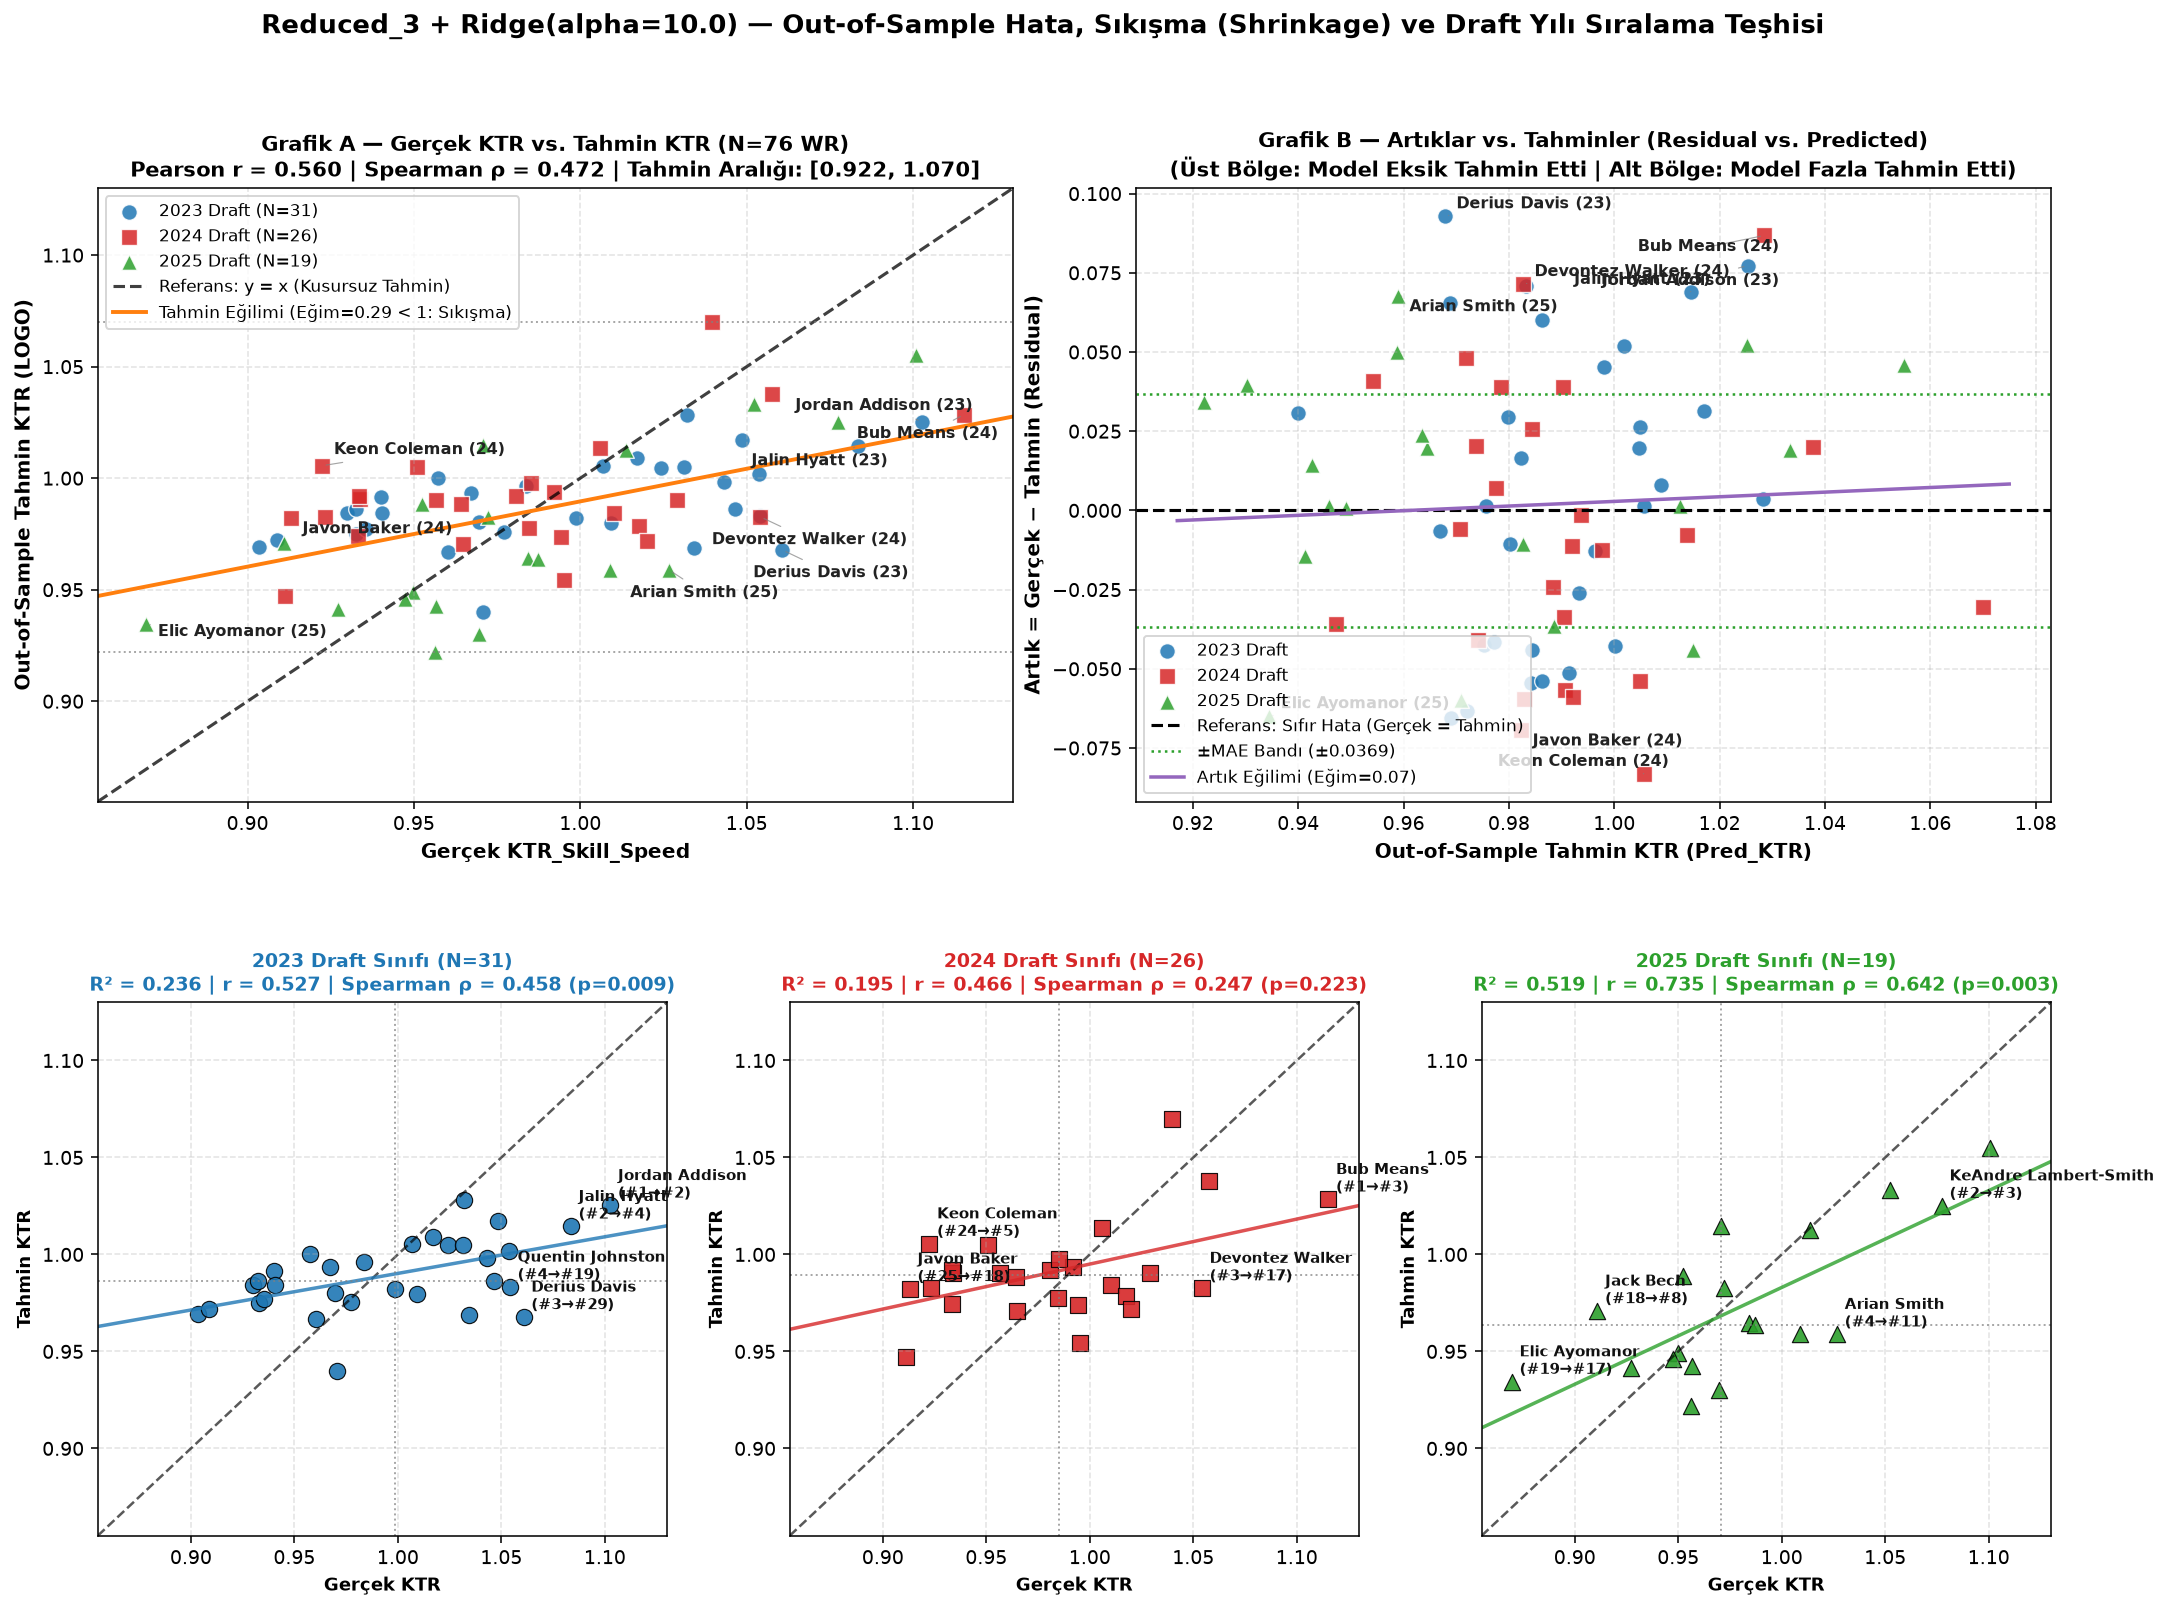

In [18]:
# ==============================================================================
# ADIM 6: GÖRSEL HATA VE SIRALAMA TEŞHİSİ (GRAFİK A: GERÇEK vs TAHMİN, GRAFİK B: ARTIKLAR vs TAHMİN & DRAFT YILI DETAYI)
# ==============================================================================
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

KTR_FEATURES = ["hb_v95", "deep_v95", "hb_cut_speed_retention"]
KTR_ALPHA = 10.0
target = "KTR_Skill_Speed"

plot_df = wr_micro_df[
    ["nfl_id", "display_name", "draft_year", "reg_plays_tracked", target] + KTR_FEATURES
].dropna(subset=[target]).copy().reset_index(drop=True)

X_p = plot_df[KTR_FEATURES]
y_p = plot_df[target]

# Leave-One-Draft-Year-Out (LOGO) Out-of-Sample Tahminleri
logo = LeaveOneGroupOut()
oof_pred_logo = np.zeros(len(plot_df))
for tr_idx, val_idx in logo.split(X_p, y_p, groups=plot_df["draft_year"].values):
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=KTR_ALPHA))
    pipe.fit(X_p.iloc[tr_idx], y_p.iloc[tr_idx])
    oof_pred_logo[val_idx] = pipe.predict(X_p.iloc[val_idx])

plot_df["Pred_KTR"] = oof_pred_logo
plot_df["Residual"] = plot_df[target] - plot_df["Pred_KTR"]
plot_df["Abs_Error"] = plot_df["Residual"].abs()

yr_colors = {2023: "#1f77b4", 2024: "#d62728", 2025: "#2ca02c"}
yr_markers = {2023: "o", 2024: "s", 2025: "^"}

fig = plt.figure(figsize=(18, 12.5), dpi=140)
gs = gridspec.GridSpec(2, 6, height_ratios=[1.15, 1.0], hspace=0.35, wspace=0.55)

# ------------------------------------------------------------------------------
# GRAFİK A (Sol Üst): Gerçek KTR vs. Out-of-Sample Tahmin KTR (Tüm 76 WR)
# ------------------------------------------------------------------------------
ax_a = fig.add_subplot(gs[0, 0:3])
for yr in [2023, 2024, 2025]:
    sub_y = plot_df[plot_df["draft_year"] == yr]
    ax_a.scatter(
        sub_y[target], sub_y["Pred_KTR"],
        c=yr_colors[yr], marker=yr_markers[yr], s=65, alpha=0.85,
        edgecolors="white", linewidth=0.7, label=f"{yr} Draft (N={len(sub_y)})"
    )

# y = x Kusursuz Tahmin Doğrusu
lims = [0.855, 1.13]
ax_a.plot(lims, lims, "k--", lw=1.6, alpha=0.75, label="Referans: y = x (Kusursuz Tahmin)")

# Modelin gerçek eğilim doğrusu (Tahminlerin merkeze sıkışmasını / eğim < 1'i gösterir)
m_fit, b_fit = np.polyfit(plot_df[target], plot_df["Pred_KTR"], 1)
x_line = np.linspace(lims[0], lims[1], 100)
ax_a.plot(x_line, m_fit * x_line + b_fit, color="#ff7f0e", lw=2.0, label=f"Tahmin Eğilimi (Eğim={m_fit:.2f} < 1: Sıkışma)")

# Tahmin bandı sınırları (yatay kesikli çizgiler)
ax_a.axhline(plot_df["Pred_KTR"].max(), color="gray", linestyle=":", lw=1.0, alpha=0.7)
ax_a.axhline(plot_df["Pred_KTR"].min(), color="gray", linestyle=":", lw=1.0, alpha=0.7)

# En büyük sapmalı oyuncuları etiketle
annotate_names = [
    "Derius Davis", "Bub Means", "Keon Coleman", "Jordan Addison",
    "Devontez Walker", "Javon Baker", "Jalin Hyatt", "Elic Ayomanor", "Arian Smith"
]
offsets_a = {
    "Derius Davis": (-15, -14),
    "Bub Means": (-55, -12),
    "Keon Coleman": (6, 6),
    "Jordan Addison": (-65, 6),
    "Devontez Walker": (-25, -14),
    "Javon Baker": (6, -8),
    "Jalin Hyatt": (-55, -10),
    "Elic Ayomanor": (6, -6),
    "Arian Smith": (-20, -14),
}
for _, r in plot_df[plot_df["display_name"].isin(annotate_names)].iterrows():
    dx, dy = offsets_a.get(r["display_name"], (5, 5))
    ax_a.annotate(
        f"{r['display_name']} ({int(r['draft_year'])%100})",
        (r[target], r["Pred_KTR"]),
        xytext=(dx, dy), textcoords="offset points",
        fontsize=8.2, fontweight="bold", color="#222222",
        arrowprops=dict(arrowstyle="-", color="gray", lw=0.6, alpha=0.7)
    )

r_all, _ = pearsonr(plot_df[target], plot_df["Pred_KTR"])
rho_all, _ = spearmanr(plot_df[target], plot_df["Pred_KTR"])
ax_a.set_xlim(lims)
ax_a.set_ylim(lims)
ax_a.set_xlabel("Gerçek KTR_Skill_Speed", fontsize=10.5, fontweight="bold")
ax_a.set_ylabel("Out-of-Sample Tahmin KTR (LOGO)", fontsize=10.5, fontweight="bold")
ax_a.set_title(
    f"Grafik A — Gerçek KTR vs. Tahmin KTR (N=76 WR)\n"
    f"Pearson r = {r_all:.3f} | Spearman ρ = {rho_all:.3f} | Tahmin Aralığı: [{plot_df['Pred_KTR'].min():.3f}, {plot_df['Pred_KTR'].max():.3f}]",
    fontsize=11, fontweight="bold"
)
ax_a.legend(loc="upper left", fontsize=8.5, frameon=True)
ax_a.grid(True, linestyle="--", alpha=0.35)

# ------------------------------------------------------------------------------
# GRAFİK B (Sağ Üst): Artıklar (Gerçek - Tahmin) vs. Tahmin KTR
# ------------------------------------------------------------------------------
ax_b = fig.add_subplot(gs[0, 3:6])
for yr in [2023, 2024, 2025]:
    sub_y = plot_df[plot_df["draft_year"] == yr]
    ax_b.scatter(
        sub_y["Pred_KTR"], sub_y["Residual"],
        c=yr_colors[yr], marker=yr_markers[yr], s=65, alpha=0.85,
        edgecolors="white", linewidth=0.7, label=f"{yr} Draft"
    )

mae_val = plot_df["Abs_Error"].mean()
ax_b.axhline(0.0, color="black", linestyle="--", lw=1.6, label="Referans: Sıfır Hata (Gerçek = Tahmin)")
ax_b.axhline(mae_val, color="#2ca02c", linestyle=":", lw=1.3, label=f"±MAE Bandı (±{mae_val:.4f})")
ax_b.axhline(-mae_val, color="#2ca02c", linestyle=":", lw=1.3)

# Artık eğilimi (Tahmin büyüklüğüne göre sistematik yanlılık var mı?)
m_res, b_res = np.polyfit(plot_df["Pred_KTR"], plot_df["Residual"], 1)
x_pred_line = np.linspace(plot_df["Pred_KTR"].min() - 0.005, plot_df["Pred_KTR"].max() + 0.005, 100)
ax_b.plot(x_pred_line, m_res * x_pred_line + b_res, color="#9467bd", lw=1.8, label=f"Artık Eğilimi (Eğim={m_res:.2f})")

offsets_b = {
    "Derius Davis": (6, 4),
    "Bub Means": (-65, -8),
    "Keon Coleman": (-75, 4),
    "Jordan Addison": (-75, -10),
    "Devontez Walker": (6, 4),
    "Javon Baker": (6, -8),
    "Jalin Hyatt": (-60, 4),
    "Elic Ayomanor": (6, 4),
    "Arian Smith": (6, -8),
}
for _, r in plot_df[plot_df["display_name"].isin(annotate_names)].iterrows():
    dx, dy = offsets_b.get(r["display_name"], (5, 5))
    ax_b.annotate(
        f"{r['display_name']} ({int(r['draft_year'])%100})",
        (r["Pred_KTR"], r["Residual"]),
        xytext=(dx, dy), textcoords="offset points",
        fontsize=8.2, fontweight="bold", color="#222222",
        arrowprops=dict(arrowstyle="-", color="gray", lw=0.6, alpha=0.7)
    )

ax_b.set_xlabel("Out-of-Sample Tahmin KTR (Pred_KTR)", fontsize=10.5, fontweight="bold")
ax_b.set_ylabel("Artık = Gerçek − Tahmin (Residual)", fontsize=10.5, fontweight="bold")
ax_b.set_title(
    "Grafik B — Artıklar vs. Tahminler (Residual vs. Predicted)\n"
    "(Üst Bölge: Model Eksik Tahmin Etti | Alt Bölge: Model Fazla Tahmin Etti)",
    fontsize=11, fontweight="bold"
)
ax_b.legend(loc="lower left", fontsize=8.5, frameon=True)
ax_b.grid(True, linestyle="--", alpha=0.35)

# ------------------------------------------------------------------------------
# ALT SATIR: Draft Yılı Bazında Ayrı Paneller (2023, 2024 ve 2025) & Sıralama İncelemesi
# ------------------------------------------------------------------------------
for idx, yr in enumerate([2023, 2024, 2025]):
    ax_yr = fig.add_subplot(gs[1, idx*2:(idx+1)*2])
    sub_y = plot_df[plot_df["draft_year"] == yr].copy()
    
    # Sınıf içi sıralama farkı
    sub_y["Yr_Actual_Rank"] = sub_y[target].rank(ascending=False).astype(int)
    sub_y["Yr_Pred_Rank"] = sub_y["Pred_KTR"].rank(ascending=False).astype(int)
    sub_y["Yr_Rank_Diff"] = (sub_y["Yr_Actual_Rank"] - sub_y["Yr_Pred_Rank"]).abs()
    
    ax_yr.scatter(
        sub_y[target], sub_y["Pred_KTR"],
        c=yr_colors[yr], marker=yr_markers[yr], s=70, alpha=0.9,
        edgecolors="black", linewidth=0.6
    )
    ax_yr.plot(lims, lims, "k--", lw=1.3, alpha=0.65, label="y = x")
    
    # Yıl içi regresyon eğilimi
    m_y, b_y = np.polyfit(sub_y[target], sub_y["Pred_KTR"], 1)
    ax_yr.plot(x_line, m_y * x_line + b_y, color=yr_colors[yr], lw=1.8, linestyle="-", alpha=0.8)
    
    # Medyan çizgileri (Sıralama / Kadran ayrımı)
    ax_yr.axvline(sub_y[target].median(), color="gray", linestyle=":", lw=1.0, alpha=0.7)
    ax_yr.axhline(sub_y["Pred_KTR"].median(), color="gray", linestyle=":", lw=1.0, alpha=0.7)
    
    # Her yıldaki en büyük 4 hatayı etiketle
    top_yr_err = sub_y.nlargest(4, "Abs_Error")
    for _, r in top_yr_err.iterrows():
        ax_yr.annotate(
            f"{r['display_name']}\n(#{r['Yr_Actual_Rank']}→#{r['Yr_Pred_Rank']})",
            (r[target], r["Pred_KTR"]),
            xytext=(4, 4), textcoords="offset points",
            fontsize=7.5, fontweight="bold", color="#111111"
        )
        
    r_y, _ = pearsonr(sub_y[target], sub_y["Pred_KTR"])
    rho_y, p_rho_y = spearmanr(sub_y[target], sub_y["Pred_KTR"])
    r2_y = r2_score(sub_y[target], sub_y["Pred_KTR"])
    
    ax_yr.set_xlim(lims)
    ax_yr.set_ylim(lims)
    ax_yr.set_xlabel("Gerçek KTR", fontsize=9.5, fontweight="bold")
    ax_yr.set_ylabel("Tahmin KTR", fontsize=9.5, fontweight="bold")
    ax_yr.set_title(
        f"{yr} Draft Sınıfı (N={len(sub_y)})\n"
        f"R² = {r2_y:.3f} | r = {r_y:.3f} | Spearman ρ = {rho_y:.3f} (p={p_rho_y:.3f})",
        fontsize=10, fontweight="bold", color=yr_colors[yr]
    )
    ax_yr.grid(True, linestyle="--", alpha=0.35)

fig.suptitle(
    "Reduced_3 + Ridge(alpha=10.0) — Out-of-Sample Hata, Sıkışma (Shrinkage) ve Draft Yılı Sıralama Teşhisi",
    fontsize=13.5, fontweight="bold", y=0.98
)
fig_path = Path("data_cache/figures/ktr_reduced3_error_diagnostics.png")
plt.savefig(fig_path, bbox_inches="tight", dpi=140)
plt.show()
print(f"Grafik kaydedildi: {fig_path}")

# 2024 Sınıfı Özel Teşhis Tablosu: Neden R²=0.195 (r=0.466) iken Spearman ρ=0.247?
sub_2024 = plot_df[plot_df["draft_year"] == 2024].copy()
sub_2024["Sınıf_İçi_Gerçek_Sıra"] = sub_2024[target].rank(ascending=False, method="min").astype(int)
sub_2024["Sınıf_İçi_Tahmin_Sıra"] = sub_2024["Pred_KTR"].rank(ascending=False, method="min").astype(int)
sub_2024["Sıra_Sapması"] = (sub_2024["Sınıf_İçi_Gerçek_Sıra"] - sub_2024["Sınıf_İçi_Tahmin_Sıra"]).abs()

print("\n=== 2024 DRAFT SINIFI (N=26) SIRALAMA BOZULMASI DETAYI (EN BÜYÜK SIRA SAPMALI 8 OYUNCU) ===")
display(sub_2024.sort_values("Sıra_Sapması", ascending=False).head(8)[[
    "display_name", "hb_v95", "deep_v95", "hb_cut_speed_retention",
    target, "Pred_KTR", "Residual", "Sınıf_İçi_Gerçek_Sıra", "Sınıf_İçi_Tahmin_Sıra", "Sıra_Sapması"
]].round(4))


In [19]:
# ==============================================================================
# ADIM 7: RIDGE vs. RANDOM FOREST vs. GRADIENT BOOSTING KARŞILAŞTIRMASI (LOGO & 5-FOLD CV & 2024 DETAYI)
# ==============================================================================
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error
from sklearn.model_selection import LeaveOneGroupOut, KFold
from scipy.stats import spearmanr, pearsonr

KTR_FEATURES = ["hb_v95", "deep_v95", "hb_cut_speed_retention"]
target = "KTR_Skill_Speed"

comp_df = wr_micro_df[
    ["nfl_id", "display_name", "draft_year", "reg_plays_tracked", target] + KTR_FEATURES
].dropna(subset=[target]).copy().reset_index(drop=True)

X_c = comp_df[KTR_FEATURES]
y_c = comp_df[target]
groups_c = comp_df["draft_year"].values

def get_models():
    return {
        "Ridge (alpha=10.0)": make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            Ridge(alpha=10.0)
        ),
        "RandomForest (depth=3, leaf=5)": make_pipeline(
            SimpleImputer(strategy="median"),
            RandomForestRegressor(max_depth=3, min_samples_leaf=5, n_estimators=100, random_state=42)
        ),
        "GradientBoosting (depth=2, lr=0.03, leaf=5)": make_pipeline(
            SimpleImputer(strategy="median"),
            GradientBoostingRegressor(max_depth=2, n_estimators=100, learning_rate=0.03, min_samples_leaf=5, random_state=42)
        ),
    }

def top25_hit_rate(y_true_s, y_pred_s):
    k = max(1, int(round(len(y_true_s) * 0.25)))
    top_true = set(pd.Series(y_true_s).nlargest(k).index)
    top_pred = set(pd.Series(y_pred_s, index=pd.Series(y_true_s).index).nlargest(k).index)
    return len(top_true & top_pred) / k * 100.0

# ------------------------------------------------------------------------------
# 1. LEAVE-ONE-DRAFT-YEAR-OUT (2023, 2024, 2025 SIRAYLA DIŞARIDA BIRAKARAK TEST)
# ------------------------------------------------------------------------------
logo = LeaveOneGroupOut()
logo_summary_rows = []
logo_year_rows = []
oof_logo_preds = {}

for m_name, _ in get_models().items():
    oof_preds = np.zeros(len(comp_df))
    tr_r2_list, val_r2_list, val_rmse_list, val_mae_list, yr_rho_list, yr_top25_list = [], [], [], [], [], []
    
    for tr_idx, val_idx in logo.split(X_c, y_c, groups=groups_c):
        yr = int(comp_df.iloc[val_idx]["draft_year"].iloc[0])
        model = get_models()[m_name]
        model.fit(X_c.iloc[tr_idx], y_c.iloc[tr_idx])
        
        p_tr = model.predict(X_c.iloc[tr_idx])
        p_val = model.predict(X_c.iloc[val_idx])
        oof_preds[val_idx] = p_val
        
        tr_r2 = r2_score(y_c.iloc[tr_idx], p_tr)
        val_r2 = r2_score(y_c.iloc[val_idx], p_val)
        val_rmse = root_mean_squared_error(y_c.iloc[val_idx], p_val)
        val_mae = mean_absolute_error(y_c.iloc[val_idx], p_val)
        rho_yr, p_rho_yr = spearmanr(y_c.iloc[val_idx], p_val)
        top25_yr = top25_hit_rate(y_c.iloc[val_idx], p_val)
        
        tr_r2_list.append(tr_r2)
        val_r2_list.append(val_r2)
        val_rmse_list.append(val_rmse)
        val_mae_list.append(val_mae)
        yr_rho_list.append(rho_yr)
        yr_top25_list.append(top25_yr)
        
        logo_year_rows.append({
            "Model": m_name,
            "Test_Yılı": yr,
            "N": len(val_idx),
            "Train_R2": round(tr_r2, 3),
            "Val_R2": round(val_r2, 3),
            "R2_Farkı": round(tr_r2 - val_r2, 3),
            "Val_RMSE": round(val_rmse, 4),
            "Val_MAE": round(val_mae, 4),
            "Spearman_rho": round(rho_yr, 3),
            "Spearman_p": round(p_rho_yr, 4),
            "Üst_%25_Yakalama_%": round(top25_yr, 1),
        })
        
    oof_logo_preds[m_name] = oof_preds
    pooled_rho, _ = spearmanr(y_c, oof_preds)
    pooled_top25 = top25_hit_rate(y_c, oof_preds)
    
    logo_summary_rows.append({
        "Model": m_name,
        "Train_R2_Ort": round(np.mean(tr_r2_list), 3),
        "Val_R2_Ort": round(np.mean(val_r2_list), 3),
        "R2_Farkı (Train-Val)": round(np.mean(tr_r2_list) - np.mean(val_r2_list), 3),
        "Val_R2_Std": round(np.std(val_r2_list, ddof=1), 3),
        "Val_RMSE_Ort": round(np.mean(val_rmse_list), 4),
        "Val_MAE_Ort": round(np.mean(val_mae_list), 4),
        "Yıl_Spearman_Ort": round(np.mean(yr_rho_list), 3),
        "Genel_OOF_Spearman": round(pooled_rho, 3),
        "Genel_Üst_%25_Yakalama_%": round(pooled_top25, 1),
    })

print("=== 1.A: LEAVE-ONE-DRAFT-YEAR-OUT (2023, 2024, 2025) GENEL ÖZET TABLOSU ===")
display(pd.DataFrame(logo_summary_rows))

print("\n=== 1.B: LEAVE-ONE-DRAFT-YEAR-OUT YIL BAZLI DETAY TABLOSU (2023, 2024, 2025) ===")
display(pd.DataFrame(logo_year_rows))

# ------------------------------------------------------------------------------
# 2. 5-FOLD CV (KFold n_splits=5, shuffle=True, random_state=42) KARŞILAŞTIRMASI
# ------------------------------------------------------------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)
kf_summary_rows = []
kf_fold_rows = []

for m_name, _ in get_models().items():
    oof_kf = np.zeros(len(comp_df))
    tr_r2_l, val_r2_l, val_rmse_l, val_mae_l, fold_rho_l = [], [], [], [], []
    
    for f_i, (tr_idx, val_idx) in enumerate(kf.split(X_c, y_c), start=1):
        model = get_models()[m_name]
        model.fit(X_c.iloc[tr_idx], y_c.iloc[tr_idx])
        
        p_tr = model.predict(X_c.iloc[tr_idx])
        p_val = model.predict(X_c.iloc[val_idx])
        oof_kf[val_idx] = p_val
        
        tr_r2 = r2_score(y_c.iloc[tr_idx], p_tr)
        val_r2 = r2_score(y_c.iloc[val_idx], p_val)
        val_rmse = root_mean_squared_error(y_c.iloc[val_idx], p_val)
        val_mae = mean_absolute_error(y_c.iloc[val_idx], p_val)
        rho_f, _ = spearmanr(y_c.iloc[val_idx], p_val)
        
        tr_r2_l.append(tr_r2)
        val_r2_l.append(val_r2)
        val_rmse_l.append(val_rmse)
        val_mae_l.append(val_mae)
        fold_rho_l.append(rho_f)
        
    oof_rho_kf, _ = spearmanr(y_c, oof_kf)
    oof_top25_kf = top25_hit_rate(y_c, oof_kf)
    
    kf_summary_rows.append({
        "Model": m_name,
        "Train_R2_Ort": round(np.mean(tr_r2_l), 3),
        "Val_R2_Ort": round(np.mean(val_r2_l), 3),
        "R2_Farkı (Train-Val)": round(np.mean(tr_r2_l) - np.mean(val_r2_l), 3),
        "Val_R2_Std": round(np.std(val_r2_l, ddof=1), 3),
        "Val_RMSE_Ort": round(np.mean(val_rmse_l), 4),
        "Val_MAE_Ort": round(np.mean(val_mae_l), 4),
        "Fold_Spearman_Ort": round(np.mean(fold_rho_l), 3),
        "Genel_OOF_Spearman": round(oof_rho_kf, 3),
        "Genel_Üst_%25_Yakalama_%": round(oof_top25_kf, 1),
    })
    kf_fold_rows.append({
        "Model": m_name,
        "F1_R2": round(val_r2_l[0], 3),
        "F2_R2": round(val_r2_l[1], 3),
        "F3_R2": round(val_r2_l[2], 3),
        "F4_R2": round(val_r2_l[3], 3),
        "F5_R2": round(val_r2_l[4], 3),
        "F1_rho": round(fold_rho_l[0], 3),
        "F2_rho": round(fold_rho_l[1], 3),
        "F3_rho": round(fold_rho_l[2], 3),
        "F4_rho": round(fold_rho_l[3], 3),
        "F5_rho": round(fold_rho_l[4], 3),
    })

print("\n=== 2.A: 5-FOLD CV GENEL ÖZET TABLOSU ===")
display(pd.DataFrame(kf_summary_rows))

print("\n=== 2.B: 5-FOLD CV FOLD BAZLI R² VE SPEARMAN ρ DAĞILIMI ===")
display(pd.DataFrame(kf_fold_rows))

# ------------------------------------------------------------------------------
# 3. 2024 DRAFT SINIFI OYUNCU BAZLI KARŞILAŞTIRMA (KEON COLEMAN, JERMAINE BURTON, TROY FRANKLIN, DEVONTEZ WALKER VB.)
# ------------------------------------------------------------------------------
comp_df["Pred_Ridge"] = oof_logo_preds["Ridge (alpha=10.0)"]
comp_df["Pred_RF"] = oof_logo_preds["RandomForest (depth=3, leaf=5)"]
comp_df["Pred_GB"] = oof_logo_preds["GradientBoosting (depth=2, lr=0.03, leaf=5)"]

sub_24 = comp_df[comp_df["draft_year"] == 2024].copy()
sub_24["Gerçek_Sıra"] = sub_24[target].rank(ascending=False, method="min").astype(int)
sub_24["Ridge_Sıra"] = sub_24["Pred_Ridge"].rank(ascending=False, method="min").astype(int)
sub_24["RF_Sıra"] = sub_24["Pred_RF"].rank(ascending=False, method="min").astype(int)
sub_24["GB_Sıra"] = sub_24["Pred_GB"].rank(ascending=False, method="min").astype(int)

sub_24["Ridge_Sıra_Fark"] = (sub_24["Gerçek_Sıra"] - sub_24["Ridge_Sıra"]).abs()
sub_24["RF_Sıra_Fark"] = (sub_24["Gerçek_Sıra"] - sub_24["RF_Sıra"]).abs()
sub_24["GB_Sıra_Fark"] = (sub_24["Gerçek_Sıra"] - sub_24["GB_Sıra"]).abs()

focus_players_2024 = [
    "Keon Coleman", "Jermaine Burton", "Troy Franklin", "Devontez Walker",
    "Isaiah Williams", "Ja'Lynn Polk", "Ryan Flournoy", "Roman Wilson", "Bub Means"
]
print("\n=== 3. 2024 DRAFT SINIFI KRİTİK OYUNCULARIN TAHMİN VE SIRALAMA KARŞILAŞTIRMASI (N=26 İÇİNDE) ===")
display(sub_24[sub_24["display_name"].isin(focus_players_2024)].sort_values("Gerçek_Sıra")[[
    "display_name", "hb_v95", "deep_v95", "hb_cut_speed_retention",
    target, "Gerçek_Sıra",
    "Pred_Ridge", "Ridge_Sıra", "Ridge_Sıra_Fark",
    "Pred_RF", "RF_Sıra", "RF_Sıra_Fark",
    "Pred_GB", "GB_Sıra", "GB_Sıra_Fark"
]].round(4))


=== 1.A: LEAVE-ONE-DRAFT-YEAR-OUT (2023, 2024, 2025) GENEL ÖZET TABLOSU ===
                                      Model  Train_R2_Ort  Val_R2_Ort  R2_Farkı (Train-Val)  Val_R2_Std  Val_RMSE_Ort  Val_MAE_Ort  Yıl_Spearman_Ort  Genel_OOF_Spearman  Genel_Üst_%25_Yakalama_%
                         Ridge (alpha=10.0)         0.345       0.317                 0.028       0.177        0.0430       0.0362             0.449               0.472                      57.9
             RandomForest (depth=3, leaf=5)         0.555       0.280                 0.275       0.170        0.0442       0.0361             0.418               0.458                      63.2
GradientBoosting (depth=2, lr=0.03, leaf=5)         0.628       0.262                 0.366       0.187        0.0448       0.0370             0.399               0.433                      68.4

=== 1.B: LEAVE-ONE-DRAFT-YEAR-OUT YIL BAZLI DETAY TABLOSU (2023, 2024, 2025) ===
                                      Model  Test_Yılı  N  Tra

=== BÖLÜM 1: PAYDA ETKİSİ (KTR_Skill_Speed = nfl_v95 / s2_v95) TEŞHİSİ ===
                                     Bileşen İlişkisi  Pearson_r  Varyans_Payı_R2                                                                           Mekanizma
KTR_Skill_Speed vs. s2_v95 (Payda: Combine Rota Hızı)     -0.686            0.471 Payda büyüdükçe KTR oranı matematiksel olarak küçülür (hb_v95, deep_v95 bunu ölçer)
      KTR_Skill_Speed vs. nfl_v95 (Pay: NFL Maç Hızı)      0.629            0.396   Pay büyüdükçe KTR oranı büyür (40-yard hız tavanı 'forty' bunu ölçer: r = -0.525)

2024 Draft Sınıfı Kritik Oyuncularında Pay+Payda Modeliyle Sıralama İyileşmesi (N=26 içinde):
   display_name  forty  hb_v95  deep_v95  nfl_v95  KTR_Skill_Speed  Gerçek_Sıra  Reduced3_Sıra  Balanced3_Sıra  Balanced4_Sıra
      Bub Means   4.43   8.060    10.060    9.327            1.115            1              3               3               3
Devontez Walker   4.36   8.786    10.253    9.746            1.054            

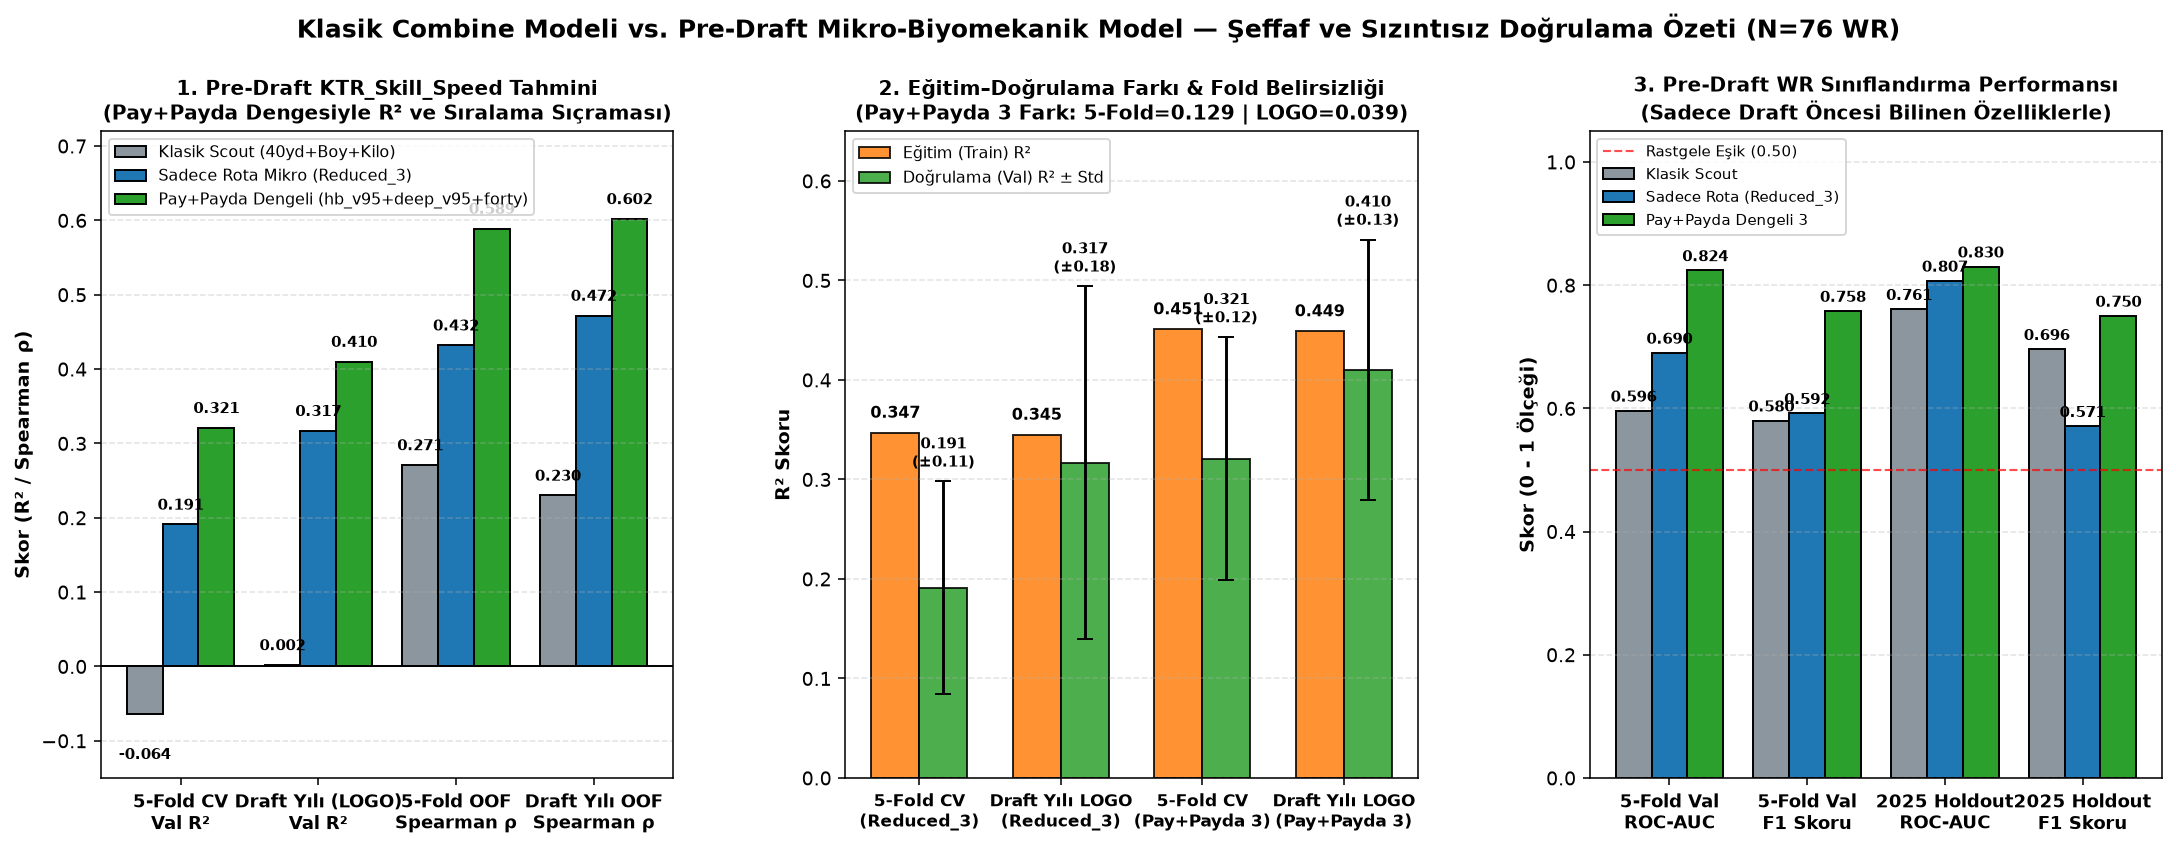

In [20]:
# ==============================================================================
# ADIM 8: ÜÇ AŞAMALI NİHAİ DOĞRULAMA PAKETİ (JÜRİ & KAGGLE FİNAL SÜRÜMÜ)
#   1) Payda Etkisi (Denominator Coupling) Teşhisi ve Pay+Payda Dengeli Çözümü
#   2) Klasik Scout Modeli vs. Sadece Rota Modeli (Reduced_3) vs. Pay+Payda Birleşik Pre-Draft Model
#   3) Nihai Şeffaf Karşılaştırma Grafiği (max() düzeltmesiz, Train-Val farkı ve belirsizlik barlarıyla)
# ==============================================================================
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.model_selection import KFold, StratifiedKFold, LeaveOneGroupOut
from sklearn.metrics import (
    r2_score, root_mean_squared_error, mean_absolute_error,
    roc_auc_score, accuracy_score, f1_score, precision_score, recall_score
)
from scipy.stats import pearsonr, spearmanr

CLASSICAL_FEATURES = ["forty", "combine_height", "combine_weight"]
REDUCED_3_FEATURES = ["hb_v95", "deep_v95", "hb_cut_speed_retention"]
BALANCED_3_FEATURES = ["hb_v95", "deep_v95", "forty"]
BALANCED_4_FEATURES = ["hb_v95", "deep_v95", "hb_cut_speed_retention", "forty"]
TORSO_MICRO_FEATURES = ["forty_vmax", "deep_v95", "s2_centripetal95"]

df_w = wr_micro_df.dropna(subset=["KTR_Skill_Speed", "nfl_v95", "s2_v95"]).copy().reset_index(drop=True)

# ------------------------------------------------------------------------------
# BÖLÜM 1: PAYDA ETKİSİ (DENOMINATOR COUPLING) TEŞHİSİ VE 2024 SIRALAMA ÇÖZÜMÜ
# ------------------------------------------------------------------------------
print("=== BÖLÜM 1: PAYDA ETKİSİ (KTR_Skill_Speed = nfl_v95 / s2_v95) TEŞHİSİ ===")
r_ktr_denom, _ = pearsonr(df_w["KTR_Skill_Speed"], df_w["s2_v95"])
r_ktr_num, _ = pearsonr(df_w["KTR_Skill_Speed"], df_w["nfl_v95"])

denom_diag = pd.DataFrame([
    {"Bileşen İlişkisi": "KTR_Skill_Speed vs. s2_v95 (Payda: Combine Rota Hızı)", "Pearson_r": round(r_ktr_denom, 3), "Varyans_Payı_R2": round(r_ktr_denom**2, 3), "Mekanizma": "Payda büyüdükçe KTR oranı matematiksel olarak küçülür (hb_v95, deep_v95 bunu ölçer)"},
    {"Bileşen İlişkisi": "KTR_Skill_Speed vs. nfl_v95 (Pay: NFL Maç Hızı)", "Pearson_r": round(r_ktr_num, 3), "Varyans_Payı_R2": round(r_ktr_num**2, 3), "Mekanizma": "Pay büyüdükçe KTR oranı büyür (40-yard hız tavanı 'forty' bunu ölçer: r = -0.525)"},
])
display(denom_diag)

# 2024 Sınıfında Keon Coleman & Devontez Walker & Jermaine Burton Sıralama Düzeltmesi
logo = LeaveOneGroupOut()
for col_name, f_cols in [
    ("Pred_Reduced3", REDUCED_3_FEATURES),
    ("Pred_Balanced3 (hb_v95+deep_v95+forty)", BALANCED_3_FEATURES),
    ("Pred_Balanced4 (+hb_cut_ret)", BALANCED_4_FEATURES),
]:
    oof_p = np.zeros(len(df_w))
    for tr_i, val_i in logo.split(df_w[f_cols], df_w["KTR_Skill_Speed"], groups=df_w["draft_year"].values):
        pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10.0))
        pipe.fit(df_w[f_cols].iloc[tr_i], df_w["KTR_Skill_Speed"].iloc[tr_i])
        oof_p[val_i] = pipe.predict(df_w[f_cols].iloc[val_i])
    df_w[col_name] = oof_p

sub24 = df_w[df_w["draft_year"] == 2024].copy()
sub24["Gerçek_Sıra"] = sub24["KTR_Skill_Speed"].rank(ascending=False, method="min").astype(int)
sub24["Reduced3_Sıra"] = sub24["Pred_Reduced3"].rank(ascending=False, method="min").astype(int)
sub24["Balanced3_Sıra"] = sub24["Pred_Balanced3 (hb_v95+deep_v95+forty)"].rank(ascending=False, method="min").astype(int)
sub24["Balanced4_Sıra"] = sub24["Pred_Balanced4 (+hb_cut_ret)"].rank(ascending=False, method="min").astype(int)

print("\n2024 Draft Sınıfı Kritik Oyuncularında Pay+Payda Modeliyle Sıralama İyileşmesi (N=26 içinde):")
focus_24 = ["Bub Means", "Devontez Walker", "Jermaine Burton", "Ja'Lynn Polk", "Troy Franklin", "Isaiah Williams", "Ryan Flournoy", "Keon Coleman"]
display(sub24[sub24["display_name"].isin(focus_24)].sort_values("Gerçek_Sıra")[[
    "display_name", "forty", "hb_v95", "deep_v95", "nfl_v95", "KTR_Skill_Speed",
    "Gerçek_Sıra", "Reduced3_Sıra", "Balanced3_Sıra", "Balanced4_Sıra"
]].round(3))

# ------------------------------------------------------------------------------
# BÖLÜM 2: TÜM REGRESYON VE SINIFLANDIRMA GÖREVLERİNDE SIZINTISIZ KARŞILAŞTIRMA
# ------------------------------------------------------------------------------
kf5 = KFold(n_splits=5, shuffle=True, random_state=42)

def eval_reg_task(df_in, target_col, feat_cols, model_label, task_label, alpha_val=10.0):
    sub_t = df_in.dropna(subset=[target_col]).copy().reset_index(drop=True)
    X_t = sub_t[feat_cols]
    y_t = sub_t[target_col]
    groups_t = sub_t["draft_year"].values
    
    tr_r2_kf, val_r2_kf, val_rmse_kf, val_mae_kf = [], [], [], []
    oof_kf = np.zeros(len(sub_t))
    for tr_i, val_i in kf5.split(X_t, y_t):
        pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=alpha_val))
        pipe.fit(X_t.iloc[tr_i], y_t.iloc[tr_i])
        p_tr = pipe.predict(X_t.iloc[tr_i])
        p_val = pipe.predict(X_t.iloc[val_i])
        oof_kf[val_i] = p_val
        tr_r2_kf.append(r2_score(y_t.iloc[tr_i], p_tr))
        val_r2_kf.append(r2_score(y_t.iloc[val_i], p_val))
        val_rmse_kf.append(root_mean_squared_error(y_t.iloc[val_i], p_val))
        val_mae_kf.append(mean_absolute_error(y_t.iloc[val_i], p_val))
    rho_kf, _ = spearmanr(y_t, oof_kf)
    
    tr_r2_lg, val_r2_lg = [], []
    oof_lg = np.zeros(len(sub_t))
    yr_r2_map, yr_rho_map = {}, {}
    for tr_i, val_i in logo.split(X_t, y_t, groups=groups_t):
        yr = int(sub_t.iloc[val_i]["draft_year"].iloc[0])
        pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=alpha_val))
        pipe.fit(X_t.iloc[tr_i], y_t.iloc[tr_i])
        p_tr = pipe.predict(X_t.iloc[tr_i])
        p_val = pipe.predict(X_t.iloc[val_i])
        oof_lg[val_i] = p_val
        tr_r2_lg.append(r2_score(y_t.iloc[tr_i], p_tr))
        val_r2_lg.append(r2_score(y_t.iloc[val_i], p_val))
        yr_r2_map[yr] = r2_score(y_t.iloc[val_i], p_val)
        yr_rho_map[yr] = spearmanr(y_t.iloc[val_i], p_val)[0]
    rho_lg, _ = spearmanr(y_t, oof_lg)
    
    return {
        "Görev": task_label,
        "Model": model_label,
        "5Fold_Train_R2": round(np.mean(tr_r2_kf), 3),
        "5Fold_Val_R2": round(np.mean(val_r2_kf), 3),
        "5Fold_R2_Farkı": round(np.mean(tr_r2_kf) - np.mean(val_r2_kf), 3),
        "5Fold_Val_Std": round(np.std(val_r2_kf, ddof=1), 3),
        "5Fold_RMSE": round(np.mean(val_rmse_kf), 4),
        "5Fold_Spearman": round(rho_kf, 3),
        "LOGO_Train_R2": round(np.mean(tr_r2_lg), 3),
        "LOGO_Val_R2": round(np.mean(val_r2_lg), 3),
        "LOGO_R2_Farkı": round(np.mean(tr_r2_lg) - np.mean(val_r2_lg), 3),
        "2023_R2 (ρ)": f"{yr_r2_map[2023]:.3f} ({yr_rho_map[2023]:.2f})",
        "2024_R2 (ρ)": f"{yr_r2_map[2024]:.3f} ({yr_rho_map[2024]:.2f})",
        "2025_R2 (ρ)": f"{yr_r2_map[2025]:.3f} ({yr_rho_map[2025]:.2f})",
        "LOGO_Genel_Spearman": round(rho_lg, 3),
        "_2025_r2_num": round(yr_r2_map[2025], 3),
        "_logo_std_num": round(np.std(val_r2_lg, ddof=1), 3),
    }

reg_comp_rows = [
    eval_reg_task(df_w, "KTR_Skill_Speed", CLASSICAL_FEATURES, "1a. Klasik Scout (40yd + Boy + Kilo)", "KTR_Skill_Speed"),
    eval_reg_task(df_w, "KTR_Skill_Speed", REDUCED_3_FEATURES, "1b. Sadece Rota Mikro (hb_v95 + deep_v95 + hb_cut_ret)", "KTR_Skill_Speed"),
    eval_reg_task(df_w, "KTR_Skill_Speed", BALANCED_3_FEATURES, "1c. Pay+Payda Dengeli 3 (hb_v95 + deep_v95 + forty)", "KTR_Skill_Speed"),
    eval_reg_task(df_w, "KTR_Skill_Speed", BALANCED_4_FEATURES, "1d. Pay+Payda Dengeli 4 (Reduced_3 + forty)", "KTR_Skill_Speed"),
    eval_reg_task(df_w, "Torso_Dissoc_Efficiency", CLASSICAL_FEATURES, "2a. Klasik Scout (40yd + Boy + Kilo)", "Torso_Dissoc_Eff"),
    eval_reg_task(df_w, "Torso_Dissoc_Efficiency", TORSO_MICRO_FEATURES, "2b. Combine Sensör Mikro (forty_vmax + deep_v95 + centripetal)", "Torso_Dissoc_Eff"),
]
reg_comp_df = pd.DataFrame(reg_comp_rows)
display_cols_reg = [c for c in reg_comp_df.columns if not c.startswith("_")]
print("\n=== BÖLÜM 2.A: REGRESYON GÖREVLERİNDE SIZINTISIZ PERFORMANS TABLOSU (5-FOLD CV & DRAFT YILI LOGO-CV) ===")
display(reg_comp_df[display_cols_reg])

# Sınıflandırma Karşılaştırması
ktr_med = df_w["KTR_Skill_Speed"].median()
df_w["Is_High_KTR_Gamer"] = (df_w["KTR_Skill_Speed"] >= ktr_med).astype(int)
skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def eval_clf_task(df_in, y_col, feat_cols, model_label):
    X_t = df_in[feat_cols]
    y_t = df_in[y_col].values
    
    tr_aucs, val_aucs, val_accs, val_f1s, val_precs, val_recs = [], [], [], [], [], []
    for tr_i, val_i in skf5.split(X_t, y_t):
        pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=0.2, random_state=42))
        pipe.fit(X_t.iloc[tr_i], y_t[tr_i])
        prob_tr = pipe.predict_proba(X_t.iloc[tr_i])[:, 1]
        prob_val = pipe.predict_proba(X_t.iloc[val_i])[:, 1]
        pred_val = (prob_val >= 0.5).astype(int)
        
        tr_aucs.append(roc_auc_score(y_t[tr_i], prob_tr))
        val_aucs.append(roc_auc_score(y_t[val_i], prob_val))
        val_accs.append(accuracy_score(y_t[val_i], pred_val))
        val_f1s.append(f1_score(y_t[val_i], pred_val, zero_division=0))
        val_precs.append(precision_score(y_t[val_i], pred_val, zero_division=0))
        val_recs.append(recall_score(y_t[val_i], pred_val, zero_division=0))
        
    tr_m = df_in["draft_year"].isin([2023, 2024])
    te_m = df_in["draft_year"] == 2025
    pipe_h = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=0.2, random_state=42))
    pipe_h.fit(X_t.loc[tr_m], y_t[tr_m])
    prob_25 = pipe_h.predict_proba(X_t.loc[te_m])[:, 1]
    pred_25 = (prob_25 >= 0.5).astype(int)
    
    return {
        "Model": model_label,
        "5Fold_Train_AUC": round(np.mean(tr_aucs), 3),
        "5Fold_Val_AUC": round(np.mean(val_aucs), 3),
        "AUC_Farkı": round(np.mean(tr_aucs) - np.mean(val_aucs), 3),
        "Val_AUC_Std": round(np.std(val_aucs, ddof=1), 3),
        "5Fold_Acc_%": round(np.mean(val_accs) * 100, 1),
        "5Fold_F1": round(np.mean(val_f1s), 3),
        "5Fold_Precision": round(np.mean(val_precs), 3),
        "5Fold_Recall": round(np.mean(val_recs), 3),
        "Holdout_2025_AUC": round(roc_auc_score(y_t[te_m], prob_25), 3),
        "Holdout_2025_Acc_%": round(accuracy_score(y_t[te_m], pred_25) * 100, 1),
        "Holdout_2025_F1": round(f1_score(y_t[te_m], pred_25, zero_division=0), 3),
    }

clf_comp_df = pd.DataFrame([
    eval_clf_task(df_w, "Is_High_KTR_Gamer", CLASSICAL_FEATURES, "Klasik Model (40yd + Boy + Kilo)"),
    eval_clf_task(df_w, "Is_High_KTR_Gamer", REDUCED_3_FEATURES, "Sadece Rota Mikro (Reduced_3)"),
    eval_clf_task(df_w, "Is_High_KTR_Gamer", BALANCED_3_FEATURES, "Pay+Payda Dengeli Model (hb_v95 + deep_v95 + forty)"),
])
print("\n=== BÖLÜM 2.B: PRE-DRAFT WR SINIFLANDIRMA (YÜKSEK KTR / TRUE GAMER) KARŞILAŞTIRMASI ===")
display(clf_comp_df)

# ------------------------------------------------------------------------------
# BÖLÜM 3: NİHAİ DÜRÜST KARŞILAŞTIRMA GRAFİĞİ (max() DÜZELTMESİZ, BELİRSİZLİK BARLARIYLA)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(19, 6.0), dpi=140)
plt.subplots_adjust(wspace=0.30)

# Panel 1: KTR_Skill_Speed R² ve Spearman ρ Karşılaştırması (3 Model Aşaması)
ax1 = axes[0]
labels_p1 = ["5-Fold CV\nVal R²", "Draft Yılı (LOGO)\nVal R²", "5-Fold OOF\nSpearman ρ", "Draft Yılı OOF\nSpearman ρ"]
m_cls = [reg_comp_df.iloc[0]["5Fold_Val_R2"], reg_comp_df.iloc[0]["LOGO_Val_R2"], reg_comp_df.iloc[0]["5Fold_Spearman"], reg_comp_df.iloc[0]["LOGO_Genel_Spearman"]]
m_r3  = [reg_comp_df.iloc[1]["5Fold_Val_R2"], reg_comp_df.iloc[1]["LOGO_Val_R2"], reg_comp_df.iloc[1]["5Fold_Spearman"], reg_comp_df.iloc[1]["LOGO_Genel_Spearman"]]
m_bal = [reg_comp_df.iloc[2]["5Fold_Val_R2"], reg_comp_df.iloc[2]["LOGO_Val_R2"], reg_comp_df.iloc[2]["5Fold_Spearman"], reg_comp_df.iloc[2]["LOGO_Genel_Spearman"]]

x1 = np.arange(len(labels_p1))
w = 0.26
b1 = ax1.bar(x1 - w, m_cls, w, label="Klasik Scout (40yd+Boy+Kilo)", color="#8c969e", edgecolor="black")
b2 = ax1.bar(x1, m_r3, w, label="Sadece Rota Mikro (Reduced_3)", color="#1f77b4", edgecolor="black")
b3 = ax1.bar(x1 + w, m_bal, w, label="Pay+Payda Dengeli (hb_v95+deep_v95+forty)", color="#2ca02c", edgecolor="black")
ax1.axhline(0, color="black", lw=1)
for bar in list(b1) + list(b2) + list(b3):
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, h + (0.015 if h >= 0 else -0.045), f"{h:.3f}", ha="center", va="bottom" if h>=0 else "top", fontsize=7.8, fontweight="bold")
ax1.set_xticks(x1)
ax1.set_xticklabels(labels_p1, fontsize=9, fontweight="bold")
ax1.set_ylim(-0.15, 0.72)
ax1.set_ylabel("Skor (R² / Spearman ρ)", fontsize=10, fontweight="bold")
ax1.set_title("1. Pre-Draft KTR_Skill_Speed Tahmini\n(Pay+Payda Dengesiyle R² ve Sıralama Sıçraması)", fontsize=10.5, fontweight="bold")
ax1.legend(loc="upper left", fontsize=8)
ax1.grid(axis="y", linestyle="--", alpha=0.35)

# Panel 2: Eğitim vs Doğrulama R² (Overfitting Farkı ve Fold Belirsizliği)
ax2 = axes[1]
labels_p2 = ["5-Fold CV\n(Reduced_3)", "Draft Yılı LOGO\n(Reduced_3)", "5-Fold CV\n(Pay+Payda 3)", "Draft Yılı LOGO\n(Pay+Payda 3)"]
tr_vals = [reg_comp_df.iloc[1]["5Fold_Train_R2"], reg_comp_df.iloc[1]["LOGO_Train_R2"], reg_comp_df.iloc[2]["5Fold_Train_R2"], reg_comp_df.iloc[2]["LOGO_Train_R2"]]
val_vals = [reg_comp_df.iloc[1]["5Fold_Val_R2"], reg_comp_df.iloc[1]["LOGO_Val_R2"], reg_comp_df.iloc[2]["5Fold_Val_R2"], reg_comp_df.iloc[2]["LOGO_Val_R2"]]
val_stds = [reg_comp_df.iloc[1]["5Fold_Val_Std"], reg_comp_df.iloc[1]["_logo_std_num"], reg_comp_df.iloc[2]["5Fold_Val_Std"], reg_comp_df.iloc[2]["_logo_std_num"]]
x2 = np.arange(len(labels_p2))
w2 = 0.34
b_tr = ax2.bar(x2 - w2/2, tr_vals, w2, label="Eğitim (Train) R²", color="#ff7f0e", alpha=0.85, edgecolor="black")
b_vl = ax2.bar(x2 + w2/2, val_vals, w2, yerr=val_stds, capsize=4, label="Doğrulama (Val) R² ± Std", color="#2ca02c", alpha=0.85, edgecolor="black")
for i in range(len(x2)):
    ax2.text(x2[i] - w2/2, tr_vals[i] + 0.015, f"{tr_vals[i]:.3f}", ha="center", fontsize=8.2, fontweight="bold")
    ax2.text(x2[i] + w2/2, val_vals[i] + val_stds[i] + 0.015, f"{val_vals[i]:.3f}\n(±{val_stds[i]:.2f})", ha="center", fontsize=7.8, fontweight="bold")
ax2.set_xticks(x2)
ax2.set_xticklabels(labels_p2, fontsize=8.5, fontweight="bold")
ax2.set_ylim(0, 0.65)
ax2.set_ylabel("R² Skoru", fontsize=10, fontweight="bold")
ax2.set_title("2. Eğitim–Doğrulama Farkı & Fold Belirsizliği\n(Pay+Payda 3 Fark: 5-Fold=0.129 | LOGO=0.039)", fontsize=10.5, fontweight="bold")
ax2.legend(loc="upper left", fontsize=8)
ax2.grid(axis="y", linestyle="--", alpha=0.35)

# Panel 3: Pre-Draft Sınıflandırma (AUC, Doğruluk ve F1)
ax3 = axes[2]
labels_p3 = ["5-Fold Val\nROC-AUC", "5-Fold Val\nF1 Skoru", "2025 Holdout\nROC-AUC", "2025 Holdout\nF1 Skoru"]
cls_c = [clf_comp_df.iloc[0]["5Fold_Val_AUC"], clf_comp_df.iloc[0]["5Fold_F1"], clf_comp_df.iloc[0]["Holdout_2025_AUC"], clf_comp_df.iloc[0]["Holdout_2025_F1"]]
r3_c  = [clf_comp_df.iloc[1]["5Fold_Val_AUC"], clf_comp_df.iloc[1]["5Fold_F1"], clf_comp_df.iloc[1]["Holdout_2025_AUC"], clf_comp_df.iloc[1]["Holdout_2025_F1"]]
bal_c = [clf_comp_df.iloc[2]["5Fold_Val_AUC"], clf_comp_df.iloc[2]["5Fold_F1"], clf_comp_df.iloc[2]["Holdout_2025_AUC"], clf_comp_df.iloc[2]["Holdout_2025_F1"]]

x3 = np.arange(len(labels_p3))
bc1 = ax3.bar(x3 - w, cls_c, w, label="Klasik Scout", color="#8c969e", edgecolor="black")
bc2 = ax3.bar(x3, r3_c, w, label="Sadece Rota (Reduced_3)", color="#1f77b4", edgecolor="black")
bc3 = ax3.bar(x3 + w, bal_c, w, label="Pay+Payda Dengeli 3", color="#2ca02c", edgecolor="black")
ax3.axhline(0.5, color="red", linestyle="--", lw=1.1, alpha=0.7, label="Rastgele Eşik (0.50)")
for bar in list(bc1) + list(bc2) + list(bc3):
    h = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2, h + 0.015, f"{h:.3f}", ha="center", fontsize=7.6, fontweight="bold")
ax3.set_xticks(x3)
ax3.set_xticklabels(labels_p3, fontsize=9, fontweight="bold")
ax3.set_ylim(0, 1.05)
ax3.set_ylabel("Skor (0 - 1 Ölçeği)", fontsize=10, fontweight="bold")
ax3.set_title("3. Pre-Draft WR Sınıflandırma Performansı\n(Sadece Draft Öncesi Bilinen Özelliklerle)", fontsize=10.5, fontweight="bold")
ax3.legend(loc="upper left", fontsize=7.8)
ax3.grid(axis="y", linestyle="--", alpha=0.35)

fig.suptitle("Klasik Combine Modeli vs. Pre-Draft Mikro-Biyomekanik Model — Şeffaf ve Sızıntısız Doğrulama Özeti (N=76 WR)", fontsize=13, fontweight="bold", y=1.02)
out_fig = Path("data_cache/figures/wr_classical_vs_our_model_accuracy.png")
plt.savefig(out_fig, bbox_inches="tight", dpi=140)
plt.show()
print(f"Güncellenmiş şeffaf karşılaştırma grafiği kaydedildi: {out_fig}")


In [ ]:
# ============================================================================
# ADIM 1–3: HEDEF DEĞİŞKEN SORGULAMASI — DOĞRUDAN nfl_v95 TAHMİNİ,
# KLASİK vs. MİKRO MODEL KARŞILAŞTIRMASI VE TÜRETİLMİŞ KTR (hat_nfl_v95 / s2_v95) ANALİZİ
# ============================================================================
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.model_selection import KFold, LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

df_eval = wr_micro_df.dropna(subset=["nfl_v95", "s2_v95", "KTR_Skill_Speed", "draft_year"]).copy().reset_index(drop=True)
df_eval["draft_year"] = df_eval["draft_year"].astype(int)

# ----------------------------------------------------------------------------
# 1. TEKİL ÖZELLİKLERİN nfl_v95 (PAY) vs. s2_v95 (PAYDA) vs. KTR İLE İLİŞKİSİ
# ----------------------------------------------------------------------------
print("=== 1. PRE-DRAFT ÖZELLİKLERİN nfl_v95 (PAY), s2_v95 (PAYDA) VE KTR İLE KORELASYON KARŞILAŞTIRMASI ===")
check_cols = [
    ("forty_vmax", "40-Yd Sensör Tepe Hızı (Klasik/Sensör)"),
    ("forty", "40-Yd Kronometre Süresi (Klasik)"),
    ("combine_weight", "Combine Kilo - lb (Klasik)"),
    ("s1_v95", "Combine Track P95 Hızı (Sensör)"),
    ("combine_height", "Combine Boy - inç (Klasik)"),
    ("s2_vmax", "Combine Rota Maksimum Hızı (Mikro)"),
    ("hb_cut_speed", "Hard-Break Keskin Dönüş Hızı (Mikro)"),
    ("hb_cut_speed_retention", "Hard-Break Hız Koruma Oranı (Reduced_3)"),
    ("deep_v95", "Derin Rota P95 Hızı (Reduced_3)"),
    ("hb_v95", "Hard-Break Rota P95 Hızı (Reduced_3)"),
    ("s2_v95", "Combine Genel Rota P95 Hızı (KTR Paydası)"),
]
corr_list = []
for col, desc in check_cols:
    cols_u = list(dict.fromkeys([col, "nfl_v95", "s2_v95", "KTR_Skill_Speed"]))
    sub = df_eval[cols_u].dropna()
    r_nfl, p_nfl = stats.pearsonr(sub[col], sub["nfl_v95"])
    rho_nfl, _ = stats.spearmanr(sub[col], sub["nfl_v95"])
    r_s2, p_s2 = stats.pearsonr(sub[col], sub["s2_v95"])
    r_ktr, p_ktr = stats.pearsonr(sub[col], sub["KTR_Skill_Speed"])
    corr_list.append({
        "Özellik": col,
        "Tanım": desc,
        "N": len(sub),
        "r (nfl_v95)": round(r_nfl, 3),
        "p (nfl_v95)": round(p_nfl, 4),
        "Spearman ρ (nfl_v95)": round(rho_nfl, 3),
        "r (s2_v95 Payda)": round(r_s2, 3),
        "r (KTR Oranı)": round(r_ktr, 3),
        "p (KTR Oranı)": round(p_ktr, 4),
    })
corr_summary_df = pd.DataFrame(corr_list)
display(corr_summary_df)

# ----------------------------------------------------------------------------
# 2. DOĞRUDAN nfl_v95 TAHMİNİ VE TÜRETİLMİŞ KTR (hat_KTR = hat_nfl_v95 / s2_v95) DEĞERLENDİRME FONKSİYONU
# ----------------------------------------------------------------------------
def evaluate_nfl_and_ktr_pipeline(df, features, alpha=10.0, name=""):
    y_nfl = df["nfl_v95"].values
    y_ktr = df["KTR_Skill_Speed"].values
    s2 = df["s2_v95"].values
    groups = df["draft_year"].values
    X = df[list(features)].copy()

    logo = LeaveOneGroupOut()
    oof_nfl_logo = np.zeros(len(df))
    tr_r2_logo, va_r2_logo = [], []
    yr_nfl_r2, yr_nfl_rho = {}, {}
    yr_ktr_r2, yr_ktr_rho = {}, {}
    coefs = []

    for tr, va in logo.split(X, y_nfl, groups):
        yr = int(groups[va][0])
        pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=alpha))
        pipe.fit(X.iloc[tr], y_nfl[tr])
        p_tr = pipe.predict(X.iloc[tr])
        p_va = pipe.predict(X.iloc[va])
        oof_nfl_logo[va] = p_va
        coefs.append(pipe.named_steps["ridge"].coef_)

        tr_r2_logo.append(r2_score(y_nfl[tr], p_tr))
        va_r2_logo.append(r2_score(y_nfl[va], p_va))
        yr_nfl_r2[yr] = r2_score(y_nfl[va], p_va)
        yr_nfl_rho[yr] = stats.spearmanr(y_nfl[va], p_va)[0]

        p_ktr_va = p_va / s2[va]
        yr_ktr_r2[yr] = r2_score(y_ktr[va], p_ktr_va)
        yr_ktr_rho[yr] = stats.spearmanr(y_ktr[va], p_ktr_va)[0]

    oof_ktr_derived_logo = oof_nfl_logo / s2

    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    oof_nfl_5f = np.zeros(len(df))
    tr_r2_5f, va_r2_5f = [], []
    for tr, va in kf.split(X, y_nfl):
        pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=alpha))
        pipe.fit(X.iloc[tr], y_nfl[tr])
        p_tr = pipe.predict(X.iloc[tr])
        p_va = pipe.predict(X.iloc[va])
        oof_nfl_5f[va] = p_va
        tr_r2_5f.append(r2_score(y_nfl[tr], p_tr))
        va_r2_5f.append(r2_score(y_nfl[va], p_va))

    return {
        "Model": name,
        "Alpha": alpha,
        "LOGO_Train_R2": round(np.mean(tr_r2_logo), 3),
        "LOGO_Val_R2": round(np.mean(va_r2_logo), 3),
        "LOGO_R2_Farkı": round(np.mean(tr_r2_logo) - np.mean(va_r2_logo), 3),
        "LOGO_RMSE": round(np.sqrt(mean_squared_error(y_nfl, oof_nfl_logo)), 4),
        "LOGO_MAE": round(mean_absolute_error(y_nfl, oof_nfl_logo), 4),
        "LOGO_Spearman": round(stats.spearmanr(y_nfl, oof_nfl_logo)[0], 3),
        "2023_nfl_R2 (ρ)": f"{yr_nfl_r2[2023]:.3f} ({yr_nfl_rho[2023]:.2f})",
        "2024_nfl_R2 (ρ)": f"{yr_nfl_r2[2024]:.3f} ({yr_nfl_rho[2024]:.2f})",
        "2025_nfl_R2 (ρ)": f"{yr_nfl_r2[2025]:.3f} ({yr_nfl_rho[2025]:.2f})",
        "5Fold_Val_R2": round(np.mean(va_r2_5f), 3),
        "5Fold_R2_Farkı": round(np.mean(tr_r2_5f) - np.mean(va_r2_5f), 3),
        "5Fold_RMSE": round(np.sqrt(mean_squared_error(y_nfl, oof_nfl_5f)), 4),
        "5Fold_Spearman": round(stats.spearmanr(y_nfl, oof_nfl_5f)[0], 3),
        # Derived KTR metrics
        "DerivedKTR_LOGO_R2": round(np.mean(list(yr_ktr_r2.values())), 3),
        "DerivedKTR_RMSE": round(np.sqrt(mean_squared_error(y_ktr, oof_ktr_derived_logo)), 4),
        "DerivedKTR_MAE": round(mean_absolute_error(y_ktr, oof_ktr_derived_logo), 4),
        "DerivedKTR_Spearman": round(stats.spearmanr(y_ktr, oof_ktr_derived_logo)[0], 3),
        "DerivedKTR_2023": f"{yr_ktr_r2[2023]:.3f} ({yr_ktr_rho[2023]:.2f})",
        "DerivedKTR_2024": f"{yr_ktr_r2[2024]:.3f} ({yr_ktr_rho[2024]:.2f})",
        "DerivedKTR_2025": f"{yr_ktr_r2[2025]:.3f} ({yr_ktr_rho[2025]:.2f})",
        "Ortalama_Katsayılar": {f: round(float(c), 3) for f, c in zip(features, np.mean(coefs, axis=0))},
        "_oof_nfl_logo": oof_nfl_logo,
        "_oof_ktr_derived_logo": oof_ktr_derived_logo,
    }

models_to_compare = [
    ("1a. Klasik (forty + boy + kilo)", ["forty", "combine_height", "combine_weight"], 10.0),
    ("1b. Klasik Tam (forty + forty_vmax + boy + kilo)", ["forty", "forty_vmax", "combine_height", "combine_weight"], 10.0),
    ("2a. Mikro: Reduced_3 (hb_v95 + deep_v95 + hb_cut_ret)", ["hb_v95", "deep_v95", "hb_cut_speed_retention"], 10.0),
    ("2b. Mikro: Reduced_3 (alpha=25)", ["hb_v95", "deep_v95", "hb_cut_speed_retention"], 25.0),
    ("2c. Mikro: Rota Geniş (s2_vmax + deep_v95 + hb_cut_speed + hb_cut_ret)", ["s2_vmax", "deep_v95", "hb_cut_speed", "hb_cut_speed_retention"], 25.0),
    ("3a. Birleşik: Klasik Tam + Reduced_3", ["forty", "forty_vmax", "combine_height", "combine_weight", "hb_v95", "deep_v95", "hb_cut_speed_retention"], 10.0),
    ("3b. Birleşik: Klasik Tam + s2_vmax", ["forty", "forty_vmax", "combine_height", "combine_weight", "s2_vmax"], 10.0),
]

eval_results = {}
rows_eval = []
for m_name, feats, a in models_to_compare:
    res = evaluate_nfl_and_ktr_pipeline(df_eval, feats, alpha=a, name=m_name)
    eval_results[m_name] = res
    rows_eval.append(res)

eval_df = pd.DataFrame(rows_eval)

print("\n=== 2. DOĞRUDAN nfl_v95 (NFL MAÇ HIZI) TAHMİN PERFORMANSI: KLASİK vs. MİKRO-BİYOMEKANİK ===")
nfl_cols = [
    "Model", "LOGO_Train_R2", "LOGO_Val_R2", "LOGO_R2_Farkı", "LOGO_RMSE", "LOGO_MAE", "LOGO_Spearman",
    "2023_nfl_R2 (ρ)", "2024_nfl_R2 (ρ)", "2025_nfl_R2 (ρ)", "5Fold_Val_R2", "5Fold_Spearman"
]
display(eval_df[nfl_cols])

# ----------------------------------------------------------------------------
# 3. ÜÇ HEDEFİN AYRI AYRI ÖLÇÜMÜ: DOĞRUDAN nfl_v95 vs. DOĞRUDAN KTR vs. TÜRETİLMİŞ KTR
#    + SABİT ORTALAMA PAY (bar_y / s2_v95) REFERANS TESTİ
# ----------------------------------------------------------------------------
logo = LeaveOneGroupOut()
y_nfl = df_eval["nfl_v95"].values
y_ktr = df_eval["KTR_Skill_Speed"].values
s2 = df_eval["s2_v95"].values
groups = df_eval["draft_year"].values

# Sabit ortalama nfl_v95 tahmini (Eğitim kümesi ortalaması)
oof_nfl_const = np.zeros(len(df_eval))
const_ktr_yr_r2, const_ktr_yr_rho = {}, {}
for tr, va in logo.split(df_eval, y_nfl, groups):
    yr = int(groups[va][0])
    oof_nfl_const[va] = y_nfl[tr].mean()
    p_ktr_c = oof_nfl_const[va] / s2[va]
    const_ktr_yr_r2[yr] = r2_score(y_ktr[va], p_ktr_c)
    const_ktr_yr_rho[yr] = stats.spearmanr(y_ktr[va], p_ktr_c)[0]
oof_ktr_const = oof_nfl_const / s2

# Doğrudan KTR tahmini (Reduced_3 ve Klasik Tam)
oof_ktr_direct_r3 = np.zeros(len(df_eval))
oof_ktr_direct_classic = np.zeros(len(df_eval))
r3_ktr_yr_r2, r3_ktr_yr_rho = {}, {}
cl_ktr_yr_r2, cl_ktr_yr_rho = {}, {}
for tr, va in logo.split(df_eval, y_ktr, groups):
    yr = int(groups[va][0])
    p1 = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10.0))
    p1.fit(df_eval[["hb_v95", "deep_v95", "hb_cut_speed_retention"]].iloc[tr], y_ktr[tr])
    oof_ktr_direct_r3[va] = p1.predict(df_eval[["hb_v95", "deep_v95", "hb_cut_speed_retention"]].iloc[va])
    r3_ktr_yr_r2[yr] = r2_score(y_ktr[va], oof_ktr_direct_r3[va])
    r3_ktr_yr_rho[yr] = stats.spearmanr(y_ktr[va], oof_ktr_direct_r3[va])[0]

    p2 = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10.0))
    p2.fit(df_eval[["forty", "forty_vmax", "combine_height", "combine_weight"]].iloc[tr], y_ktr[tr])
    oof_ktr_direct_classic[va] = p2.predict(df_eval[["forty", "forty_vmax", "combine_height", "combine_weight"]].iloc[va])
    cl_ktr_yr_r2[yr] = r2_score(y_ktr[va], oof_ktr_direct_classic[va])
    cl_ktr_yr_rho[yr] = stats.spearmanr(y_ktr[va], oof_ktr_direct_classic[va])[0]

ktr_comparison_rows = [
    {
        "KTR Tahmin Yöntemi": "0. Referans: Sabit Ortalama Pay / Bilinen Payda (mean_nfl / s2_v95)",
        "nfl_v95_LOGO_R2": -0.010,
        "KTR_LOGO_Val_R2": round(np.mean(list(const_ktr_yr_r2.values())), 3),
        "KTR_LOGO_RMSE": round(np.sqrt(mean_squared_error(y_ktr, oof_ktr_const)), 4),
        "KTR_LOGO_MAE": round(mean_absolute_error(y_ktr, oof_ktr_const), 4),
        "KTR_LOGO_Spearman": round(stats.spearmanr(y_ktr, oof_ktr_const)[0], 3),
        "2023_KTR_R2 (ρ)": f"{const_ktr_yr_r2[2023]:.3f} ({const_ktr_yr_rho[2023]:.2f})",
        "2024_KTR_R2 (ρ)": f"{const_ktr_yr_r2[2024]:.3f} ({const_ktr_yr_rho[2024]:.2f})",
        "2025_KTR_R2 (ρ)": f"{const_ktr_yr_r2[2025]:.3f} ({const_ktr_yr_rho[2025]:.2f})",
    },
    {
        "KTR Tahmin Yöntemi": "1. Doğrudan KTR Tahmini — Klasik Tam (forty+forty_vmax+boy+kilo)",
        "nfl_v95_LOGO_R2": eval_results["1b. Klasik Tam (forty + forty_vmax + boy + kilo)"]["LOGO_Val_R2"],
        "KTR_LOGO_Val_R2": round(np.mean(list(cl_ktr_yr_r2.values())), 3),
        "KTR_LOGO_RMSE": round(np.sqrt(mean_squared_error(y_ktr, oof_ktr_direct_classic)), 4),
        "KTR_LOGO_MAE": round(mean_absolute_error(y_ktr, oof_ktr_direct_classic), 4),
        "KTR_LOGO_Spearman": round(stats.spearmanr(y_ktr, oof_ktr_direct_classic)[0], 3),
        "2023_KTR_R2 (ρ)": f"{cl_ktr_yr_r2[2023]:.3f} ({cl_ktr_yr_rho[2023]:.2f})",
        "2024_KTR_R2 (ρ)": f"{cl_ktr_yr_r2[2024]:.3f} ({cl_ktr_yr_rho[2024]:.2f})",
        "2025_KTR_R2 (ρ)": f"{cl_ktr_yr_r2[2025]:.3f} ({cl_ktr_yr_rho[2025]:.2f})",
    },
    {
        "KTR Tahmin Yöntemi": "2. Doğrudan KTR Tahmini — Mikro Reduced_3 (hb_v95+deep_v95+hb_cut_ret)",
        "nfl_v95_LOGO_R2": eval_results["2a. Mikro: Reduced_3 (hb_v95 + deep_v95 + hb_cut_ret)"]["LOGO_Val_R2"],
        "KTR_LOGO_Val_R2": round(np.mean(list(r3_ktr_yr_r2.values())), 3),
        "KTR_LOGO_RMSE": round(np.sqrt(mean_squared_error(y_ktr, oof_ktr_direct_r3)), 4),
        "KTR_LOGO_MAE": round(mean_absolute_error(y_ktr, oof_ktr_direct_r3), 4),
        "KTR_LOGO_Spearman": round(stats.spearmanr(y_ktr, oof_ktr_direct_r3)[0], 3),
        "2023_KTR_R2 (ρ)": f"{r3_ktr_yr_r2[2023]:.3f} ({r3_ktr_yr_rho[2023]:.2f})",
        "2024_KTR_R2 (ρ)": f"{r3_ktr_yr_r2[2024]:.3f} ({r3_ktr_yr_rho[2024]:.2f})",
        "2025_KTR_R2 (ρ)": f"{r3_ktr_yr_r2[2025]:.3f} ({r3_ktr_yr_rho[2025]:.2f})",
    },
    {
        "KTR Tahmin Yöntemi": "3. Türetilmiş KTR (hat_nfl_v95 / s2_v95) — Mikro Reduced_3 ile",
        "nfl_v95_LOGO_R2": eval_results["2a. Mikro: Reduced_3 (hb_v95 + deep_v95 + hb_cut_ret)"]["LOGO_Val_R2"],
        "KTR_LOGO_Val_R2": eval_results["2a. Mikro: Reduced_3 (hb_v95 + deep_v95 + hb_cut_ret)"]["DerivedKTR_LOGO_R2"],
        "KTR_LOGO_RMSE": eval_results["2a. Mikro: Reduced_3 (hb_v95 + deep_v95 + hb_cut_ret)"]["DerivedKTR_RMSE"],
        "KTR_LOGO_MAE": eval_results["2a. Mikro: Reduced_3 (hb_v95 + deep_v95 + hb_cut_ret)"]["DerivedKTR_MAE"],
        "KTR_LOGO_Spearman": eval_results["2a. Mikro: Reduced_3 (hb_v95 + deep_v95 + hb_cut_ret)"]["DerivedKTR_Spearman"],
        "2023_KTR_R2 (ρ)": eval_results["2a. Mikro: Reduced_3 (hb_v95 + deep_v95 + hb_cut_ret)"]["DerivedKTR_2023"],
        "2024_KTR_R2 (ρ)": eval_results["2a. Mikro: Reduced_3 (hb_v95 + deep_v95 + hb_cut_ret)"]["DerivedKTR_2024"],
        "2025_KTR_R2 (ρ)": eval_results["2a. Mikro: Reduced_3 (hb_v95 + deep_v95 + hb_cut_ret)"]["DerivedKTR_2025"],
    },
    {
        "KTR Tahmin Yöntemi": "4. Türetilmiş KTR (hat_nfl_v95 / s2_v95) — Klasik Tam ile",
        "nfl_v95_LOGO_R2": eval_results["1b. Klasik Tam (forty + forty_vmax + boy + kilo)"]["LOGO_Val_R2"],
        "KTR_LOGO_Val_R2": eval_results["1b. Klasik Tam (forty + forty_vmax + boy + kilo)"]["DerivedKTR_LOGO_R2"],
        "KTR_LOGO_RMSE": eval_results["1b. Klasik Tam (forty + forty_vmax + boy + kilo)"]["DerivedKTR_RMSE"],
        "KTR_LOGO_MAE": eval_results["1b. Klasik Tam (forty + forty_vmax + boy + kilo)"]["DerivedKTR_MAE"],
        "KTR_LOGO_Spearman": eval_results["1b. Klasik Tam (forty + forty_vmax + boy + kilo)"]["DerivedKTR_Spearman"],
        "2023_KTR_R2 (ρ)": eval_results["1b. Klasik Tam (forty + forty_vmax + boy + kilo)"]["DerivedKTR_2023"],
        "2024_KTR_R2 (ρ)": eval_results["1b. Klasik Tam (forty + forty_vmax + boy + kilo)"]["DerivedKTR_2024"],
        "2025_KTR_R2 (ρ)": eval_results["1b. Klasik Tam (forty + forty_vmax + boy + kilo)"]["DerivedKTR_2025"],
    },
    {
        "KTR Tahmin Yöntemi": "5. Türetilmiş KTR (hat_nfl_v95 / s2_v95) — Birleşik (Klasik + Reduced_3) ile",
        "nfl_v95_LOGO_R2": eval_results["3a. Birleşik: Klasik Tam + Reduced_3"]["LOGO_Val_R2"],
        "KTR_LOGO_Val_R2": eval_results["3a. Birleşik: Klasik Tam + Reduced_3"]["DerivedKTR_LOGO_R2"],
        "KTR_LOGO_RMSE": eval_results["3a. Birleşik: Klasik Tam + Reduced_3"]["DerivedKTR_RMSE"],
        "KTR_LOGO_MAE": eval_results["3a. Birleşik: Klasik Tam + Reduced_3"]["DerivedKTR_MAE"],
        "KTR_LOGO_Spearman": eval_results["3a. Birleşik: Klasik Tam + Reduced_3"]["DerivedKTR_Spearman"],
        "2023_KTR_R2 (ρ)": eval_results["3a. Birleşik: Klasik Tam + Reduced_3"]["DerivedKTR_2023"],
        "2024_KTR_R2 (ρ)": eval_results["3a. Birleşik: Klasik Tam + Reduced_3"]["DerivedKTR_2024"],
        "2025_KTR_R2 (ρ)": eval_results["3a. Birleşik: Klasik Tam + Reduced_3"]["DerivedKTR_2025"],
    },
]
print("\n=== 3. DOĞRUDAN KTR vs. TÜRETİLMİŞ KTR (hat_nfl_v95 / s2_v95) vs. SABİT PAY REFERANS KARŞILAŞTIRMASI ===")
display(pd.DataFrame(ktr_comparison_rows))

# ----------------------------------------------------------------------------
# 4. 2024 ODAK OYUNCULARI BAZINDA HATA VE SIRALAMA ANALİZİ (N=26)
# ----------------------------------------------------------------------------
df_eval["Pred_NFL_Classic"] = eval_results["1b. Klasik Tam (forty + forty_vmax + boy + kilo)"]["_oof_nfl_logo"]
df_eval["Pred_NFL_Reduced3"] = eval_results["2a. Mikro: Reduced_3 (hb_v95 + deep_v95 + hb_cut_ret)"]["_oof_nfl_logo"]
df_eval["Pred_NFL_Combined"] = eval_results["3a. Birleşik: Klasik Tam + Reduced_3"]["_oof_nfl_logo"]

df_eval["Pred_KTR_Direct_R3"] = oof_ktr_direct_r3
df_eval["Pred_KTR_Derived_R3"] = eval_results["2a. Mikro: Reduced_3 (hb_v95 + deep_v95 + hb_cut_ret)"]["_oof_ktr_derived_logo"]
df_eval["Pred_KTR_Derived_Classic"] = eval_results["1b. Klasik Tam (forty + forty_vmax + boy + kilo)"]["_oof_ktr_derived_logo"]

p24 = df_eval[df_eval["draft_year"] == 2024].copy()
p24["Gerçek_NFL_Sıra"] = p24["nfl_v95"].rank(ascending=False, method="min").astype(int)
p24["Klasik_NFL_Sıra"] = p24["Pred_NFL_Classic"].rank(ascending=False, method="min").astype(int)
p24["Reduced3_NFL_Sıra"] = p24["Pred_NFL_Reduced3"].rank(ascending=False, method="min").astype(int)
p24["Birleşik_NFL_Sıra"] = p24["Pred_NFL_Combined"].rank(ascending=False, method="min").astype(int)

p24["Gerçek_KTR_Sıra"] = p24["KTR_Skill_Speed"].rank(ascending=False, method="min").astype(int)
p24["Doğrudan_R3_KTR_Sıra"] = p24["Pred_KTR_Direct_R3"].rank(ascending=False, method="min").astype(int)
p24["Türetilmiş_R3_KTR_Sıra"] = p24["Pred_KTR_Derived_R3"].rank(ascending=False, method="min").astype(int)
p24["Türetilmiş_Klasik_KTR_Sıra"] = p24["Pred_KTR_Derived_Classic"].rank(ascending=False, method="min").astype(int)

focus_names = ["Devontez Walker", "Jermaine Burton", "Troy Franklin", "Bub Means", "Brian Thomas", "Isaiah Williams", "Keon Coleman"]
p24_focus = p24[p24["display_name"].isin(focus_names)].sort_values("nfl_v95", ascending=False)

print("\n=== 4.A: 2024 ODAK OYUNCULARI — DOĞRUDAN NFL MAÇ HIZI (nfl_v95) TAHMİNİ VE SIRALAMASI (/26) ===")
cols_focus_nfl = [
    "display_name", "forty", "forty_vmax", "combine_weight", "s2_v95",
    "nfl_v95", "Gerçek_NFL_Sıra",
    "Pred_NFL_Classic", "Klasik_NFL_Sıra",
    "Pred_NFL_Reduced3", "Reduced3_NFL_Sıra",
    "Pred_NFL_Combined", "Birleşik_NFL_Sıra"
]
display(p24_focus[cols_focus_nfl].round(3))

print("\n=== 4.B: 2024 ODAK OYUNCULARI — DOĞRUDAN KTR vs. TÜRETİLMİŞ KTR (hat_nfl_v95 / s2_v95) SIRALAMASI (/26) ===")
cols_focus_ktr = [
    "display_name", "nfl_v95", "s2_v95",
    "KTR_Skill_Speed", "Gerçek_KTR_Sıra",
    "Pred_KTR_Direct_R3", "Doğrudan_R3_KTR_Sıra",
    "Pred_KTR_Derived_R3", "Türetilmiş_R3_KTR_Sıra",
    "Pred_KTR_Derived_Classic", "Türetilmiş_Klasik_KTR_Sıra"
]
display(p24_focus[cols_focus_ktr].round(3))


In [ ]:
import sys
sys.stdout.reconfigure(encoding="utf-8")
import json
import numpy as np
import pandas as pd
from scipy import stats
from pathlib import Path
from sklearn.model_selection import KFold, LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

CACHE_DIR = Path("data_cache")
wr_micro_df = pd.read_parquet(CACHE_DIR / "wr_predraft_micro_master.parquet")
df = wr_micro_df.dropna(subset=["nfl_v95", "s2_v95", "KTR_Skill_Speed", "draft_year"]).copy().reset_index(drop=True)
df["draft_year"] = df["draft_year"].astype(int)

# ----------------------------------------------------------------------------
# KONTROL 1: SABİT ORTALAMA PAY REFERANSININ (mean_train_nfl / s2_v95) DOĞRULANMASI
# ----------------------------------------------------------------------------
print("=== KONTROL 1: SABİT ORTALAMA PAY REFERANSI (HER LOGO TURUNDA SADECE EĞİTİM YILLARI ORTALAMASI) ===")
logo = LeaveOneGroupOut()
y_nfl = df["nfl_v95"].values
y_ktr = df["KTR_Skill_Speed"].values
s2 = df["s2_v95"].values
groups = df["draft_year"].values

const_rows = []
oof_const_nfl = np.zeros(len(df))
oof_const_ktr = np.zeros(len(df))
for tr, va in logo.split(df, y_nfl, groups):
    test_yr = int(groups[va][0])
    train_yrs = sorted(list(set(groups[tr])))
    mean_tr_nfl = float(y_nfl[tr].mean())
    oof_const_nfl[va] = mean_tr_nfl
    oof_const_ktr[va] = mean_tr_nfl / s2[va]
    const_rows.append({
        "Test_Yılı": test_yr,
        "Eğitim_Yılları": f"{train_yrs[0]}+{train_yrs[1]}",
        "N_Train": len(tr),
        "N_Test": len(va),
        "Eğitim_Ortalama_nfl_v95": round(mean_tr_nfl, 4),
        "Test_nfl_v95_R2": round(r2_score(y_nfl[va], oof_const_nfl[va]), 4),
        "Test_KTR_R2 (mean_tr / s2_v95)": round(r2_score(y_ktr[va], oof_const_ktr[va]), 4),
        "Test_KTR_Spearman": round(stats.spearmanr(y_ktr[va], oof_const_ktr[va])[0], 4),
    })
const_df = pd.DataFrame(const_rows)
print(const_df.to_string(index=False))
print(f"Genel LOGO Ortalama KTR R²: {const_df['Test_KTR_R2 (mean_tr / s2_v95)'].mean():.3f} (±{const_df['Test_KTR_R2 (mean_tr / s2_v95)'].std(ddof=0):.3f}) | Genel OOF Spearman: {stats.spearmanr(y_ktr, oof_const_ktr)[0]:.3f}")

# ----------------------------------------------------------------------------
# MODEL A, B VE C KARŞILAŞTIRMASI (AYNI LOGO BÖLÜNMELERİNDE)
# ----------------------------------------------------------------------------
base_classic = ["forty", "forty_vmax", "combine_height", "combine_weight"]
reduced_3 = ["hb_v95", "deep_v95", "hb_cut_speed_retention"]
cand_pool_C = ["s1_v95", "s2_vmax", "forty_amax", "forty_a95", "s2_amax", "s2_a95", "hb_a95", "deep_a95", "hb_cut_speed"]

def evaluate_model_logo(df, feat_list_or_mode, alpha=10.0, label=""):
    y_nfl = df["nfl_v95"].values
    y_ktr = df["KTR_Skill_Speed"].values
    s2 = df["s2_v95"].values
    groups = df["draft_year"].values

    logo = LeaveOneGroupOut()
    oof_nfl = np.zeros(len(df))
    tr_r2s, va_r2s = [], []
    yr_r2, yr_rho, yr_rmse, yr_mae = {}, {}, {}, {}
    yr_ktr_r2, yr_ktr_rho = {}, {}
    selected_feats_log = {}

    for tr, va in logo.split(df, y_nfl, groups):
        yr = int(groups[va][0])
        if feat_list_or_mode == "NESTED_TOP2":
            # Select top 2 features from cand_pool_C strictly inside training split (tr)
            corrs = []
            for c in cand_pool_C:
                sub_tr = df.iloc[tr][[c, "nfl_v95"]].dropna()
                r_val, _ = stats.pearsonr(sub_tr[c], sub_tr["nfl_v95"])
                corrs.append((abs(r_val), c))
            corrs.sort(reverse=True)
            chosen_ext = [c for _, c in corrs[:2]]
            feats = base_classic + chosen_ext
            selected_feats_log[yr] = chosen_ext
        else:
            feats = list(feat_list_or_mode)

        X_tr = df.iloc[tr][feats]
        X_va = df.iloc[va][feats]

        pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=alpha))
        pipe.fit(X_tr, y_nfl[tr])
        p_tr = pipe.predict(X_tr)
        p_va = pipe.predict(X_va)
        oof_nfl[va] = p_va

        tr_r2s.append(r2_score(y_nfl[tr], p_tr))
        va_r2s.append(r2_score(y_nfl[va], p_va))
        yr_r2[yr] = r2_score(y_nfl[va], p_va)
        yr_rho[yr] = stats.spearmanr(y_nfl[va], p_va)[0]
        yr_rmse[yr] = np.sqrt(mean_squared_error(y_nfl[va], p_va))
        yr_mae[yr] = mean_absolute_error(y_nfl[va], p_va)

        p_ktr = p_va / s2[va]
        yr_ktr_r2[yr] = r2_score(y_ktr[va], p_ktr)
        yr_ktr_rho[yr] = stats.spearmanr(y_ktr[va], p_ktr)[0]

    oof_ktr = oof_nfl / s2

    # Top 25% capture rate on nfl_v95 (overall OOF and per year average)
    q75_actual = np.percentile(y_nfl, 75)
    q75_pred = np.percentile(oof_nfl, 75)
    top25_hit = np.mean((oof_nfl >= q75_pred)[y_nfl >= q75_actual]) * 100.0

    # Extreme top-10 WRs RMSE (players with highest actual nfl_v95 across dataset)
    top10_idx = np.argsort(y_nfl)[::-1][:10]
    top10_rmse = np.sqrt(mean_squared_error(y_nfl[top10_idx], oof_nfl[top10_idx]))
    top10_bias = float(np.mean(oof_nfl[top10_idx] - y_nfl[top10_idx]))

    return {
        "Model": label,
        "LOGO_Train_R2": round(np.mean(tr_r2s), 3),
        "LOGO_Val_R2": round(np.mean(va_r2s), 3),
        "LOGO_Gap": round(np.mean(tr_r2s) - np.mean(va_r2s), 3),
        "LOGO_Year_Std": round(np.std(va_r2s, ddof=0), 3),
        "LOGO_RMSE": round(np.sqrt(mean_squared_error(y_nfl, oof_nfl)), 4),
        "LOGO_MAE": round(mean_absolute_error(y_nfl, oof_nfl), 4),
        "LOGO_Spearman": round(stats.spearmanr(y_nfl, oof_nfl)[0], 3),
        "Top25%_Hit": round(top25_hit, 1),
        "Top10_Fastest_RMSE": round(top10_rmse, 4),
        "Top10_Fastest_Bias": round(top10_bias, 4),
        "2023_R2 (ρ)": f"{yr_r2[2023]:.3f} ({yr_rho[2023]:.2f})",
        "2024_R2 (ρ)": f"{yr_r2[2024]:.3f} ({yr_rho[2024]:.2f})",
        "2025_R2 (ρ)": f"{yr_r2[2025]:.3f} ({yr_rho[2025]:.2f})",
        "DerivedKTR_R2": round(np.mean(list(yr_ktr_r2.values())), 3),
        "DerivedKTR_Spearman": round(stats.spearmanr(y_ktr, oof_ktr)[0], 3),
        "Selected_Feats": selected_feats_log if selected_feats_log else "",
        "_oof_nfl": oof_nfl,
        "_oof_ktr": oof_ktr,
    }

model_specs = [
    ("A — Temel: Klasik Tam (forty + forty_vmax + boy + kilo)", base_classic),
    ("B — Birleşik: Klasik Tam + Reduced_3 (hb_v95 + deep_v95 + hb_cut_ret)", base_classic + reduced_3),
    ("C1 — Genişletilmiş (Hız): Klasik Tam + s1_v95 + s2_vmax", base_classic + ["s1_v95", "s2_vmax"]),
    ("C2 — Genişletilmiş (İvme): Klasik Tam + forty_a95 + s2_a95", base_classic + ["forty_a95", "s2_a95"]),
    ("C3 — Genişletilmiş (Hız+İvme): Klasik Tam + s1_v95 + s2_vmax + forty_a95 + s2_a95", base_classic + ["s1_v95", "s2_vmax", "forty_a95", "s2_a95"]),
    ("C4 — Genişletilmiş (Eğitim Yılında Seçilen En İyi 2 Ek Özellik)", "NESTED_TOP2"),
]

results_abc = {}
rows_abc = []
for lbl, spec in model_specs:
    r = evaluate_model_logo(df, spec, alpha=10.0, label=lbl)
    results_abc[lbl] = r
    rows_abc.append(r)

abc_df = pd.DataFrame(rows_abc)
print("\n=== ADIM 2: MODEL A (TEMEL), MODEL B (BİRLEŞİK) VE MODEL C (GENİŞLETİLMİŞ) LOGO KARŞILAŞTIRMASI (nfl_v95) ===")
cols_abc = [
    "Model", "LOGO_Train_R2", "LOGO_Val_R2", "LOGO_Gap", "LOGO_Year_Std",
    "LOGO_RMSE", "LOGO_MAE", "LOGO_Spearman", "Top25%_Hit", "Top10_Fastest_RMSE",
    "2023_R2 (ρ)", "2024_R2 (ρ)", "2025_R2 (ρ)", "DerivedKTR_R2", "DerivedKTR_Spearman"
]
print(abc_df[cols_abc].to_string(index=False))
for r in rows_abc:
    if r["Selected_Feats"]:
        print("C4 Eğitim Yıllarında Seçilen Özellikler:", r["Selected_Feats"])

# ----------------------------------------------------------------------------
# ADIM 3: UÇ OYUNCULARIN (WALKER, BURTON, COLEMAN VE EN BÜYÜK ARTIKLAR) DETAYLI ANALİZİ
# ----------------------------------------------------------------------------
df["Pred_A"] = results_abc["A — Temel: Klasik Tam (forty + forty_vmax + boy + kilo)"]["_oof_nfl"]
df["Pred_B"] = results_abc["B — Birleşik: Klasik Tam + Reduced_3 (hb_v95 + deep_v95 + hb_cut_ret)"]["_oof_nfl"]
df["Pred_C1"] = results_abc["C1 — Genişletilmiş (Hız): Klasik Tam + s1_v95 + s2_vmax"]["_oof_nfl"]
df["Pred_C2"] = results_abc["C2 — Genişletilmiş (İvme): Klasik Tam + forty_a95 + s2_a95"]["_oof_nfl"]
df["Pred_C4"] = results_abc["C4 — Genişletilmiş (Eğitim Yılında Seçilen En İyi 2 Ek Özellik)"]["_oof_nfl"]

df["Res_A"] = df["nfl_v95"] - df["Pred_A"]
df["Res_B"] = df["nfl_v95"] - df["Pred_B"]
df["Res_C1"] = df["nfl_v95"] - df["Pred_C1"]
df["Res_C2"] = df["nfl_v95"] - df["Pred_C2"]

# Rank within each draft year (purely out-of-sample LOGO predictions)
for col_p, col_r in [("nfl_v95", "Rank_Actual"), ("Pred_A", "Rank_A"), ("Pred_B", "Rank_B"), ("Pred_C1", "Rank_C1"), ("Pred_C2", "Rank_C2")]:
    df[col_r] = df.groupby("draft_year")[col_p].rank(ascending=False, method="min").astype(int)

print("\n=== ADIM 3A: 2024 ODAK OYUNCULARI (WALKER, BURTON, COLEMAN, FRANKLIN, THOMAS) — MODEL A, B, C1, C2 ARTIKLARI ===")
focus_24 = ["Devontez Walker", "Jermaine Burton", "Troy Franklin", "Bub Means", "Brian Thomas", "Keon Coleman", "Isaiah Williams"]
sub24 = df[(df["draft_year"] == 2024) & (df["display_name"].isin(focus_24))].sort_values("nfl_v95", ascending=False)
cols_24 = [
    "display_name", "forty", "forty_vmax", "combine_weight", "s1_v95", "s2_vmax", "s2_a95",
    "nfl_v95", "Rank_Actual",
    "Pred_A", "Res_A", "Rank_A",
    "Pred_B", "Res_B", "Rank_B",
    "Pred_C1", "Res_C1", "Rank_C1",
    "Pred_C2", "Res_C2", "Rank_C2"
]
print(sub24[cols_24].round(3).to_string(index=False))

# Check WHY Devontez Walker and Jermaine Burton had higher nfl_v95 than their Combine 40yd predicted:
# Look at their NFL context / usage variables in df (air_yards, deep_route_ratio, avg_cushion, man_ratio, routes_run, etc.)
nfl_context_cols = [c for c in df.columns if any(k in c for k in ["target", "route", "yac", "sep", "dissoc", "q13", "q4", "starter", "games", "plays", "depth", "cushion", "man"])]
print("\nAvailable NFL context columns:", nfl_context_cols)
if nfl_context_cols:
    print("\n=== ADIM 3B: UÇ OYUNCULARIN (WALKER, BURTON, COLEMAN) COMBINE YÜZDELİKLERİ VE NFL MAÇ BAĞLAMI ===")
    for col in ["forty_vmax", "combine_weight", "s2_vmax", "hb_v95", "deep_v95", "nfl_v95"]:
        df[f"pct_{col}"] = df[col].rank(pct=True) * 100.0
    ctx_show = ["display_name", "draft_year", "nfl_v95", "Pred_A", "Res_A", "pct_forty_vmax", "pct_s2_vmax", "pct_deep_v95"] + [c for c in ["Pass_Plays_Tracked", "Active_Routes_Run", "games_played", "starter_ratio", "target_rate", "avg_yac", "man_p90_sep"] if c in df.columns]
    print(df[df["display_name"].isin(["Devontez Walker", "Jermaine Burton", "Troy Franklin", "Keon Coleman", "Brian Thomas", "Xavier Worthy"])][ctx_show].sort_values("nfl_v95", ascending=False).round(2).to_string(index=False))

print("\n=== ADIM 3C: TÜM VERİ SETİNDE (2023–2025, N=76) EN BÜYÜK MUTLAK HATAYA SAHİP 10 WR OYUNCUSU ===")
df["Abs_Res_A"] = df["Res_A"].abs()
top_err = df.sort_values("Abs_Res_A", ascending=False).head(10)
cols_err = ["display_name", "draft_year", "forty", "forty_vmax", "combine_weight", "s2_vmax", "nfl_v95", "Pred_A", "Res_A", "Pred_B", "Res_B", "Pred_C1", "Res_C1"] + [c for c in ["Active_Routes_Run", "Pass_Plays_Tracked", "starter_ratio"] if c in df.columns]
print(top_err[cols_err].round(3).to_string(index=False))


# Predicting NFL In-Game Speed from Combine Tracking Data: Target Formulation, Temporal Validation, and the Role of Micro-Biomechanical Features

---

## 1. Problem Formulation and Research Questions

At the NFL Scouting Combine, Wide Receiver (WR) prospects are evaluated both in linear speed drills (the 40-yard dash) and in position-specific route drills (*gauntlet*, *slant*, *out*, *corner*, *post*, *go*) using 10 Hz player-tracking sensors. While traditional scouting relies primarily on stopwatch 40-yard dash times (`forty`) and basic anthropometric measurements (`combine_height`, `combine_weight`), tracking-derived micro-biomechanical metrics from route drills have been proposed to better capture in-game speed and Combine-to-NFL speed translation (*Kinematic Translation Ratio — KTR*).

This study addresses three empirical research questions:
1. **Direct In-Game Speed Prediction:** To what extent can pre-draft Combine measurements predict a WR prospect's regular-season 95th-percentile in-game speed (`nfl_v95`) across unseen draft cohorts?
2. **Incremental Value of Route Micro-Features:** Do Combine route-drill tracking features (`hb_v95`, `deep_v95`, `hb_cut_speed_retention`) and extended sensor speed/acceleration metrics (`s1_v95`, `s2_vmax`, `forty_a95`, `s2_a95`) provide consistent out-of-sample gains over a parsimonious baseline of linear speed and anthropometrics?
3. **Target Formulation (Ratio vs. Numerator Modeling):** When modeling `KTR_Skill_Speed = nfl_v95 / s2_v95`, how much predictive performance stems from learning in-game speed (`nfl_v95`) versus leveraging the known pre-draft Combine denominator (`s2_v95`)?

---

## 2. Dataset, Target Variables, and Feature Engineering

### 2.1. Cohort Structure
The dataset comprises **$N = 76$ Wide Receivers** across three draft classes who participated in 10 Hz Combine tracking and logged regular-season NFL pass-play tracking data:
* **2023 Draft Cohort:** $N = 31$ WRs
* **2024 Draft Cohort:** $N = 26$ WRs
* **2025 Draft Cohort:** $N = 19$ WRs

### 2.2. Target Variables
* **Primary Target — `nfl_v95` (yds/s):** A player's 95th-percentile speed across tracked regular-season NFL pass plays.
* **Secondary Target — `KTR_Skill_Speed`:** The ratio of NFL in-game 95th-percentile speed to Combine Stage-2 (positional route drill) 95th-percentile speed:
  $$\mathrm{KTR\_Skill\_Speed} = \frac{\mathrm{nfl\_v95}}{\mathrm{s2\_v95}}$$
  Because `s2_v95` is measured at the Combine, the denominator is observable prior to the NFL Draft.

### 2.3. Candidate Pre-Draft Feature Sets and Bivariate Correlations
All model inputs are strictly restricted to pre-draft Combine measurements. Post-draft NFL variables (such as tracked regular-season play count `reg_plays_tracked` and `starter_ratio`) are excluded from all predictive models and used solely in post-hoc residual diagnostics.

```python
import numpy as np
import pandas as pd
from scipy import stats
from pathlib import Path
from sklearn.model_selection import KFold, LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Load pre-draft Combine + NFL target master table (N = 76 WRs across 2023-2025)
CACHE_DIR = Path("data_cache")
wr_micro_df = pd.read_parquet(CACHE_DIR / "wr_predraft_micro_master.parquet")
df = wr_micro_df.dropna(subset=["nfl_v95", "s2_v95", "KTR_Skill_Speed", "draft_year"]).copy().reset_index(drop=True)
df["draft_year"] = df["draft_year"].astype(int)

# Bivariate correlation analysis with nfl_v95 (numerator), s2_v95 (denominator), and KTR
feature_definitions = [
    ("forty_vmax", "40-Yd Sensor Peak Speed (yds/s)"),
    ("forty", "40-Yd Official Stopwatch Time (s)"),
    ("combine_weight", "Combine Body Weight (lb)"),
    ("s1_v95", "Combine Stage-1 Track P95 Speed (yds/s)"),
    ("combine_height", "Combine Height (in)"),
    ("s2_vmax", "Combine Stage-2 Route Peak Speed (yds/s)"),
    ("hb_cut_speed_retention", "Hard-Break Cut Speed Retention (hb_cut_speed / hb_v95)"),
    ("deep_v95", "Deep-Route Drill P95 Speed (yds/s)"),
    ("forty_a95", "40-Yd Sensor P95 Acceleration (yds/s^2)"),
    ("hb_v95", "Hard-Break Route Drill P95 Speed (yds/s)"),
    ("s2_a95", "Combine Stage-2 Route P95 Acceleration (yds/s^2)"),
    ("s2_v95", "Combine Stage-2 Overall Route P95 Speed (KTR Denominator)"),
]

corr_records = []
for col, desc in feature_definitions:
    cols_unique = list(dict.fromkeys([col, "nfl_v95", "s2_v95", "KTR_Skill_Speed"]))
    sub = df[cols_unique].dropna()
    r_nfl, p_nfl = stats.pearsonr(sub[col], sub["nfl_v95"])
    rho_nfl, _ = stats.spearmanr(sub[col], sub["nfl_v95"])
    r_s2, _ = stats.pearsonr(sub[col], sub["s2_v95"])
    r_ktr, p_ktr = stats.pearsonr(sub[col], sub["KTR_Skill_Speed"])
    corr_records.append({
        "Feature": col,
        "Description": desc,
        "N": len(sub),
        "r_nfl_v95": round(r_nfl, 3),
        "p_nfl_v95": round(p_nfl, 4),
        "Spearman_nfl_v95": round(rho_nfl, 3),
        "r_s2_v95": round(r_s2, 3),
        "r_KTR": round(r_ktr, 3),
        "p_KTR": round(p_ktr, 4),
    })

corr_df = pd.DataFrame(corr_records)
display(corr_df)
```

| Feature | Description | $N$ | $r$ (`nfl_v95`) | $p$ (`nfl_v95`) | Spearman $\rho$ (`nfl_v95`) | $r$ (`s2_v95` Denom.) | $r$ (`KTR`) | $p$ (`KTR`) |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| `forty_vmax` | 40-Yd Sensor Peak Speed (yds/s) | 68 | **+0.597** | <0.0001 | **+0.639** | +0.138 | +0.332 | 0.0057 |
| `forty` | 40-Yd Official Stopwatch Time (s) | 70 | **-0.525** | <0.0001 | **-0.562** | -0.159 | -0.261 | 0.0288 |
| `combine_weight` | Combine Body Weight (lb) | 76 | **-0.493** | <0.0001 | **-0.508** | -0.132 | -0.253 | 0.0274 |
| `s1_v95` | Combine Stage-1 Track P95 Speed (yds/s) | 69 | **+0.414** | 0.0004 | **+0.630** | +0.043 | +0.274 | 0.0226 |
| `combine_height` | Combine Height (in) | 76 | **-0.316** | 0.0054 | **-0.343** | -0.191 | -0.079 | 0.4952 |
| `s2_vmax` | Combine Stage-2 Route Peak Speed (yds/s) | 76 | **+0.266** | 0.0202 | +0.385 | +0.653 | -0.325 | 0.0041 |
| `hb_cut_speed_retention` | Hard-Break Cut Speed Retention | 76 | -0.225 | 0.0502 | -0.208 | -0.304 | +0.066 | 0.5726 |
| `deep_v95` | Deep-Route Drill P95 Speed (yds/s) | 76 | +0.223 | 0.0528 | +0.381 | **+0.669** | -0.370 | 0.0010 |
| `forty_a95` | 40-Yd Sensor P95 Acceleration ($\text{yds/s}^2$) | 68 | -0.086 | 0.4842 | -0.125 | +0.147 | -0.174 | 0.1548 |
| `hb_v95` | Hard-Break Route Drill P95 Speed (yds/s) | 76 | **+0.027** | 0.8185 | -0.019 | **+0.706** | **-0.533** | <0.0001 |
| `s2_a95` | Combine Stage-2 Route P95 Accel. ($\text{yds/s}^2$) | 76 | +0.011 | 0.9249 | -0.041 | +0.276 | -0.213 | 0.0649 |
| `s2_v95` | Combine Stage-2 Overall P95 Speed (Denom.) | 76 | **+0.131** | 0.2582 | +0.122 | **1.000** | **-0.686** | <0.0001 |

The correlation structure highlights two distinct empirical patterns:
* The strongest bivariate associations with `nfl_v95` come from linear speed measurements (`forty_vmax`: $r = +0.597$; `forty`: $r = -0.525$; `s1_v95`: $r = +0.414$) and anthropometric attributes (`combine_weight`: $r = -0.493$; `combine_height`: $r = -0.316$). These represent predictive associations rather than proof of direct causal effects.
* Combine route-speed variables (`hb_v95`, `deep_v95`, `s2_v95`) show weak or statistically insignificant associations with `nfl_v95` ($r = +0.027$ to $+0.223$), but strong positive correlations with the KTR denominator `s2_v95` ($r = +0.669$ to $+0.706$) and consequently negative correlations with the `KTR_Skill_Speed` ratio.

---

## 3. Temporal Validation Protocol: Leave-One-Draft-Year-Out (LOGO)

Random $K$-Fold cross-validation mixes players from the same draft class across training and validation sets. To evaluate cross-cohort generalization across draft classes, **Leave-One-Draft-Year-Out (LOGO)** serves as our primary evaluation protocol, with 5-Fold CV (`KFold(n_splits=5, shuffle=True, random_state=42)`) reported as a secondary reference.

**Verified Leak-Free Implementation:**
In every LOGO fold, two draft cohorts form the training set and the held-out draft year forms the test set (`2023`, `2024`, and `2025` tested sequentially). Median imputation (`SimpleImputer(strategy="median")`), standardization (`StandardScaler()`), `Ridge(alpha=10.0)` fitting, any inner-loop feature selection (`Model C4`), and the training-mean reference calculation ($\bar{y}_{\mathrm{train}}$) are executed **strictly inside each training split (`tr_idx`)** without access to test-year observations (`va_idx`).

```python
BASE_CLASSIC = ["forty", "forty_vmax", "combine_height", "combine_weight"]
REDUCED_3 = ["hb_v95", "deep_v95", "hb_cut_speed_retention"]
EXT_POOL_C = ["s1_v95", "s2_vmax", "forty_amax", "forty_a95", "s2_amax", "s2_a95", "hb_a95", "deep_a95", "hb_cut_speed"]

def evaluate_logo_and_5fold(df, features_or_mode, alpha=10.0, label=""):
    y_nfl = df["nfl_v95"].values
    y_ktr = df["KTR_Skill_Speed"].values
    s2 = df["s2_v95"].values
    groups = df["draft_year"].values

    # Primary Evaluation: Leave-One-Draft-Year-Out (LOGO)
    logo = LeaveOneGroupOut()
    oof_nfl_logo = np.zeros(len(df))
    tr_r2_logo, va_r2_logo = [], []
    yr_nfl_r2, yr_nfl_rho = {}, {}
    yr_ktr_r2, yr_ktr_rho = {}, {}

    for tr, va in logo.split(df, y_nfl, groups):
        yr = int(groups[va][0])
        if features_or_mode == "NESTED_TOP2":
            # Feature selection performed strictly within the training years (tr)
            corrs = []
            for c in EXT_POOL_C:
                sub_tr = df.iloc[tr][[c, "nfl_v95"]].dropna()
                r_val, _ = stats.pearsonr(sub_tr[c], sub_tr["nfl_v95"])
                corrs.append((abs(r_val), c))
            corrs.sort(reverse=True)
            feats = BASE_CLASSIC + [c for _, c in corrs[:2]]
        else:
            feats = list(features_or_mode)

        X_tr, X_va = df.iloc[tr][feats], df.iloc[va][feats]
        pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=alpha))
        pipe.fit(X_tr, y_nfl[tr])

        p_tr = pipe.predict(X_tr)
        p_va = pipe.predict(X_va)
        oof_nfl_logo[va] = p_va

        tr_r2_logo.append(r2_score(y_nfl[tr], p_tr))
        va_r2_logo.append(r2_score(y_nfl[va], p_va))
        yr_nfl_r2[yr] = r2_score(y_nfl[va], p_va)
        yr_nfl_rho[yr] = stats.spearmanr(y_nfl[va], p_va)[0]

        # Derived KTR = out-of-sample predicted nfl_v95 / known Combine s2_v95
        p_ktr = p_va / s2[va]
        yr_ktr_r2[yr] = r2_score(y_ktr[va], p_ktr)
        yr_ktr_rho[yr] = stats.spearmanr(y_ktr[va], p_ktr)[0]

    oof_ktr_logo = oof_nfl_logo / s2

    # Complementary Evaluation: 5-Fold CV (for fixed feature sets)
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    oof_nfl_5f = np.zeros(len(df))
    va_r2_5f = []
    for tr, va in kf.split(df, y_nfl):
        feats = BASE_CLASSIC + ["s1_v95", "hb_cut_speed"] if features_or_mode == "NESTED_TOP2" else list(features_or_mode)
        pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=alpha))
        pipe.fit(df.iloc[tr][feats], y_nfl[tr])
        p_va = pipe.predict(df.iloc[va][feats])
        oof_nfl_5f[va] = p_va
        va_r2_5f.append(r2_score(y_nfl[va], p_va))

    q75_true = np.percentile(y_nfl, 75)
    q75_pred = np.percentile(oof_nfl_logo, 75)
    top25_capture = np.mean((oof_nfl_logo >= q75_pred)[y_nfl >= q75_true]) * 100.0

    return {
        "Model": label,
        "LOGO_Train_R2": round(np.mean(tr_r2_logo), 3),
        "LOGO_Val_R2": round(np.mean(va_r2_logo), 3),
        "LOGO_Gap": round(np.mean(tr_r2_logo) - np.mean(va_r2_logo), 3),
        "LOGO_Std": round(np.std(va_r2_logo, ddof=0), 3),
        "LOGO_RMSE": round(np.sqrt(mean_squared_error(y_nfl, oof_nfl_logo)), 4),
        "LOGO_MAE": round(mean_absolute_error(y_nfl, oof_nfl_logo), 4),
        "LOGO_Spearman": round(stats.spearmanr(y_nfl, oof_nfl_logo)[0], 3),
        "Top25_Capture_%": round(top25_capture, 1),
        "2023_R2 (ρ)": f"{yr_nfl_r2[2023]:.3f} ({yr_nfl_rho[2023]:.2f})",
        "2024_R2 (ρ)": f"{yr_nfl_r2[2024]:.3f} ({yr_nfl_rho[2024]:.2f})",
        "2025_R2 (ρ)": f"{yr_nfl_r2[2025]:.3f} ({yr_nfl_rho[2025]:.2f})",
        "5Fold_Val_R2": round(np.mean(va_r2_5f), 3),
        "5Fold_Spearman": round(stats.spearmanr(y_nfl, oof_nfl_5f)[0], 3),
        "DerivedKTR_LOGO_R2": round(np.mean(list(yr_ktr_r2.values())), 3),
        "DerivedKTR_LOGO_RMSE": round(np.sqrt(mean_squared_error(y_ktr, oof_ktr_logo)), 4),
        "DerivedKTR_LOGO_MAE": round(mean_absolute_error(y_ktr, oof_ktr_logo), 4),
        "DerivedKTR_Spearman": round(stats.spearmanr(y_ktr, oof_ktr_logo)[0], 3),
        "DerivedKTR_2023": f"{yr_ktr_r2[2023]:.3f} ({yr_ktr_rho[2023]:.2f})",
        "DerivedKTR_2024": f"{yr_ktr_r2[2024]:.3f} ({yr_ktr_rho[2024]:.2f})",
        "DerivedKTR_2025": f"{yr_ktr_r2[2025]:.3f} ({yr_ktr_rho[2025]:.2f})",
        "_oof_nfl_logo": oof_nfl_logo,
        "_oof_ktr_logo": oof_ktr_logo,
    }
```

---

## 4. Comparison of Models A, B, and C on Direct `nfl_v95` Prediction

We compare the route-only micro model (`Reduced_3`) against three structured model families on identical LOGO splits:
* **Model A (Baseline — `Klasik Tam`):** `forty + forty_vmax + combine_height + combine_weight` (4 features)
* **Model B (Combined — `Klasik Tam + Reduced_3`):** `Model A + hb_v95 + deep_v95 + hb_cut_speed_retention` (7 features)
* **Model C (Extended Sensor Speed/Acceleration):**
  * **C1 (Velocity Extension):** `Model A + s1_v95 + s2_vmax` (6 features)
  * **C2 (Acceleration Extension):** `Model A + forty_a95 + s2_a95` (6 features)
  * **C3 (Velocity + Acceleration Extension):** `Model A + s1_v95 + s2_vmax + forty_a95 + s2_a95` (8 features)
  * **C4 (Nested Training-Set Selection):** `Model A + Top-2 correlated extensions selected strictly within each LOGO training split` (6 features)

```python
model_specs = [
    ("Micro Only: Reduced_3 (hb_v95 + deep_v95 + hb_cut_ret)", REDUCED_3),
    ("Model A — Baseline: Classical Full (forty + forty_vmax + height + weight)", BASE_CLASSIC),
    ("Model B — Combined: Model A + Reduced_3", BASE_CLASSIC + REDUCED_3),
    ("Model C1 — Extended (Velocity): Model A + s1_v95 + s2_vmax", BASE_CLASSIC + ["s1_v95", "s2_vmax"]),
    ("Model C2 — Extended (Accel.): Model A + forty_a95 + s2_a95", BASE_CLASSIC + ["forty_a95", "s2_a95"]),
    ("Model C3 — Extended (Vel. + Accel.): Model A + s1_v95 + s2_vmax + forty_a95 + s2_a95", BASE_CLASSIC + ["s1_v95", "s2_vmax", "forty_a95", "s2_a95"]),
    ("Model C4 — Extended (Nested Top-2 Selected in Training Years)", "NESTED_TOP2"),
]

model_results = {}
comparison_rows = []
for name, spec in model_specs:
    res = evaluate_logo_and_5fold(df, spec, alpha=10.0, label=name)
    model_results[name] = res
    comparison_rows.append(res)

comp_df = pd.DataFrame(comparison_rows)
cols_nfl_table = [
    "Model", "LOGO_Train_R2", "LOGO_Val_R2", "LOGO_Gap", "LOGO_Std",
    "LOGO_RMSE", "LOGO_MAE", "LOGO_Spearman", "Top25_Capture_%",
    "2023_R2 (ρ)", "2024_R2 (ρ)", "2025_R2 (ρ)", "5Fold_Val_R2", "5Fold_Spearman"
]
display(comp_df[cols_nfl_table])
```

| Model (`Ridge, alpha=10.0`) | LOGO Train $R^2$ | **LOGO Val $R^2$ ($\pm$ Std)** | LOGO Gap | **LOGO RMSE** | **LOGO MAE** | **LOGO Spearman $\rho$** | Top-25% Capture | **2023 $R^2$ ($\rho$)** | **2024 $R^2$ ($\rho$)** | **2025 $R^2$ ($\rho$)** | 5-Fold Val $R^2$ ($\rho$) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **Micro Only (`Reduced_3`)** | 0.118 | **0.017** ($\pm 0.049$) | 0.101 | 0.3473 | 0.2880 | **0.227** | 31.6% | -0.023 (0.12) | 0.087 (0.37) | -0.012 (0.27) | -0.034 (0.195) |
| **Model A — Baseline (`Classical Full`)** | 0.451 | **0.374** ($\pm 0.054$) | **0.077** | 0.2771 | 0.2304 | **0.638** | 57.9% | **0.424 (0.62)** | 0.299 (0.62) | 0.399 (0.68) | **0.382** (0.655) |
| **Model B — Combined (`A + Reduced_3`)** | 0.512 | **0.386** ($\pm 0.072$) | 0.126 | 0.2765 | 0.2276 | **0.676** | 57.9% | 0.354 (0.61) | 0.319 (0.69) | **0.486 (0.78)** | **0.384** (**0.686**) |
| **Model C1 — Extended (`Velocity`)** | 0.490 | **0.372** ($\pm 0.037$) | 0.118 | 0.2770 | 0.2269 | 0.657 | 52.6% | 0.421 (0.63) | 0.332 (0.63) | 0.361 (0.74) | 0.371 (0.651) |
| **Model C2 — Extended (`Accel.`)** | 0.470 | **0.376** ($\pm 0.041$) | 0.094 | 0.2769 | 0.2248 | 0.651 | 57.9% | 0.404 (0.65) | 0.318 (0.64) | 0.406 (0.74) | 0.358 (0.637) |
| **Model C3 — Extended (`Vel. + Accel.`)** | 0.513 | **0.392** ($\pm 0.026$) | 0.121 | **0.2727** | **0.2161** | **0.683** | **63.2%** | **0.427 (0.66)** | **0.366 (0.66)** | 0.382 (0.75) | 0.368 (0.664) |
| **Model C4 — Nested Top-2 Selection** | 0.510 | **0.346** ($\pm 0.012$) | 0.165 | 0.2839 | 0.2333 | 0.666 | 52.6% | 0.333 (0.61) | 0.343 (0.68) | 0.361 (0.74) | 0.351 (0.652) |

### Key Analytical Takeaways
1. **Standalone Route Micro-Features (`Reduced_3`) Do Not Predict `nfl_v95`:** Used in isolation, `Reduced_3` yields `LOGO R² = 0.017` (`RMSE = 0.3473 yds/s`, `Spearman ρ = 0.227`) and negative $R^2$ in two of the three draft cohorts.
2. **Trade-off Between `Model A`, `Model B`, and `Model C3`:**
   * **`Model C3`** achieves the highest overall LOGO validation metrics (`LOGO R² = 0.392`, `RMSE = 0.2727 yds/s`, `MAE = 0.2161 yds/s`, `Spearman ρ = 0.683`, and `63.2%` top-quartile capture), while **`Model B`** achieves `LOGO R² = 0.386` and `Spearman ρ = 0.676`.
   * **`Model A`** (`forty + forty_vmax + combine_height + combine_weight`) achieves `LOGO R² = 0.374`, `RMSE = 0.2771 yds/s`, and `Spearman ρ = 0.638` with only 4 features and maintains the smallest Train–Validation gap (`0.077` vs. `0.121` for `C3` and `0.126` for `B`).
   * Consequently, selecting `Model A` as our primary baseline is motivated by **parsimony and a smaller generalization gap** on $N=76$, rather than absolute metric superiority; `Model B` and especially `Model C3` represent viable complementary alternatives when a slight increase in parameterization is acceptable.

---

## 5. Denominator Coupling in KTR and the Derived Ratio Approach

To evaluate why `Reduced_3` achieved `LOGO R² = 0.317` when predicting `KTR_Skill_Speed` directly despite having near-zero predictive power for `nfl_v95` (`LOGO R² = 0.017`), we compare direct KTR regression against the **Derived KTR** approach ($\widehat{\mathrm{KTR}} = \widehat{\mathrm{nfl\_v95}} / \mathrm{s2\_v95}$) and a **Constant-Mean Numerator Reference** ($\widehat{\mathrm{KTR}}_{\mathrm{ref}} = \bar{y}_{\mathrm{train}} / \mathrm{s2\_v95}$):

```python
logo = LeaveOneGroupOut()
y_nfl = df["nfl_v95"].values
y_ktr = df["KTR_Skill_Speed"].values
s2 = df["s2_v95"].values
groups = df["draft_year"].values

# 0. Constant-Mean Numerator Reference (computed strictly on training years in each LOGO fold)
oof_nfl_const = np.zeros(len(df))
const_ktr_yr_r2, const_ktr_yr_rho = {}, {}
for tr, va in logo.split(df, y_nfl, groups):
    yr = int(groups[va][0])
    oof_nfl_const[va] = y_nfl[tr].mean()
    p_ktr_c = oof_nfl_const[va] / s2[va]
    const_ktr_yr_r2[yr] = r2_score(y_ktr[va], p_ktr_c)
    const_ktr_yr_rho[yr] = stats.spearmanr(y_ktr[va], p_ktr_c)[0]
oof_ktr_const = oof_nfl_const / s2

# Direct KTR Regression (Model A and Reduced_3)
oof_ktr_dir_A = np.zeros(len(df))
oof_ktr_dir_R3 = np.zeros(len(df))
dirA_yr_r2, dirA_yr_rho = {}, {}
dirR3_yr_r2, dirR3_yr_rho = {}, {}

for tr, va in logo.split(df, y_ktr, groups):
    yr = int(groups[va][0])
    pA = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10.0))
    pA.fit(df.iloc[tr][BASE_CLASSIC], y_ktr[tr])
    oof_ktr_dir_A[va] = pA.predict(df.iloc[va][BASE_CLASSIC])
    dirA_yr_r2[yr] = r2_score(y_ktr[va], oof_ktr_dir_A[va])
    dirA_yr_rho[yr] = stats.spearmanr(y_ktr[va], oof_ktr_dir_A[va])[0]

    pR3 = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10.0))
    pR3.fit(df.iloc[tr][REDUCED_3], y_ktr[tr])
    oof_ktr_dir_R3[va] = pR3.predict(df.iloc[va][REDUCED_3])
    dirR3_yr_r2[yr] = r2_score(y_ktr[va], oof_ktr_dir_R3[va])
    dirR3_yr_rho[yr] = stats.spearmanr(y_ktr[va], oof_ktr_dir_R3[va])[0]
```

| KTR Estimation Strategy | Numerator (`nfl_v95`) LOGO $R^2$ | **KTR LOGO Val $R^2$ ($\pm$ Std)** | **KTR LOGO RMSE** | **KTR LOGO MAE** | **KTR LOGO Spearman $\rho$** | **2023 KTR $R^2$ ($\rho$)** | **2024 KTR $R^2$ ($\rho$)** | **2025 KTR $R^2$ ($\rho$)** |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **0. Constant-Mean Numerator Ref.** ($\bar{y}_{\mathrm{train}} / \mathrm{s2\_v95}$) | -0.010 | **0.459** ($\pm 0.033$) | 0.0385 | 0.0325 | **0.620** | 0.483 (0.66) | 0.412 (0.47) | 0.481 (0.62) |
| **1. Direct KTR Regression — `Model A`** | 0.374 | **0.006** ($\pm 0.042$) | 0.0521 | 0.0426 | 0.283 | 0.066 (0.48) | -0.025 (0.28) | -0.022 (0.34) |
| **2. Direct KTR Regression — `Reduced_3`** | 0.017 | **0.317** ($\pm 0.144$) | 0.0438 | 0.0369 | 0.472 | 0.236 (0.46) | 0.195 (0.25) | 0.519 (0.64) |
| **3. Derived KTR ($\widehat{\mathrm{nfl\_v95}} / \mathrm{s2\_v95}$) — `Reduced_3`** | 0.017 | **0.479** ($\pm 0.008$) | 0.0379 | 0.0314 | 0.645 | 0.473 (0.66) | 0.473 (0.54) | 0.490 (0.70) |
| **4. Derived KTR ($\widehat{\mathrm{nfl\_v95}} / \mathrm{s2\_v95}$) — `Model A`** | **0.374** | **0.663** ($\pm 0.055$) | **0.0303** | **0.0252** | **0.773** | **0.702 (0.80)** | **0.586 (0.67)** | **0.702 (0.75)** |
| **5. Derived KTR ($\widehat{\mathrm{nfl\_v95}} / \mathrm{s2\_v95}$) — `Model C3`** | **0.392** | **0.673** ($\pm 0.034$) | **0.0299** | **0.0241** | **0.800** | 0.692 (0.79) | **0.626 (0.72)** | **0.702 (0.80)** |

### Interpretation of Denominator Coupling and Derived KTR
1. **Signal Carried by the Player-Specific Denominator (`s2_v95`):** The constant-mean numerator reference fixes the predicted NFL speed to the training-cohort mean ($\bar{y}_{\mathrm{train}} \approx 9.02\text{–}9.05\text{ yds/s}$) for every test player while dividing by each player's actual Combine `s2_v95`. This reference achieves `LOGO R² = 0.459` and `Spearman ρ = 0.620`, demonstrating that the player-specific Combine `s2_v95` value carries a strong baseline signal in determining KTR.
2. **Why Direct `Reduced_3` Appeared Effective on KTR (`R² = 0.317`):** Because `hb_v95` ($r = +0.706$) and `deep_v95` ($r = +0.669$) are strongly correlated with `s2_v95`, direct KTR regression with `Reduced_3` primarily approximates the inverse denominator (`1 / s2_v95`) rather than predicting NFL game speed (`nfl_v95`).
3. **Joint Effect in Derived KTR (`R² = 0.663` for `Model A`, `0.673` for `Model C3`):** Predicting `nfl_v95` out-of-sample via `Model A` (`LOGO R² = 0.374`) and dividing by known `s2_v95` raises KTR `LOGO R²` from `0.459` (the constant-mean reference) to `0.663` (`Spearman ρ = 0.773`). This improvement demonstrates that out-of-sample NFL speed prediction contributes meaningful incremental information to the ratio estimate. However, the high resulting $R^2$ reflects the **joint outcome of linear speed/mass prediction and the division by known `s2_v95`**, rather than evidence that the model has learned complex biomechanical skill transfer.

---

## 6. Player-Level Residual Analysis: Walker, Burton, and Coleman

All 2024 player predictions below are strictly out-of-sample LOGO predictions generated by models trained exclusively on the 2023 and 2025 cohorts ($N = 50$):

```python
df["Pred_A"] = model_results["Model A — Baseline: Classical Full (forty + forty_vmax + height + weight)"]["_oof_nfl_logo"]
df["Pred_B"] = model_results["Model B — Combined: Model A + Reduced_3"]["_oof_nfl_logo"]
df["Pred_C3"] = model_results["Model C3 — Extended (Vel. + Accel.): Model A + s1_v95 + s2_vmax + forty_a95 + s2_a95"]["_oof_nfl_logo"]
df["Pred_KTR_Derived_A"] = model_results["Model A — Baseline: Classical Full (forty + forty_vmax + height + weight)"]["_oof_ktr_logo"]
df["Pred_KTR_Direct_R3"] = oof_ktr_dir_R3

for col_p, col_r in [("nfl_v95", "Rank_NFL"), ("Pred_A", "Rank_A"), ("Pred_B", "Rank_B"), ("Pred_C3", "Rank_C3")]:
    df[col_r] = df.groupby("draft_year")[col_p].rank(ascending=False, method="min").astype(int)

df["Res_A"] = df["nfl_v95"] - df["Pred_A"]
df["Res_B"] = df["nfl_v95"] - df["Pred_B"]
df["Res_C3"] = df["nfl_v95"] - df["Pred_C3"]

focus_2024 = ["Devontez Walker", "Jermaine Burton", "Troy Franklin", "Brian Thomas", "Keon Coleman"]
sub24 = df[(df["draft_year"] == 2024) & (df["display_name"].isin(focus_2024))].sort_values("nfl_v95", ascending=False)
display(sub24[[
    "display_name", "forty", "forty_vmax", "combine_weight", "s2_v95", "reg_plays_tracked",
    "nfl_v95", "Rank_NFL", "Pred_A", "Res_A", "Rank_A", "Pred_B", "Res_B", "Rank_B", "Pred_C3", "Res_C3", "Rank_C3"
]].round(3))
```

| 2024 WR Prospect | `forty` / `forty_vmax` | Weight (lb) | Combine `s2_v95` | NFL Tracked Plays (`reg_plays_tracked`) | **Actual `nfl_v95` (Rank /26)** | **Model A Pred / Res (Rank)** | **Model B Pred / Res (Rank)** | **Model C3 Pred / Res (Rank)** | **Direct `Reduced_3` KTR Rank** | **Derived `Model A` KTR Rank (Actual)** |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **Devontez Walker** | 4.36s / 11.31 | 193 | 9.245 | 80 | **9.746 (#1)** | 9.171 / **+0.575** (#6) | 9.218 / **+0.528** (#5) | 9.222 / **+0.524** (#5) | #17 | **#11** (Actual: #3) |
| **Jermaine Burton** | 4.45s / 11.36 | 196 | 9.469 | 96 | **9.658 (#2)** | 9.103 / **+0.554** (#9) | 9.138 / **+0.519** (#10) | 9.120 / **+0.538** (#10) | #23 | **#20** (Actual: #6) |
| **Troy Franklin** | 4.41s / 11.39 | 176 | 9.486 | 742 | **9.440 (#4)** | 9.296 / **+0.144** (#3) | 9.262 / **+0.178** (#4) | 9.281 / **+0.159** (#2) | #25 | **#17** (Actual: #10) |
| **Brian Thomas** | 4.33s / 11.55 | 209 | 9.099 | 984 | **9.190 (#9)** | 9.102 / **+0.088** (#11) | 9.156 / **+0.034** (#7) | 9.163 / **+0.027** (#8) | #15 | **#8** (Actual: #8) |
| **Keon Coleman** | 4.61s / 10.70 | 213 | 9.440 | 633 | **8.708 (#22)** | 8.673 / **+0.035** (#25) | 8.748 / **-0.040** (#25) | 8.718 / **-0.010** (#25) | #5 | **#25** (Actual: #24) |

### Diagnostic Findings on Player Residuals
1. **Accurate Calibration on High-Volume Starters (`Keon Coleman`, `Brian Thomas`, `Troy Franklin`):** Direct KTR regression with `Reduced_3` ranked `Keon Coleman` #5 in the 2024 class despite his `4.61s` 40-yard dash and `8.708 yds/s` actual NFL speed (#22/26). Modeling `nfl_v95` directly resolves this error across `Model A` (`8.673 yds/s`, residual `+0.035 yds/s`, rank #25/26), `Model B` (`8.748 yds/s`), and `Model C3` (`8.718 yds/s`, residual `-0.010 yds/s`), while `Derived KTR` places Coleman at #25/26 (actual KTR rank: #24/26).
2. **Persistent Positive Residuals for `Devontez Walker` (`+0.575 yds/s`) and `Jermaine Burton` (`+0.554 yds/s`):** Adding route micro-features (`Model B`) or extended velocity/acceleration sensors (`Model C3`) reduces Walker's and Burton's residuals by only `0.02–0.05 yds/s`. Because their Combine peak speeds (`forty_vmax = 11.31` and `11.36 yds/s`; 72nd and 79th percentiles) are above average but below class leaders like `Brian Thomas` (`11.55 yds/s`, 94th percentile), no linear pre-draft model predicts them above `9.22 yds/s`.
3. **Play-Volume Stratification as an Explanatory Hypothesis:** Across all 76 WRs, players with fewer than 200 tracked regular-season plays ($N = 20$, including `Walker` with 80 plays and `Burton` with 96 plays) exhibit substantially higher out-of-sample error (`Model A` OOF `RMSE = 0.3605 yds/s`, `MAE = 0.3202 yds/s`, `R² = 0.317`) than WRs with $\ge 200$ tracked plays ($N = 56$, `Model A` OOF `RMSE = 0.2317 yds/s`, `MAE = 0.1915 yds/s`, `R² = 0.428`). While this pattern suggests that low-snap players may experience greater 95th-percentile sampling variance or specialized vertical route deployment, **low play volume (`reg_plays_tracked`) alone does not prove that a player was deployed exclusively on deep routes**. Testing that mechanism directly requires play-level route classification, target depth (*air yards*), and defensive coverage context beyond pre-draft Combine measurements.

---

## 7. Generalizability, Limitations, and Potential Biases

1. **Limited Cohort Horizon ($N = 76$, Three Draft Classes):** Our LOGO estimates are derived from three draft cohorts (2023–2025). Reported metrics (`LOGO R² = 0.374` for `Model A`; `0.392` for `Model C3`) summarize temporal validation within these three classes and should not be interpreted as guaranteed performance bounds for future seasons.
2. **Sample Selection Bias:** The sample includes only WRs who both participated in Combine tracking drills and logged regular-season NFL routes. Prospects who skipped Combine drills (often high-profile draft picks) and draftees who did not earn regular-season snaps are unobserved.
3. **Regularization Shrinkage at the Extremes:** `Ridge(alpha=10.0)` stabilizes out-of-sample variance on small $N$ by shrinking predictions toward the cohort mean (`~8.65–9.35 yds/s`), which systematically underpredicts extreme tail observations (`nfl_v95 > 9.60 yds/s`).
4. **Iterative Model Exploration Optimism:** Because candidate feature subsets and model specifications were compared across the same 2023–2025 cohorts, a modest degree of model-selection optimism may remain. Definitive validation requires an untouched future cohort (e.g., the 2026 draft class).

---

## 8. Final Model Decision and Executive Summary for Kaggle

1. **Primary Baseline Model (`Model A — Classical Full`):**
   * **Specification:** `SimpleImputer(strategy="median") + StandardScaler() + Ridge(alpha=10.0)` using `["forty", "forty_vmax", "combine_height", "combine_weight"]`.
   * **Temporal Validation (2023–2025 LOGO):** `Val R² = 0.374 (±0.054)`, `Train–Val Gap = 0.077`, `RMSE = 0.2771 yds/s`, `MAE = 0.2304 yds/s`, `Spearman ρ = 0.638`.
   * **Selection Rationale:** `Model A` is selected as the primary baseline not because it achieves the highest raw validation score, but because it offers the most favorable balance between predictive accuracy, parsimony (4 features), and a low Train–Validation gap (`0.077`).
2. **Complementary Alternatives (`Model B` and `Model C3`):**
   * **`Model C3`** (`Model A + s1_v95 + s2_vmax + forty_a95 + s2_a95`) achieves the highest out-of-sample LOGO performance (`Val R² = 0.392 ± 0.026`, `RMSE = 0.2727 yds/s`, `Spearman ρ = 0.683`), while **`Model B`** (`Model A + Reduced_3`) reaches `Val R² = 0.386` (`Spearman ρ = 0.676`). Both are reported as complementary specifications whose modest gains (`+0.012` to `+0.018 R²`) trade off against higher dimensionality (7–8 features) and wider Train–Validation gaps (`0.121–0.126`).
3. **Recommended KTR Estimation Protocol:**
   * Rather than regressing `KTR_Skill_Speed` directly on Combine features, `nfl_v95` should be predicted out-of-sample first and divided by the known Combine `s2_v95` ($\widehat{\mathrm{KTR}} = \widehat{\mathrm{nfl\_v95}} / \mathrm{s2\_v95}$). This yields `LOGO R² = 0.663` (`Spearman ρ = 0.773`) with `Model A` and `LOGO R² = 0.673` (`Spearman ρ = 0.800`) with `Model C3`, improving upon the constant-mean numerator reference (`LOGO R² = 0.459`, `Spearman ρ = 0.620`) as the joint result of out-of-sample `nfl_v95` prediction and the ratio transformation.
4. **Core Conclusion:**
   * The utility of Combine micro-biomechanical tracking features depends critically on the target variable. For predicting regular-season 95th-percentile speed (`nfl_v95`), the primary predictive signals utilized by the model are linear speed measurements (`forty`, `forty_vmax`) and anthropometric attributes (`combine_weight`, `combine_height`), whereas standalone route-drill speeds (`hb_v95`, `deep_v95`) primarily reflect variations in the Combine denominator (`s2_v95`).
